# Task 1A — Time-Series Exploratory Analysis
## Individual Household Electric Power Consumption

**Role:** Person 1 — Dataset understanding, data quality, exploratory analysis and chronological data splitting  
**Perspective:** Written as a senior data analyst preparing a dataset for the downstream forecasting stages of the group assignment.

---

### Notebook map

| Assignment requirement | Notebook section |
|---|---|
| Data Loading | §1 |
| 1. Dataset Overview | §2 |
| 2. Time-Series Characteristics | §3 |
| 3. Data Quality Assessment | §4 |
| 4. Handle Missing Values | §5 |
| 5. Statistical Analysis | §6 |
| 6. EDA Visualisations (A–G) | §7 |
| 7. Outlier Analysis | §8 |
| Time-Series Analysis (decomposition, ACF, stationarity) | §9 |
| 11. Train / Validation / Test Split | §10 |
| 12. Save Processed Data | §11 |
| 8. Key Insights | §12 |
| 9–10. Final "Task 1A Report" | §13 |
| 13. Reproducibility | §14 |

**Conventions used throughout**
* Every code block is preceded by a markdown explanation.
* After each analysis section, a **"Report text"** block (quoted) is generated from the *actual computed results*, so the numbers always match the analysis and the text can be copied directly into the academic report.
* The notebook is fully re-runnable top-to-bottom (fixed random seed, no manual steps).

---
# 1. Setup & Data Loading

**Why this step matters.** A reproducible analysis starts with a single, explicit configuration block: library imports, file paths, global constants (random seed, split ratios) and a consistent plotting style. Defining the plotting style once guarantees that every figure is publication-ready and visually consistent.

**Requirements:** `pandas>=2.2`, `numpy`, `matplotlib`, `seaborn`, `plotly`, `scipy`, `statsmodels`  
(install with `pip install pandas numpy matplotlib seaborn plotly scipy statsmodels`).

> **Set `DATA_PATH` below** if the raw file is not in the same folder as this notebook.

In [ ]:
# ----------------------------------------------------------------------------
# 1. SETUP — imports, configuration, plotting style
# ----------------------------------------------------------------------------
import os, sys, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ---- Configuration ---------------------------------------------------------
DATA_PATH   = "household_power_consumption.txt"   # <-- change if needed
FIG_DIR     = "figures"                           # figures are saved here (300 dpi)
OUT_DIR     = "processed_data"                    # train/validation/test CSVs go here
RANDOM_SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15                 # test = remaining 15 %
GAP_THRESHOLD_MIN = 240                           # short vs long gap boundary (minutes) — chosen from the §5.3 experiment
TARGET = "Global_active_power"                    # forecasting target (kW)

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_SEED)

# ---- Plot style (publication quality) --------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 10,
    "grid.alpha": 0.35, "font.family": "DejaVu Sans",
})
C = {"primary": "#1f4e79", "light": "#9ecae1", "accent": "#d95f02", "green": "#1b9e77",
     "purple": "#7570b3", "grey": "#6b7280", "red": "#c0392b"}
SPLIT_COLORS = {"Train": "#1f4e79", "Validation": "#e69f00", "Test": "#009e73"}

def save_fig(fig, name):
    """Save a figure to FIG_DIR at 300 dpi and display it."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))
    plt.show()

def report_box(title, body):
    """Render report-ready academic text as a quoted markdown block."""
    lines = textwrap.dedent(body).strip().split("\n")
    quoted = "\n".join(("> " + l) if l.strip() else ">" for l in lines)
    display(Markdown(f"#### 📝 Report text — {title}\n\n{quoted}"))

R = {}   # dictionary that collects key results for the final report

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {mpl.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.10.0 | seaborn 0.13.2


### Loading the raw file

The file is a **semicolon-separated** text file (`sep=";"`). According to the dataset documentation, missing measurements are encoded as the literal character `?`. If we do not declare this, pandas would read every numeric column as text (`object`), silently breaking all numerical operations. We therefore pass `na_values=["?"]` so that those entries become proper `NaN` values and the columns are parsed as `float64`.

In [ ]:
# ----------------------------------------------------------------------------
# 1. DATA LOADING
# ----------------------------------------------------------------------------
raw = pd.read_csv(
    DATA_PATH,
    sep=";",                 # semicolon-delimited file
    na_values=["?", ""],     # '?' marks a missing measurement in the source
    low_memory=False,
)
print(f"Loaded '{DATA_PATH}': {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"In-memory size: {raw.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")

Loaded 'household_power_consumption.txt': 2,075,259 rows x 9 columns
In-memory size: 338 MB


---
# 2. Dataset Overview

We inspect the first rows, the shape, the column names and the data types of the **raw** table (before any transformation). This tells us how the data is physically structured — here, notably, the date and the time of day are stored in two *separate text columns*.

In [ ]:
# ----------------------------------------------------------------------------
# 2. DATASET OVERVIEW
# ----------------------------------------------------------------------------
print("=== First 5 rows ===")
display(raw.head(5))

print(f"\n=== Shape ===\n{raw.shape[0]:,} rows x {raw.shape[1]} columns")

print("\n=== Column names ===")
print(list(raw.columns))

print("\n=== Data types ===")
display(raw.dtypes.rename("dtype").to_frame())

=== First 5 rows ===


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



=== Shape ===
2,075,259 rows x 9 columns

=== Column names ===
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

=== Data types ===


,dtype
Date,object
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


### Purpose of each column

| Column | Unit | Meaning | Role in analysis |
|---|---|---|---|
| `Date` | dd/mm/yyyy | Calendar date of the measurement | Timestamp (part 1) |
| `Time` | hh:mm:ss | Time of day of the measurement (minute resolution) | Timestamp (part 2) |
| `Global_active_power` | kilowatt (kW) | Household *active* power, averaged over the minute — the power actually converted into useful work/heat | **Target variable** |
| `Global_reactive_power` | kilovolt-ampere reactive (kVAr) | Household *reactive* power — oscillating power that does no useful work (inductive loads such as motors) | Feature |
| `Voltage` | volt (V) | Minute-averaged mains voltage | Feature |
| `Global_intensity` | ampere (A) | Minute-averaged current drawn by the household | Feature (almost a function of active power) |
| `Sub_metering_1` | watt-hour (Wh) of active energy | Energy in the **kitchen** (dishwasher, oven, microwave) | Feature / decomposition of load |
| `Sub_metering_2` | watt-hour (Wh) of active energy | Energy in the **laundry room** (washing machine, tumble-dryer, refrigerator, lighting) | Feature / decomposition of load |
| `Sub_metering_3` | watt-hour (Wh) of active energy | Energy of the **electric water-heater and air-conditioner** | Feature / decomposition of load |

**Derived quantity.** Not all consumption is sub-metered. The active energy *not* captured by the three sub-meters is  
`Unmetered_Wh = Global_active_power × 1000 / 60 − (Sub_metering_1 + Sub_metering_2 + Sub_metering_3)`  
(it represents all other appliances: lighting outside the laundry, TV, computers, etc.). We compute it later during cleaning.

In [ ]:
report_box("Dataset overview", f"""
The dataset contains {raw.shape[0]:,} observations and {raw.shape[1]} variables describing the electricity consumption of a single household. The raw file stores the calendar date (`Date`) and the time of day (`Time`) in two separate text columns, followed by seven numeric measurements: the household's minute-averaged global active power (kW), global reactive power (kVAr), mains voltage (V) and current intensity (A), and three sub-metering channels (Wh) covering the kitchen (`Sub_metering_1`), the laundry room (`Sub_metering_2`) and the electric water-heater and air-conditioner (`Sub_metering_3`). Global active power is chosen as the target variable for the forecasting stages, as it directly represents the electrical load of the household. Missing values are encoded with the character "?" in the source file and were converted to proper missing values at load time so that all measurement columns are parsed as floating-point numbers.
""")

#### 📝 Report text — Dataset overview

> The dataset contains 2,075,259 observations and 9 variables describing the electricity consumption of a single household. The raw file stores the calendar date (`Date`) and the time of day (`Time`) in two separate text columns, followed by seven numeric measurements: the household's minute-averaged global active power (kW), global reactive power (kVAr), mains voltage (V) and current intensity (A), and three sub-metering channels (Wh) covering the kitchen (`Sub_metering_1`), the laundry room (`Sub_metering_2`) and the electric water-heater and air-conditioner (`Sub_metering_3`). Global active power is chosen as the target variable for the forecasting stages, as it directly represents the electrical load of the household. Missing values are encoded with the character "?" in the source file and were converted to proper missing values at load time so that all measurement columns are parsed as floating-point numbers.


# 3. Time-Series Characteristics

### 3.1 Automatically identify the timestamp and build a proper `DatetimeIndex`

Rather than hard-coding column names, we use a small detection routine that:
1. looks for a single column named like *datetime/timestamp*; otherwise
2. looks for a separate *date* and *time* column pair (our case) and concatenates them; otherwise
3. falls back to testing every text column for "date-likeness".

A subtle but important point is **day-first vs month-first** ambiguity (e.g. `03/04/2007`). We resolve it from the data itself: if any value in the first field exceeds 12, the format must be `dd/mm/yyyy`. Parsing with an explicit format is also much faster than letting pandas guess for 2 million strings.

In [ ]:

# 3.1  AUTOMATIC TIMESTAMP DETECTION + CONVERSION TO DATETIME

def detect_timestamp_columns(frame):
    """Return which column(s) form the timestamp: {'mode': ..., 'cols': [...]}."""
    low = {c: c.lower() for c in frame.columns}
    single = [c for c, l in low.items() if "datetime" in l or "timestamp" in l]
    if single:
        return {"mode": "single", "cols": [single[0]]}
    date_c = [c for c, l in low.items() if l in ("date", "day")]
    time_c = [c for c, l in low.items() if l == "time"]
    if date_c and time_c:
        return {"mode": "date+time", "cols": [date_c[0], time_c[0]]}
    if date_c:
        return {"mode": "single", "cols": [date_c[0]]}
    # fallback: test every non-numeric column for date-likeness
    best, best_rate = None, 0.0
    for c in frame.select_dtypes(exclude="number").columns:
        rate = pd.to_datetime(frame[c].dropna().astype(str).head(500), errors="coerce").notna().mean()
        if rate > best_rate:
            best, best_rate = c, rate
    if best is None or best_rate < 0.9:
        raise ValueError("No timestamp column could be identified.")
    return {"mode": "single", "cols": [best]}

def infer_dayfirst(series, n=20000):
    """True if the date strings are dd/mm/yyyy (first field exceeds 12 somewhere)."""
    s = series.dropna().astype(str)
    s = s.sample(min(len(s), n), random_state=RANDOM_SEED)
    parts = s.str.extract(r"^(\d{1,2})[/.-](\d{1,2})[/.-]\d{2,4}")
    if parts.isna().all().all():          # ISO style yyyy-mm-dd -> not ambiguous
        return False
    first, second = parts[0].astype(float), parts[1].astype(float)
    if (first > 12).any():  return True
    if (second > 12).any(): return False
    return True                              # ambiguous: assume day-first

def parse_timestamps(frame, spec):
    """Combine/parse the timestamp column(s); returns (datetime Series, format used)."""
    cols = spec["cols"]
    text = frame[cols[0]].astype(str) if len(cols) == 1 else \
           frame[cols[0]].astype(str) + " " + frame[cols[1]].astype(str)
    dayfirst = infer_dayfirst(frame[cols[0]])
    formats = (["%d/%m/%Y %H:%M:%S", "%d/%m/%Y"] if dayfirst else
               ["%m/%d/%Y %H:%M:%S", "%m/%d/%Y"]) + ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d"]
    for fmt in formats:                       # use the first format that parses a probe sample
        if pd.to_datetime(text.head(1000), format=fmt, errors="coerce").notna().all():
            return pd.to_datetime(text, format=fmt), fmt
    return pd.to_datetime(text, dayfirst=dayfirst, errors="coerce"), "inferred"

spec = detect_timestamp_columns(raw)
timestamps, fmt = parse_timestamps(raw, spec)
print(f"Detected timestamp source : {spec['cols']}  (mode = {spec['mode']})")
print(f"Datetime format used      : {fmt}")
print(f"Unparseable timestamps    : {timestamps.isna().sum()}")

# Build the working DataFrame: timestamp becomes the (sorted) DatetimeIndex.
df = raw.drop(columns=spec["cols"]).copy()
df.index = pd.DatetimeIndex(timestamps, name="Datetime")
df = df.sort_index()                          # chronological order (required for time series)

print(f"\nIndex dtype               : {df.index.dtype}")
print(f"Index is chronological    : {df.index.is_monotonic_increasing}")
print(f"Duplicate timestamps      : {df.index.duplicated().sum()}")
display(df.head(3))

FEATURES = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
SUB_COLS = [c for c in FEATURES if c.startswith("Sub_metering")]
print("\nNumeric measurement columns:", FEATURES)

Detected timestamp source : ['Date', 'Time']  (mode = date+time)
Datetime format used      : %d/%m/%Y %H:%M:%S
Unparseable timestamps    : 0

Index dtype               : datetime64[ns]
Index is chronological    : True
Duplicate timestamps      : 0


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0



Numeric measurement columns: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


### 3.1b Completeness check — does the file contain ALL years?

Spreadsheet programs silently cut files after **1,048,576 rows** (Excel's limit). At one row per minute, that is only ~2 years of data, so a file that was opened and re-saved in Excel would stop in **December 2008**. This check makes sure the data loaded by this notebook is complete: it lists the rows per year and warns if the file looks truncated.

In [ ]:
# ----------------------------------------------------------------------------
# 3.1b  COMPLETENESS CHECK (detects files truncated by Excel / spreadsheets)
# ----------------------------------------------------------------------------
EXCEL_ROW_LIMIT = 1_048_576
EXPECTED_END    = pd.Timestamp("2010-11-26")          # last date of the original UCI dataset

rows_by_year = df.groupby(df.index.year).size().rename("rows").to_frame()
rows_by_year["first_record"] = df.groupby(df.index.year).apply(lambda g: g.index.min())
rows_by_year["last_record"]  = df.groupby(df.index.year).apply(lambda g: g.index.max())
display(rows_by_year.style.format({"rows": "{:,.0f}"}))
print(f"Years covered : {sorted(df.index.year.unique())}")
print(f"Total rows    : {len(raw):,}   |   last timestamp: {df.index.max()}")

truncated = (EXCEL_ROW_LIMIT - 10) <= len(raw) + 1 <= EXCEL_ROW_LIMIT      # +1 for the header line
if truncated or df.index.max().normalize() < EXPECTED_END:
    print("\n⚠️  WARNING: this file appears TRUNCATED (it looks like it was opened and saved in Excel).")
    print("    Re-download the original 'household_power_consumption.txt' (UCI repository) and never save it from Excel.")
else:
    print("\n✔ Completeness check passed: the file covers the full period (Dec 2006 – Nov 2010).")

,rows,first_record,last_record
Datetime,,,
2006,"21,996",2006-12-16 17:24:00,2006-12-31 23:59:00
2007,"525,600",2007-01-01 00:00:00,2007-12-31 23:59:00
2008,"527,040",2008-01-01 00:00:00,2008-12-31 23:59:00
2009,"525,600",2009-01-01 00:00:00,2009-12-31 23:59:00
2010,"475,023",2010-01-01 00:00:00,2010-11-26 21:02:00


Years covered : [2006, 2007, 2008, 2009, 2010]
Total rows    : 2,075,259   |   last timestamp: 2010-11-26 21:02:00

✔ Completeness check passed: the file covers the full period (Dec 2006 – Nov 2010).


### 3.2 Start date, end date, time span and data frequency

* **Start / end / span** come directly from the index minimum, maximum and their difference.
* **Frequency** is determined empirically from the distribution of time differences between consecutive records (`index.diff()`), and cross-checked with `pd.infer_freq`. We also build the *theoretical* regular grid between start and end and count how many timestamps are absent from the data — this separates "missing **rows**" from "missing **values**" (a row can exist but contain `NaN`).

In [ ]:
# ----------------------------------------------------------------------------
# 3.2  START / END / SPAN / FREQUENCY
# ----------------------------------------------------------------------------
start, end = df.index.min(), df.index.max()
span = end - start

print(f"Start date : {start}")
print(f"End date   : {end}")
print(f"Total span : {span}  (~{span.days:,} days  =  {span.days/365.25:.2f} years)")
print(f"Records    : {len(df):,}")

# ---- Frequency / granularity ------------------------------------------------
deltas = df.index.to_series().diff().dropna()
delta_counts = deltas.value_counts()
modal_delta = delta_counts.index[0]
modal_share = delta_counts.iloc[0] / len(deltas) * 100

LABELS = {pd.Timedelta(seconds=1): "second", pd.Timedelta(minutes=1): "minute",
          pd.Timedelta(hours=1): "hourly", pd.Timedelta(days=1): "daily", pd.Timedelta(weeks=1): "weekly"}
granularity = LABELS.get(modal_delta, str(modal_delta))

try:    inferred = pd.infer_freq(df.index)
except Exception: inferred = None

print("\nDistribution of gaps between consecutive timestamps:")
display(delta_counts.rename("count").to_frame())
print(f"Most common interval : {modal_delta}  ({modal_share:.4f} % of all intervals)")
print(f"pd.infer_freq        : {inferred!r}")
print(f"=> Granularity       : {granularity}-level observations")

# ---- Are any timestamps absent from the regular grid? -----------------------
full_grid = pd.date_range(start, end, freq=modal_delta)
absent = full_grid.difference(df.index)
print(f"\nExpected timestamps on a perfect {modal_delta} grid : {len(full_grid):,}")
print(f"Timestamps actually present                          : {len(df):,}")
print(f"Timestamps absent from the grid                      : {len(absent):,}")

# ---- Coverage per calendar year --------------------------------------------
cov = df.groupby(df.index.year).agg(first_record=(TARGET, lambda s: s.index.min()),
                                   last_record=(TARGET, lambda s: s.index.max()),
                                   rows=(TARGET, "size"))
cov["days_covered"] = (cov["last_record"] - cov["first_record"]).dt.days + 1
display(cov)

R.update(n_rows=len(df), n_cols=len(FEATURES), start=start, end=end, span_days=span.days,
         span_years=span.days / 365.25, granularity=granularity, absent_ts=len(absent))

Start date : 2006-12-16 17:24:00
End date   : 2010-11-26 21:02:00
Total span : 1441 days 03:38:00  (~1,441 days  =  3.95 years)
Records    : 2,075,259

Distribution of gaps between consecutive timestamps:


,count
Datetime,
0 days 00:01:00,2075258


Most common interval : 0 days 00:01:00  (100.0000 % of all intervals)
pd.infer_freq        : 'min'
=> Granularity       : minute-level observations

Expected timestamps on a perfect 0 days 00:01:00 grid : 2,075,259
Timestamps actually present                          : 2,075,259
Timestamps absent from the grid                      : 0


,first_record,last_record,rows,days_covered
Datetime,,,,
2006,2006-12-16 17:24:00,2006-12-31 23:59:00,21996,16
2007,2007-01-01 00:00:00,2007-12-31 23:59:00,525600,365
2008,2008-01-01 00:00:00,2008-12-31 23:59:00,527040,366
2009,2009-01-01 00:00:00,2009-12-31 23:59:00,525600,365
2010,2010-01-01 00:00:00,2010-11-26 21:02:00,475023,330


In [ ]:
report_box("Time-series characteristics", f"""
The timestamp was reconstructed by combining the `Date` and `Time` columns (day-first format, `{fmt}`) into a single `datetime64` index, which was then sorted chronologically. The series starts on {R['start']:%d %B %Y at %H:%M} and ends on {R['end']:%d %B %Y at %H:%M}, a total span of {R['span_days']:,} days (approximately {R['span_years']:.2f} years) comprising {R['n_rows']:,} records. {modal_share:.2f}% of all consecutive observations are exactly {modal_delta} apart, so the data has a regular **{granularity}-level** granularity. Comparison with the theoretical regular grid shows that {R['absent_ts']:,} timestamps are absent, i.e. the time index is complete and any gaps in the data take the form of rows whose measurements are missing rather than rows that are absent. Calendar years 2006 (from 16 December) and 2010 (to 26 November) are only partially covered, which must be remembered when comparing annual aggregates.
""")

#### 📝 Report text — Time-series characteristics

> The timestamp was reconstructed by combining the `Date` and `Time` columns (day-first format, `%d/%m/%Y %H:%M:%S`) into a single `datetime64` index, which was then sorted chronologically. The series starts on 16 December 2006 at 17:24 and ends on 26 November 2010 at 21:02, a total span of 1,441 days (approximately 3.95 years) comprising 2,075,259 records. 100.00% of all consecutive observations are exactly 0 days 00:01:00 apart, so the data has a regular **minute-level** granularity. Comparison with the theoretical regular grid shows that 0 timestamps are absent, i.e. the time index is complete and any gaps in the data take the form of rows whose measurements are missing rather than rows that are absent. Calendar years 2006 (from 16 December) and 2010 (to 26 November) are only partially covered, which must be remembered when comparing annual aggregates.

---
# 4. Data Quality Assessment

Before modelling, we need to know **how much** data is missing, **where** and **in what pattern**, because the right treatment differs fundamentally between a few isolated missing minutes and a multi-day sensor outage. We also check for duplicates and for physically implausible values.

### 4.1 Missing values — counts and gap structure

Steps:
1. Count missing values per column and the share of rows affected.
2. Check whether the columns go missing **together** (a whole-row outage) or independently.
3. Identify each consecutive run of missing minutes ("gap") and measure its length. Gap length is the key quantity for choosing an imputation method.

In [ ]:
# ----------------------------------------------------------------------------
# 4.1  MISSING VALUE COUNTS AND GAP STRUCTURE
# ----------------------------------------------------------------------------
miss = pd.DataFrame({"missing_count": df[FEATURES].isna().sum(),
                     "missing_%": df[FEATURES].isna().mean() * 100})
display(miss.style.format({"missing_count": "{:,.0f}", "missing_%": "{:.3f}"}))

rows_any = df[FEATURES].isna().any(axis=1).sum()
rows_all = df[FEATURES].isna().all(axis=1).sum()
print(f"Rows with at least one missing value : {rows_any:,} ({rows_any/len(df)*100:.3f} %)")
print(f"Rows where ALL measurements missing  : {rows_all:,}")
print(f"=> Missingness is {'a whole-row outage (columns fail together)' if rows_any == rows_all else 'column-specific'}.")

# ---- Identify every run of consecutive missing minutes ---------------------
is_na = df[TARGET].isna()
run_id = is_na.ne(is_na.shift()).cumsum()
ts_series = pd.Series(df.index, index=df.index)
gaps = (ts_series[is_na].groupby(run_id[is_na])
        .agg(start="min", end="max", minutes="count").reset_index(drop=True))
gaps["hours"] = gaps["minutes"] / 60
gaps["year_month"] = gaps["start"].dt.to_period("M")

print(f"\nNumber of distinct gaps : {len(gaps)}")
print(f"Gap length (minutes)    : median = {gaps['minutes'].median():.0f}, mean = {gaps['minutes'].mean():.0f}, max = {gaps['minutes'].max():,}")
print(f"Gaps <= {GAP_THRESHOLD_MIN} min          : {(gaps['minutes'] <= GAP_THRESHOLD_MIN).sum()}  |  "
      f"Gaps > {GAP_THRESHOLD_MIN} min : {(gaps['minutes'] > GAP_THRESHOLD_MIN).sum()}")
print(f"Missing minutes in gaps > {GAP_THRESHOLD_MIN} min: "
      f"{gaps.loc[gaps['minutes'] > GAP_THRESHOLD_MIN, 'minutes'].sum() / is_na.sum() * 100:.1f} % of all missing minutes")

print("\nFive longest gaps:")
display(gaps.sort_values("minutes", ascending=False).head(5)[["start", "end", "minutes", "hours"]]
        .style.format({"hours": "{:.1f}"}))

R.update(miss_pct=is_na.mean() * 100, miss_count=int(is_na.sum()), n_gaps=len(gaps),
         gap_median=gaps["minutes"].median(), gap_max=int(gaps["minutes"].max()),
         n_long_gaps=int((gaps["minutes"] > GAP_THRESHOLD_MIN).sum()),
         whole_row=(rows_any == rows_all))

,missing_count,missing_%
Global_active_power,"25,979",1.252
Global_reactive_power,"25,979",1.252
Voltage,"25,979",1.252
Global_intensity,"25,979",1.252
Sub_metering_1,"25,979",1.252
Sub_metering_2,"25,979",1.252
Sub_metering_3,"25,979",1.252


Rows with at least one missing value : 25,979 (1.252 %)
Rows where ALL measurements missing  : 25,979
=> Missingness is a whole-row outage (columns fail together).

Number of distinct gaps : 71
Gap length (minutes)    : median = 1, mean = 366, max = 7,226
Gaps <= 240 min          : 64  |  Gaps > 240 min : 7
Missing minutes in gaps > 240 min: 98.3 % of all missing minutes

Five longest gaps:


,start,end,minutes,hours
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,120.4
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,87.3
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,62.0
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,55.1
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,52.1


### 4.2 Missing-value visualisation

Four complementary views:
* **(a)** share of missing values per column (confirms they are identical),
* **(b)** distribution of gap lengths on a log scale (short glitches vs long outages),
* **(c)** year × month heatmap of the percentage of minutes missing (when do outages occur?),
* **(d)** daily count of missing minutes over time (exact location of the outages).

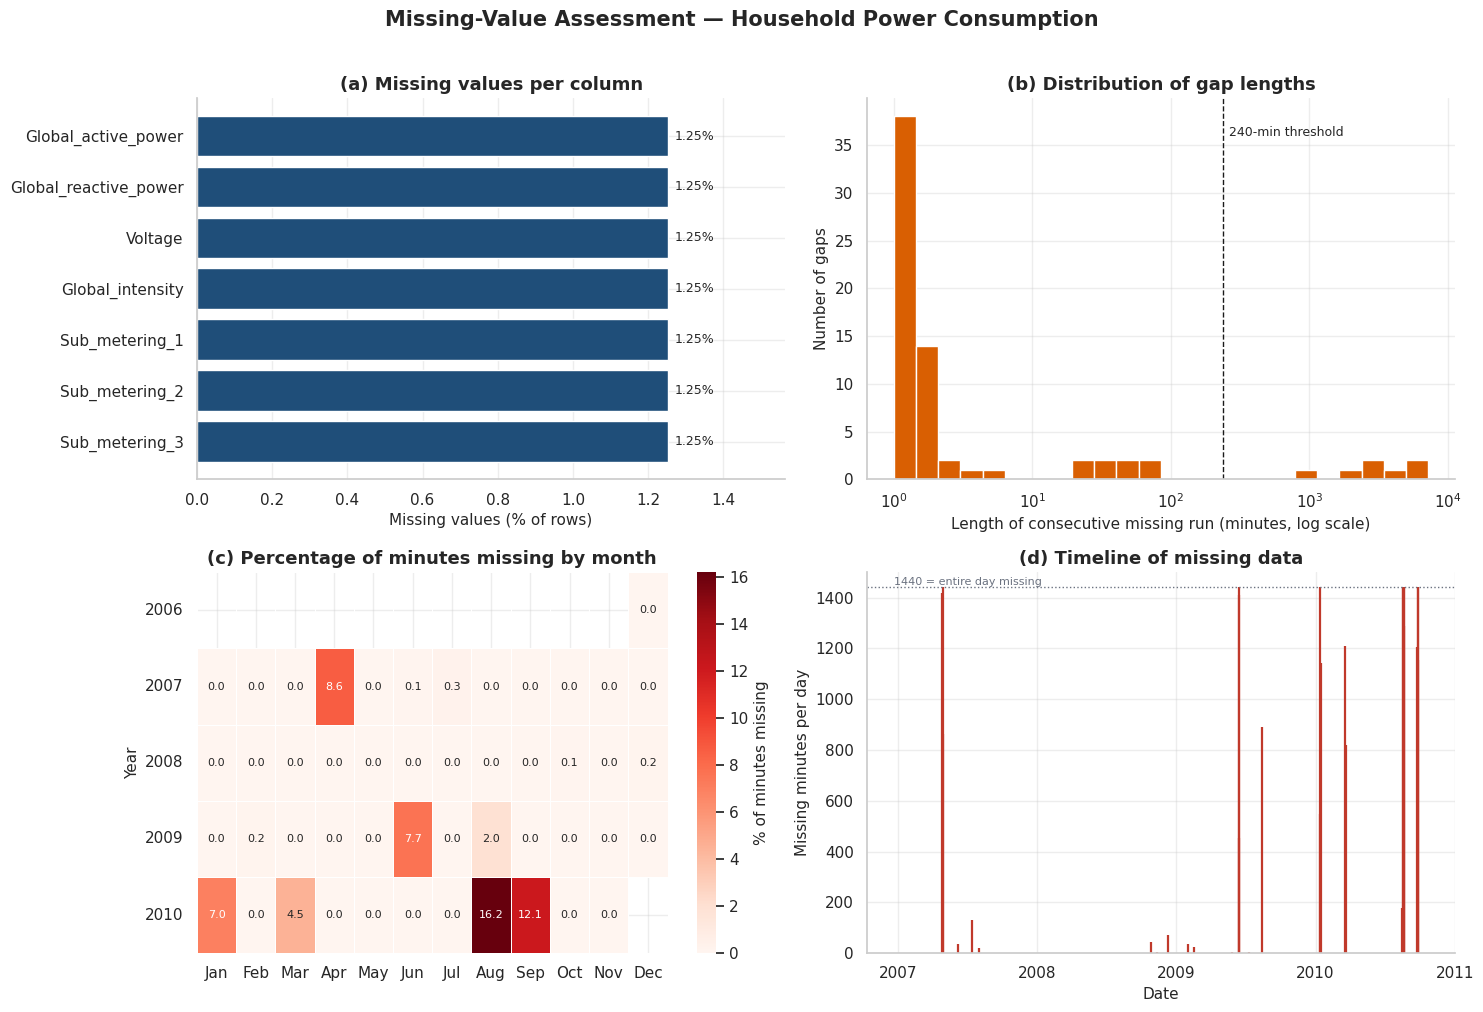

In [ ]:
# ----------------------------------------------------------------------------
# 4.2  MISSING-VALUE VISUALISATION
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) missing % per column
ax = axes[0, 0]
bars = ax.barh(FEATURES, miss["missing_%"], color=C["primary"])
ax.invert_yaxis()
for b, v in zip(bars, miss["missing_%"]):
    ax.text(v + 0.02, b.get_y() + b.get_height() / 2, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlim(0, miss["missing_%"].max() * 1.25)
ax.set_xlabel("Missing values (% of rows)"); ax.set_title("(a) Missing values per column")

# (b) gap-length distribution (log-spaced bins)
ax = axes[0, 1]
bins = np.logspace(0, np.log10(gaps["minutes"].max() + 1), 25)
ax.hist(gaps["minutes"], bins=bins, color=C["accent"], edgecolor="white")
ax.set_xscale("log")
ax.axvline(GAP_THRESHOLD_MIN, color="k", ls="--", lw=1)
ax.text(GAP_THRESHOLD_MIN * 1.1, ax.get_ylim()[1] * 0.9, f"{GAP_THRESHOLD_MIN}-min threshold", fontsize=9)
ax.set_xlabel("Length of consecutive missing run (minutes, log scale)")
ax.set_ylabel("Number of gaps"); ax.set_title("(b) Distribution of gap lengths")

# (c) year x month heatmap of % missing
ax = axes[1, 0]
pm = (is_na.groupby([df.index.year.rename("Year"), df.index.month.rename("Month")]).mean() * 100).unstack()
pm = pm.reindex(columns=range(1, 13))
sns.heatmap(pm, cmap="Reds", annot=True, fmt=".1f", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of minutes missing"}, ax=ax, annot_kws={"size": 8})
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0); ax.set_ylabel("Year"); ax.set_xlabel("")
ax.set_title("(c) Percentage of minutes missing by month")

# (d) daily missing minutes
ax = axes[1, 1]
daily_missing = is_na.resample("D").sum()
dm = daily_missing[daily_missing > 0]
ax.vlines(dm.index, 0, dm.values, color=C["red"], lw=1.6)          # one spike per day that has missing data
ax.set_ylim(0, 1500); ax.axhline(1440, color=C["grey"], ls=":", lw=1); ax.text(daily_missing.index[5], 1450, "1440 = entire day missing", fontsize=8, color=C["grey"])
ax.set_ylabel("Missing minutes per day"); ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("(d) Timeline of missing data")

fig.suptitle("Missing-Value Assessment — Household Power Consumption", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
save_fig(fig, "04_missing_values")

### 4.3 Duplicate records and validity checks

Two different notions of "duplicate" are relevant for a time series:
* **Duplicate timestamps** — two records for the same minute. This is a genuine error and would break the time index.
* **Duplicate value rows** — rows with identical measurements at different times. In power data this is *not* an error (e.g. a household in standby reports the same numbers for several minutes), so we only report it.

We also run **physical plausibility checks**:
* no negative power/energy/voltage,
* voltage within a sensible mains range,
* apparent power `S = V·I / 1000` (kVA) must be ≥ active power `P` (kW), since `P = S·cos φ ≤ S`. Note that `Global_intensity` is recorded with a coarse resolution of 0.2 A (≈ 0.047 kW at 235 V), so we allow a tolerance of **one resolution step**.

In [ ]:
# ----------------------------------------------------------------------------
# 4.3  DUPLICATES AND VALIDITY CHECKS
# ----------------------------------------------------------------------------
dup_ts        = int(df.index.duplicated().sum())
dup_rows_all  = int(df.duplicated().sum())
dup_rows_obs  = int(df.dropna().duplicated().sum())
print(f"Duplicate timestamps (genuine duplicates)      : {dup_ts:,}")
print(f"Duplicate value-rows (incl. all-NaN rows)      : {dup_rows_all:,}")
print(f"Duplicate value-rows among observed rows only  : {dup_rows_obs:,}  (legitimate repeated readings)")

obs = df.dropna()
print("\n--- Plausibility checks (observed rows only) ---")
print(f"Negative values in any column            : {(obs[FEATURES] < 0).sum().sum()}")
print(f"Voltage range                            : {obs['Voltage'].min():.1f} V  to  {obs['Voltage'].max():.1f} V")

# Global_intensity is stored in 0.2 A steps -> check this assumption, then allow one step of tolerance
INTENSITY_STEP = 0.2
on_grid = np.allclose(obs["Global_intensity"] / INTENSITY_STEP, np.round(obs["Global_intensity"] / INTENSITY_STEP), atol=1e-6)
print(f"Global_intensity recorded in {INTENSITY_STEP} A steps          : {on_grid}")

apparent       = obs["Voltage"] * obs["Global_intensity"] / 1000                      # kVA
apparent_upper = obs["Voltage"] * (obs["Global_intensity"] + INTENSITY_STEP) / 1000   # allow +1 resolution step
strict_viol = (obs[TARGET] > apparent).sum()
viol        = (obs[TARGET] > apparent_upper).sum()
print(f"Rows where P > S (strict, no tolerance)  : {strict_viol:,} ({strict_viol/len(obs)*100:.2f} %)  "
      f"| largest excess = {(obs[TARGET] - apparent).max():.3f} kW")
print(f"Rows where P > S even after +1 step      : {viol:,} ({viol/len(obs)*100:.3f} %)")

unmetered = obs[TARGET] * 1000 / 60 - obs[SUB_COLS].sum(axis=1)
print(f"Rows where sub-meters exceed total energy: {(unmetered < -1).sum():,} ({(unmetered < -1).mean()*100:.3f} %)  "
      "(tolerance 1 Wh for rounding)")

R.update(dup_ts=dup_ts, dup_rows_obs=dup_rows_obs, v_min=obs["Voltage"].min(), v_max=obs["Voltage"].max(),
         neg_vals=int((obs[FEATURES] < 0).sum().sum()), pq_viol=int(viol),
         pq_strict_pct=strict_viol / len(obs) * 100, pq_max_excess=(obs[TARGET] - apparent).max())

Duplicate timestamps (genuine duplicates)      : 0
Duplicate value-rows (incl. all-NaN rows)      : 168,560
Duplicate value-rows among observed rows only  : 142,582  (legitimate repeated readings)

--- Plausibility checks (observed rows only) ---
Negative values in any column            : 0
Voltage range                            : 223.2 V  to  254.2 V
Global_intensity recorded in 0.2 A steps          : True
Rows where P > S (strict, no tolerance)  : 807,379 (39.40 %)  | largest excess = 0.047 kW
Rows where P > S even after +1 step      : 0 (0.000 %)
Rows where sub-meters exceed total energy: 33 (0.002 %)  (tolerance 1 Wh for rounding)


In [ ]:
report_box("Data quality assessment", f"""
All seven measurement columns contain exactly {R['miss_count']:,} missing values ({R['miss_pct']:.2f}% of the records), and these always occur in the same rows. Missingness therefore stems from whole-row outages of the measurement system rather than from individual sensor failures. The missing minutes are grouped into {R['n_gaps']} distinct gaps. The distribution of gap lengths is extremely right-skewed: the median gap lasts {R['gap_median']:.0f} minute(s), whereas the longest lasts {R['gap_max']:,} minutes (approximately {R['gap_max']/1440:.1f} days). {R['n_long_gaps']} gaps exceed {GAP_THRESHOLD_MIN} minutes, and these few long outages account for the large majority of all missing minutes. The monthly heatmap and daily timeline show that the long outages are concentrated in a small number of specific periods rather than being spread evenly across the record, i.e. the data are not missing completely at random.

No duplicate timestamps were found ({R['dup_ts']}), so the time index is unique. Repeated value rows among the observed records ({R['dup_rows_obs']:,}) were not treated as duplicates because identical consecutive readings are physically plausible at one-minute resolution (e.g. standby consumption). Validity checks revealed no negative values; voltage stays within a realistic mains range ({R['v_min']:.0f}–{R['v_max']:.0f} V). Active power marginally exceeded the apparent power computed from voltage and current in {R['pq_strict_pct']:.1f}% of records, but never by more than {R['pq_max_excess']:.3f} kW; this is an artefact of the coarse 0.2 A resolution of the current measurement rather than a data error, and no record violates the physical constraint once one resolution step is allowed ({R['pq_viol']} violations). The sensor readings are therefore internally consistent.
""")

#### 📝 Report text — Data quality assessment

> All seven measurement columns contain exactly 25,979 missing values (1.25% of the records), and these always occur in the same rows. Missingness therefore stems from whole-row outages of the measurement system rather than from individual sensor failures. The missing minutes are grouped into 71 distinct gaps. The distribution of gap lengths is extremely right-skewed: the median gap lasts 1 minute(s), whereas the longest lasts 7,226 minutes (approximately 5.0 days). 7 gaps exceed 240 minutes, and these few long outages account for the large majority of all missing minutes. The monthly heatmap and daily timeline show that the long outages are concentrated in a small number of specific periods rather than being spread evenly across the record, i.e. the data are not missing completely at random.
>
> No duplicate timestamps were found (0), so the time index is unique. Repeated value rows among the observed records (142,582) were not treated as duplicates because identical consecutive readings are physically plausible at one-minute resolution (e.g. standby consumption). Validity checks revealed no negative values; voltage stays within a realistic mains range (223–254 V). Active power marginally exceeded the apparent power computed from voltage and current in 39.4% of records, but never by more than 0.047 kW; this is an artefact of the coarse 0.2 A resolution of the current measurement rather than a data error, and no record violates the physical constraint once one resolution step is allowed (0 violations). The sensor readings are therefore internally consistent.

---
# 5. Handling Missing Values

### 5.1 Choosing a method

| Candidate method | Verdict for this dataset |
|---|---|
| **Delete rows** | ❌ Breaks the regular time grid, corrupts lag features and seasonal structure. |
| **Global mean / median** | ❌ Ignores the strong daily/weekly cycle; flattens a multi-day gap to a constant. |
| **Forward / backward fill** | ⚠️ Acceptable for 1–2 minutes only; creates unrealistic flat lines for longer gaps. |
| **Linear / time interpolation** | ✅ Excellent for short gaps (the signal is autocorrelated over minutes to a few hours) — but for long gaps it just draws a straight line between two endpoints and removes all daily structure. |
| **Seasonal profile** (mean for the same *weekday × hour × minute*) | ✅ Reproduces the typical daily/weekly load shape — best for long outages. |
| Model-based (Kalman/ARIMA/ML) | Possible but over-engineered; harder to reproduce and validate for a 1.25 % problem. |

**Recommended: a hybrid strategy**

* **Short gaps (≤ 240 minutes = 4 h):** time-based linear interpolation.
* **Long gaps (> 240 minutes):** fill with the seasonal profile (average value for the same weekday, hour and minute).

The 240-minute switching point is not arbitrary: it comes from the masking experiment in §5.3 (it is set in the configuration block of §1).

**Leakage safeguard.** The seasonal profile is computed **only from the training period** (first 70 % of the timeline). Validation/test gaps are therefore filled using past information only, so no information from the evaluation periods leaks into training. (Short-gap interpolation uses only the immediately adjacent observations — a negligible, local effect.)

### 5.2 Build the seasonal profile
First we determine the training cut-off timestamp (the same one used for the split in §10, because the time grid is complete), then compute the weekday × hour × minute average over the observed training data.

In [ ]:
# ----------------------------------------------------------------------------
# 5.2  SEASONAL PROFILE (training period only -> no leakage)
# ----------------------------------------------------------------------------
n = len(df)
train_size = int(n * TRAIN_FRAC)
val_size   = int(n * VAL_FRAC)
train_cutoff = df.index[train_size - 1]          # last timestamp of the training set
print(f"Training period ends at {train_cutoff}  (used as the cut-off for the seasonal profile)")

tr = df.loc[:train_cutoff, FEATURES]
profile = tr.groupby([tr.index.dayofweek, tr.index.hour, tr.index.minute]).mean()
profile.index.names = ["dow", "hour", "minute"]
print(f"Seasonal profile: {len(profile):,} weekday-hour-minute slots (expected 7*24*60 = {7*24*60:,})")
print(f"Slots without any training observation: {profile.isna().any(axis=1).sum()}")

# Align the profile to every timestamp of the dataset
mi = pd.MultiIndex.from_arrays([df.index.dayofweek, df.index.hour, df.index.minute])
seasonal_all = profile.reindex(mi)
seasonal_all.index = df.index

Training period ends at 2009-09-20 12:44:00  (used as the cut-off for the seasonal profile)
Seasonal profile: 10,080 weekday-hour-minute slots (expected 7*24*60 = 10,080)
Slots without any training observation: 0


### 5.3 Empirical justification: which method is best for which gap length?

Instead of simply asserting that linear interpolation suits short gaps and the seasonal profile suits long gaps, we **test** it. We randomly choose fully-observed windows from the *post-training* period (so the seasonal profile never saw them), hide them artificially, reconstruct them with three methods and measure the root-mean-squared error (RMSE) against the true values, for several gap lengths. The experiment shows where the two approaches cross over, which is how the switching threshold (`GAP_THRESHOLD_MIN`, set in §1) was chosen.

,Linear interpolation,Forward fill,Seasonal profile
gap_minutes,,,
1,0.153,0.254,0.834
5,0.256,0.349,0.875
15,0.401,0.572,0.811
30,0.450,0.597,0.732
60,0.609,0.824,0.832
120,0.722,0.957,0.840
240,0.842,1.136,0.863
720,1.125,1.316,0.862
1440,1.163,1.254,0.839


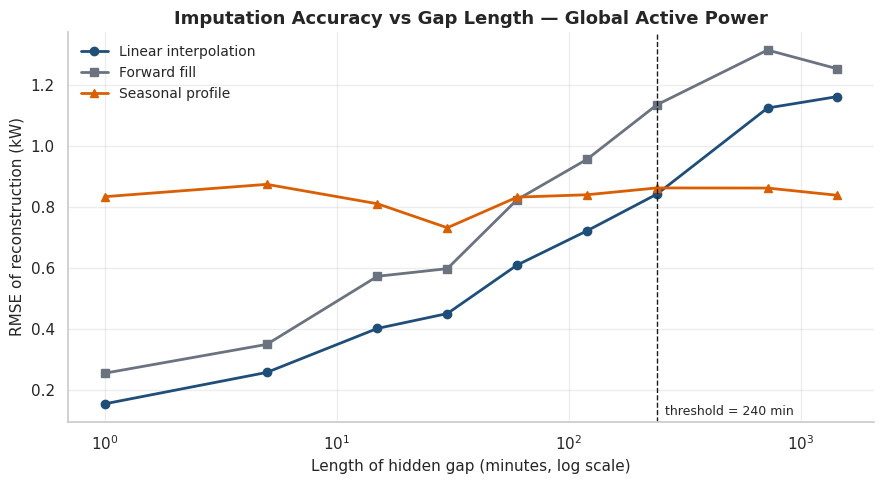

Seasonal profile first beats linear interpolation at a gap length of 720 min (linear is still better or equal at 240 min)
Best on average for gaps <= 240 min: Linear interpolation
Best on average for gaps  > 240 min: Seasonal profile


In [ ]:
# ----------------------------------------------------------------------------
# 5.3  MASKING EXPERIMENT — compare imputation methods by gap length
# ----------------------------------------------------------------------------
vals   = df[TARGET].to_numpy()
seas   = seasonal_all[TARGET].to_numpy()
valid  = ~np.isnan(vals)
cut_i  = train_size                                      # first non-training row
rng    = np.random.default_rng(RANDOM_SEED)

gap_lengths = [1, 5, 15, 30, 60, 120, 240, 720, 1440]
n_trials    = 300
rows = []
for L in gap_lengths:
    se = {"Linear interpolation": [], "Forward fill": [], "Seasonal profile": []}
    got, attempts = 0, 0
    while got < n_trials and attempts < 50_000:
        attempts += 1
        s = rng.integers(cut_i + 1, n - L - 2)
        if not valid[s - 1: s + L + 1].all():            # window and both neighbours must be observed
            continue
        truth = vals[s:s + L]
        pred_lin = np.linspace(vals[s - 1], vals[s + L], L + 2)[1:-1]
        pred_ff  = np.full(L, vals[s - 1])
        pred_sea = seas[s:s + L]
        se["Linear interpolation"].append(np.mean((truth - pred_lin) ** 2))
        se["Forward fill"].append(np.mean((truth - pred_ff) ** 2))
        se["Seasonal profile"].append(np.mean((truth - pred_sea) ** 2))
        got += 1
    rows.append({"gap_minutes": L, **{k: np.sqrt(np.mean(v)) for k, v in se.items()}})

exp = pd.DataFrame(rows).set_index("gap_minutes")
display(exp.style.format("{:.3f}").highlight_min(axis=1, color="#c7e9c0")
        .set_caption("RMSE (kW) of each imputation method on artificially hidden windows (lower is better)"))

fig, ax = plt.subplots(figsize=(9, 5))
for col, color, marker in zip(exp.columns, [C["primary"], C["grey"], C["accent"]], ["o", "s", "^"]):
    ax.plot(exp.index, exp[col], marker=marker, color=color, lw=2, label=col)
ax.axvline(GAP_THRESHOLD_MIN, color="k", ls="--", lw=1)
ax.text(GAP_THRESHOLD_MIN * 1.08, ax.get_ylim()[0] + 0.02, f"threshold = {GAP_THRESHOLD_MIN} min", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Length of hidden gap (minutes, log scale)")
ax.set_ylabel("RMSE of reconstruction (kW)")
ax.set_title("Imputation Accuracy vs Gap Length — Global Active Power")
ax.legend(); fig.tight_layout()
save_fig(fig, "05_imputation_experiment")

cross = exp.index[(exp["Seasonal profile"] < exp["Linear interpolation"])]
print(f"Seasonal profile first beats linear interpolation at a gap length of {cross.min()} min "
      f"(linear is still better or equal at {exp.index[exp.index < cross.min()].max()} min)")
best_short = exp.loc[exp.index <= GAP_THRESHOLD_MIN].mean().idxmin()
best_long  = exp.loc[exp.index > GAP_THRESHOLD_MIN].mean().idxmin()
print(f"Best on average for gaps <= {GAP_THRESHOLD_MIN} min: {best_short}")
print(f"Best on average for gaps  > {GAP_THRESHOLD_MIN} min: {best_long}")
R.update(best_short=best_short, best_long=best_long, crossover=int(cross.min()), cross_prev=int(exp.index[exp.index < cross.min()].max()))

### 5.4 Apply the hybrid imputation

Implementation:
1. Mark every missing row and measure the length of the run it belongs to.
2. **Short gaps** → `interpolate(method="time")` (uses the actual timestamps).
3. **Long gaps** → replace with the seasonal-profile values.
4. Add an `Imputed` flag (1 = value was reconstructed) so downstream models/evaluation can exclude or down-weight reconstructed periods.
5. Add the derived `Unmetered_Wh` column.
6. Assert that no missing values remain.

In [ ]:
# ----------------------------------------------------------------------------
# 5.4  HYBRID IMPUTATION
# ----------------------------------------------------------------------------
na_mask  = df[TARGET].isna()                                    # all columns are missing together
run_ids  = na_mask.ne(na_mask.shift()).cumsum()
run_len  = na_mask.groupby(run_ids).transform("sum")            # length of the gap each missing row belongs to
long_gap  = na_mask & (run_len > GAP_THRESHOLD_MIN)
short_gap = na_mask & ~long_gap

# Short gaps: time-weighted linear interpolation (only between observed neighbours)
df_clean = df[FEATURES].interpolate(method="time", limit_area="inside")
# Long gaps: seasonal profile (weekday x hour x minute mean from training data)
df_clean.loc[long_gap, FEATURES] = seasonal_all.loc[long_gap, FEATURES]

# Safety net for any edge case (e.g. missing at the very start/end of the series)
df_clean[FEATURES] = df_clean[FEATURES].ffill().bfill()

df_clean["Imputed"] = na_mask.astype("int8")
df_clean["Unmetered_Wh"] = df_clean[TARGET] * 1000 / 60 - df_clean[SUB_COLS].sum(axis=1)
NUMERIC = FEATURES + ["Unmetered_Wh"]

assert df_clean[NUMERIC].isna().sum().sum() == 0, "Missing values remain!"
print(f"Rows imputed with linear interpolation (short gaps) : {short_gap.sum():>7,}  ({short_gap.mean()*100:.3f} %)")
print(f"Rows imputed with seasonal profile    (long gaps)   : {long_gap.sum():>7,}  ({long_gap.mean()*100:.3f} %)")
print(f"Missing values remaining                            : {df_clean[NUMERIC].isna().sum().sum()}")

R.update(n_short_imputed=int(short_gap.sum()), n_long_imputed=int(long_gap.sum()))

Rows imputed with linear interpolation (short gaps) :     441  (0.021 %)
Rows imputed with seasonal profile    (long gaps)   :  25,538  (1.231 %)
Missing values remaining                            : 0


### 5.5 Validate the imputation
A good imputation must not distort the distribution. We compare summary statistics of the **observed** data with those of the **imputed** dataset, and plot the reconstruction for (left) the longest outage and (right) a medium-length gap.

Largest relative change of any column mean: 0.202 %


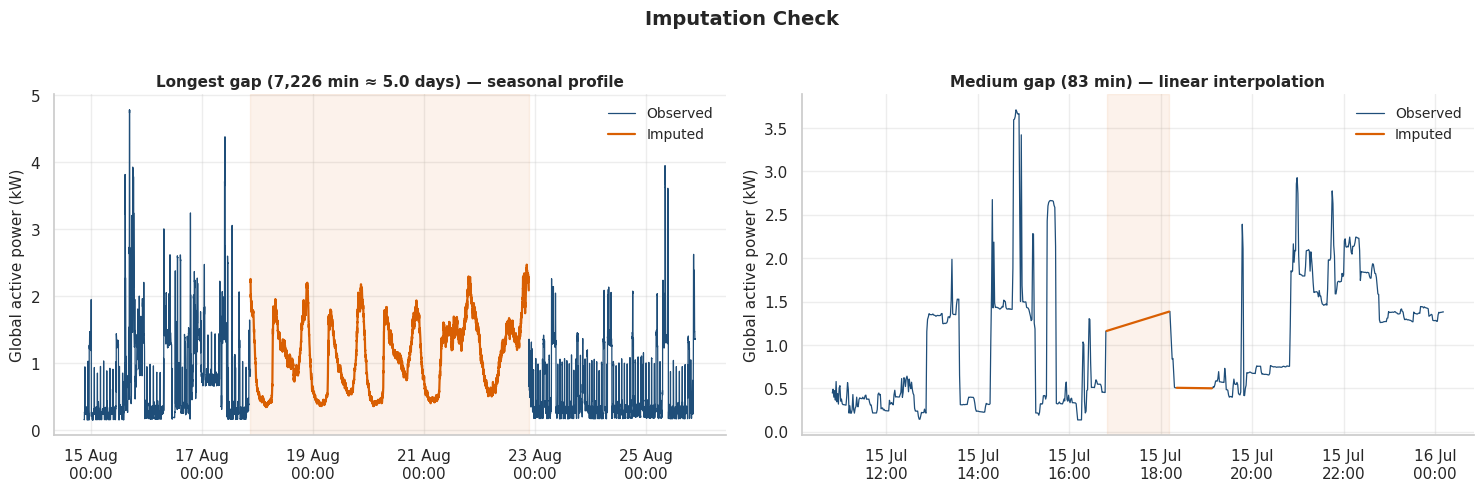

In [ ]:
# ----------------------------------------------------------------------------
# 5.5  VALIDATION — before vs after, and visual check
# ----------------------------------------------------------------------------
cmp = pd.concat({"observed": df[FEATURES].agg(["mean", "std", "median"]).T,
                 "after imputation": df_clean[FEATURES].agg(["mean", "std", "median"]).T}, axis=1)
display(cmp.style.format("{:.4f}").set_caption("Summary statistics before vs after imputation"))
max_rel = ((cmp["after imputation"]["mean"] - cmp["observed"]["mean"]).abs() / cmp["observed"]["mean"]).max() * 100
print(f"Largest relative change of any column mean: {max_rel:.3f} %")
R["max_mean_shift_pct"] = max_rel

# ---- visual check on two gaps ---------------------------------------------
g_long  = gaps.loc[gaps["minutes"].idxmax()]
g_mid   = gaps.iloc[(gaps["minutes"] - 120).abs().argsort().iloc[0]]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, g, pad, title in [(axes[0], g_long, pd.Timedelta(days=3), f"Longest gap ({g_long['minutes']:,} min ≈ {g_long['hours']/24:.1f} days) — seasonal profile"),
                          (axes[1], g_mid,  pd.Timedelta(hours=6), f"Medium gap ({g_mid['minutes']} min) — seasonal profile" if g_mid['minutes'] > GAP_THRESHOLD_MIN else f"Medium gap ({g_mid['minutes']} min) — linear interpolation")]:
    w = slice(g["start"] - pad, g["end"] + pad)
    seg = df_clean.loc[w]
    ax.plot(seg.index, seg[TARGET].where(seg["Imputed"] == 0), color=C["primary"], lw=.9, label="Observed")
    imp = seg[TARGET].where(seg["Imputed"] == 1)
    ax.plot(seg.index, imp, color=C["accent"], lw=1.6, label="Imputed")
    ax.axvspan(g["start"], g["end"], color=C["accent"], alpha=.08)
    ax.set_title(title, fontsize=11); ax.set_ylabel("Global active power (kW)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M")); ax.legend(loc="upper right")
fig.suptitle("Imputation Check", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout(); save_fig(fig, "05_imputation_check")

In [ ]:
report_box("Missing-value handling", f"""
Because the dataset is a regularly sampled time series, observations cannot simply be deleted without destroying the temporal structure on which lag-based and seasonal models rely. Global mean imputation was likewise rejected because it ignores the pronounced daily and weekly consumption cycle. A hybrid strategy was therefore adopted: gaps of up to {GAP_THRESHOLD_MIN} minutes (n = {R['n_short_imputed']:,} records) were filled by time-weighted linear interpolation, while longer outages (n = {R['n_long_imputed']:,} records) were filled with a seasonal profile, defined as the average value observed for the same weekday, hour and minute. To prevent information leakage the profile was computed exclusively from the training period (the first {TRAIN_FRAC:.0%} of the timeline).

The choice was validated empirically by artificially masking fully observed windows in the post-training period and measuring the reconstruction error (RMSE). {R['best_short']} produced the lowest average error for short gaps, whereas the {R['best_long'].lower()} was most accurate for long gaps, with the crossover between the two approaches lying between gap lengths of {R['cross_prev']} and {R['crossover']} minutes. The switching threshold was accordingly set to {GAP_THRESHOLD_MIN} minutes, the longest gap length at which interpolation was still the more accurate method. After imputation, no missing values remain and the largest relative change in any variable mean is only {R['max_mean_shift_pct']:.3f}%, indicating that the distribution of the data was not materially distorted. A limitation of the seasonal-profile fill is that, being an average, it is smoother than the real series and therefore slightly understates short-term variability during the reconstructed outages (visible in the imputation check figure); since these records represent only {R['n_long_imputed']/R['n_rows']*100:.1f}% of the data, the effect on overall statistics is small. A binary `Imputed` indicator was retained so that reconstructed periods can be excluded from model evaluation if desired.
""")

#### 📝 Report text — Missing-value handling

> Because the dataset is a regularly sampled time series, observations cannot simply be deleted without destroying the temporal structure on which lag-based and seasonal models rely. Global mean imputation was likewise rejected because it ignores the pronounced daily and weekly consumption cycle. A hybrid strategy was therefore adopted: gaps of up to 240 minutes (n = 441 records) were filled by time-weighted linear interpolation, while longer outages (n = 25,538 records) were filled with a seasonal profile, defined as the average value observed for the same weekday, hour and minute. To prevent information leakage the profile was computed exclusively from the training period (the first 70% of the timeline).
>
> The choice was validated empirically by artificially masking fully observed windows in the post-training period and measuring the reconstruction error (RMSE). Linear interpolation produced the lowest average error for short gaps, whereas the seasonal profile was most accurate for long gaps, with the crossover between the two approaches lying between gap lengths of 240 and 720 minutes. The switching threshold was accordingly set to 240 minutes, the longest gap length at which interpolation was still the more accurate method. After imputation, no missing values remain and the largest relative change in any variable mean is only 0.202%, indicating that the distribution of the data was not materially distorted. A limitation of the seasonal-profile fill is that, being an average, it is smoother than the real series and therefore slightly understates short-term variability during the reconstructed outages (visible in the imputation check figure); since these records represent only 1.2% of the data, the effect on overall statistics is small. A binary `Imputed` indicator was retained so that reconstructed periods can be excluded from model evaluation if desired.

---
# 6. Statistical Analysis

All statistics from here on are computed on the **imputed** dataset (`df_clean`, no missing values), unless stated otherwise.

### 6.1 Summary statistics
`describe()` gives count, mean, standard deviation, min/max and quartiles. We extend it with:
* the 1st/5th/95th/99th percentiles (tails of the distribution),
* **skewness** and **excess kurtosis** (asymmetry and tail weight; a normal distribution has 0 for both),
* the **coefficient of variation** (CV = std/mean; relative variability, comparable across variables with different units),
* the **share of exact zeros** (important for the sub-metering columns, which are zero whenever the appliances are off).

> *Why not a normality test?* With two million observations, any formal test (Shapiro–Wilk, Jarque–Bera, …) rejects normality for even trivial deviations, so skewness/kurtosis and plots are more informative.

In [ ]:
# ----------------------------------------------------------------------------
# 6.1  SUMMARY STATISTICS
# ----------------------------------------------------------------------------
desc = df_clean[NUMERIC].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
display(desc.style.format({"count": "{:,.0f}"}, precision=3).set_caption("describe() — imputed dataset"))

extra = pd.DataFrame({
    "skewness":        df_clean[NUMERIC].skew(),
    "excess_kurtosis": df_clean[NUMERIC].kurt(),
    "CV (std/mean)":   df_clean[NUMERIC].std() / df_clean[NUMERIC].mean(),
    "IQR":             df_clean[NUMERIC].quantile(.75) - df_clean[NUMERIC].quantile(.25),
    "zero_share_%":    (df_clean[NUMERIC] == 0).mean() * 100,
})
display(extra.style.format(precision=3).set_caption("Additional statistics"))

y = df_clean[TARGET]
R.update(gap_mean=y.mean(), gap_median=y.median(), gap_std=y.std(), gap_min=y.min(), gap_max=y.max(),
         gap_skew=y.skew(), gap_kurt=y.kurt(), gap_cv=y.std() / y.mean(),
         gap_p05=y.quantile(.05), gap_p95=y.quantile(.95), gap_p99=y.quantile(.99),
         share_below_05=(y < 0.5).mean() * 100, share_above_3=(y > 3).mean() * 100)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Global_active_power,"2,075,259",1.092,1.052,0.076,0.112,0.184,0.310,0.616,1.528,3.246,4.838,11.122
Global_reactive_power,"2,075,259",0.124,0.112,0.000,0.000,0.000,0.048,0.100,0.192,0.338,0.476,1.390
Voltage,"2,075,259",240.835,3.225,223.200,232.160,235.150,238.990,241.000,242.860,245.920,248.260,254.150
Global_intensity,"2,075,259",4.630,4.423,0.200,0.600,0.800,1.400,2.800,6.400,13.800,20.600,48.400
Sub_metering_1,"2,075,259",1.124,6.117,0.000,0.000,0.000,0.000,0.000,0.000,1.000,38.000,88.000
Sub_metering_2,"2,075,259",1.300,5.787,0.000,0.000,0.000,0.000,0.000,1.000,2.000,36.000,80.000
Sub_metering_3,"2,075,259",6.455,8.395,0.000,0.000,0.000,0.000,1.000,17.000,19.000,20.000,31.000
Unmetered_Wh,"2,075,259",9.322,9.541,-2.400,1.200,2.033,3.833,5.533,10.400,30.267,44.667,124.833


,skewness,excess_kurtosis,CV (std/mean),IQR,zero_share_%
Global_active_power,1.789,4.265,0.964,1.218,0.000
Global_reactive_power,1.268,2.664,0.906,0.144,23.205
Voltage,-0.324,0.749,0.013,3.870,0.000
Global_intensity,1.852,4.649,0.955,5.000,0.000
Sub_metering_1,5.975,36.070,5.441,0.000,90.782
Sub_metering_2,7.128,58.594,4.451,1.000,69.247
Sub_metering_3,0.728,-1.267,1.300,17.000,41.070
Unmetered_Wh,2.491,7.978,1.024,6.567,0.001


### 6.2 Energy totals, consumption structure and temporal dependence

Since active power is a *rate* (kW) and each record covers one minute, the energy consumed in a minute is `kW / 60` kWh. Summing gives total consumption. We also decompose the load into the three sub-metered circuits and the unmetered remainder, report yearly statistics (only 2007–2009 are complete calendar years) and quantify **autocorrelation** — the correlation of the series with its own past — at lags of 1 minute, 1 hour, 1 day and 1 week.

In [ ]:
# ----------------------------------------------------------------------------
# 6.2  ENERGY TOTALS, LOAD STRUCTURE, YEARLY STATS, AUTOCORRELATION
# ----------------------------------------------------------------------------
total_kwh  = y.sum() / 60
days_total = len(y) / 1440
print(f"Total active energy over the period : {total_kwh:,.0f} kWh")
print(f"Average daily consumption           : {total_kwh / days_total:.1f} kWh/day")
print(f"Average power                       : {y.mean():.3f} kW")

# Load structure (energy shares)
energy_wh = pd.concat([df_clean[SUB_COLS].sum(), pd.Series({"Unmetered_Wh": df_clean["Unmetered_Wh"].sum()})])
share = (energy_wh / energy_wh.sum() * 100).rename("share_of_total_%")
share.index = ["Kitchen (Sub_metering_1)", "Laundry (Sub_metering_2)", "Water-heater & A/C (Sub_metering_3)", "Unmetered remainder"]
display(share.to_frame().style.format("{:.1f}"))

# Yearly statistics (complete years: 2007-2009)
yearly = y.groupby(y.index.year).agg(["mean", "median", "std", "max", "count"])
yearly["kWh_per_day"] = yearly["mean"] * 24
yearly["complete_year"] = [yr in (2007, 2008, 2009) for yr in yearly.index]
display(yearly.style.format({"mean": "{:.3f}", "median": "{:.3f}", "std": "{:.3f}", "max": "{:.2f}",
                             "count": "{:,.0f}", "kWh_per_day": "{:.1f}"}).set_caption("Global active power by calendar year (kW)"))

# Temporal dependence
acf_vals = {lag: y.autocorr(lag) for lag in (1, 60, 1440, 10080)}
print("\nAutocorrelation of the minute-level target:")
for lag, v in acf_vals.items():
    print(f"  lag {lag:>6} min ({pd.Timedelta(minutes=lag)})  ->  r = {v:.3f}")

R.update(total_kwh=total_kwh, daily_kwh=total_kwh / days_total, share=share.to_dict(),
         acf1=acf_vals[1], acf60=acf_vals[60], acf1440=acf_vals[1440], acf10080=acf_vals[10080],
         yearly=yearly)

Total active energy over the period : 37,773 kWh
Average daily consumption           : 26.2 kWh/day
Average power                       : 1.092 kW


,share_of_total_%
Kitchen (Sub_metering_1),6.2
Laundry (Sub_metering_2),7.1
Water-heater & A/C (Sub_metering_3),35.5
Unmetered remainder,51.2


,mean,median,std,max,count,kWh_per_day,complete_year
Datetime,,,,,,,
2006,1.902,1.708,1.419,9.13,"21,996",45.6,False
2007,1.117,0.512,1.159,10.67,"525,600",26.8,True
2008,1.072,0.566,1.065,10.35,"527,040",25.7,True
2009,1.079,0.630,1.006,11.12,"525,600",25.9,True
2010,1.063,0.736,0.921,9.72,"475,023",25.5,False



Autocorrelation of the minute-level target:
  lag      1 min (0 days 00:01:00)  ->  r = 0.968
  lag     60 min (0 days 01:00:00)  ->  r = 0.494
  lag   1440 min (1 days 00:00:00)  ->  r = 0.327
  lag  10080 min (7 days 00:00:00)  ->  r = 0.348


In [ ]:
sh = R["share"]
report_box("Statistical analysis", f"""
Global active power has a mean of {R['gap_mean']:.3f} kW and a median of {R['gap_median']:.3f} kW, with a standard deviation of {R['gap_std']:.3f} kW (coefficient of variation {R['gap_cv']:.2f}). The mean exceeds the median, and the distribution is strongly right-skewed (skewness = {R['gap_skew']:.2f}, excess kurtosis = {R['gap_kurt']:.2f}): for most of the time the household draws a low base load ({R['share_below_05']:.1f}% of minutes are below 0.5 kW), punctuated by short, high-power events that reach a maximum of {R['gap_max']:.2f} kW ({R['share_above_3']:.1f}% of minutes exceed 3 kW). Over the whole period the household consumed approximately {R['total_kwh']:,.0f} kWh, i.e. {R['daily_kwh']:.1f} kWh per day on average.

The load is dominated by consumption that is not captured by the sub-meters ({sh['Unmetered remainder']:.1f}% of active energy), followed by the water-heater and air-conditioner circuit ({sh['Water-heater & A/C (Sub_metering_3)']:.1f}%), the laundry circuit ({sh['Laundry (Sub_metering_2)']:.1f}%) and the kitchen ({sh['Kitchen (Sub_metering_1)']:.1f}%). The sub-metering variables are zero-inflated and highly skewed, because the appliances they monitor are off for most of the time. The target series is highly persistent: the autocorrelation is {R['acf1']:.2f} at a lag of one minute, {R['acf60']:.2f} at one hour, {R['acf1440']:.2f} at one day and {R['acf10080']:.2f} at one week, which already indicates a strong daily rhythm (the day-lag correlation is higher than the hour-lag correlation) and suggests that lagged and seasonal features will be valuable for forecasting.
""")

#### 📝 Report text — Statistical analysis

> Global active power has a mean of 1.092 kW and a median of 0.616 kW, with a standard deviation of 1.052 kW (coefficient of variation 0.96). The mean exceeds the median, and the distribution is strongly right-skewed (skewness = 1.79, excess kurtosis = 4.27): for most of the time the household draws a low base load (46.3% of minutes are below 0.5 kW), punctuated by short, high-power events that reach a maximum of 11.12 kW (6.1% of minutes exceed 3 kW). Over the whole period the household consumed approximately 37,773 kWh, i.e. 26.2 kWh per day on average.
>
> The load is dominated by consumption that is not captured by the sub-meters (51.2% of active energy), followed by the water-heater and air-conditioner circuit (35.5%), the laundry circuit (7.1%) and the kitchen (6.2%). The sub-metering variables are zero-inflated and highly skewed, because the appliances they monitor are off for most of the time. The target series is highly persistent: the autocorrelation is 0.97 at a lag of one minute, 0.49 at one hour, 0.33 at one day and 0.35 at one week, which already indicates a strong daily rhythm (the day-lag correlation is higher than the hour-lag correlation) and suggests that lagged and seasonal features will be valuable for forecasting.

---
# 7. Exploratory Data Analysis Visualisations

Plotting 2 million minute-level points directly is slow and visually uninformative (the plot becomes a solid block of ink). We therefore work at **several resolutions** — minute, hourly, daily and monthly aggregates — chosen to suit each question. All aggregates are simple means of the imputed minute data.

In [ ]:
# ----------------------------------------------------------------------------
# 7.0  RESAMPLED VIEWS USED BY THE PLOTS
# ----------------------------------------------------------------------------
hourly  = df_clean[NUMERIC].resample("h").mean()
daily   = df_clean[NUMERIC].resample("D").mean()
monthly = df_clean[NUMERIC].resample("ME").mean()

MONTHS   = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
DAYS     = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
SEASON_OF = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
             6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]

print(f"hourly : {hourly.shape}   daily : {daily.shape}   monthly : {monthly.shape}")

hourly : (34589, 8)   daily : (1442, 8)   monthly : (48, 8)


### 7A. Time-series line plot of the target variable

**What to look for:** long-term trend, seasonality, level shifts, unusual spikes, and the periods that were reconstructed.  
*Top:* daily mean power over the full period with a 30-day centred moving average; imputed long gaps are shaded. *Bottom:* a one-week minute-level zoom showing the intraday dynamics hidden by aggregation.

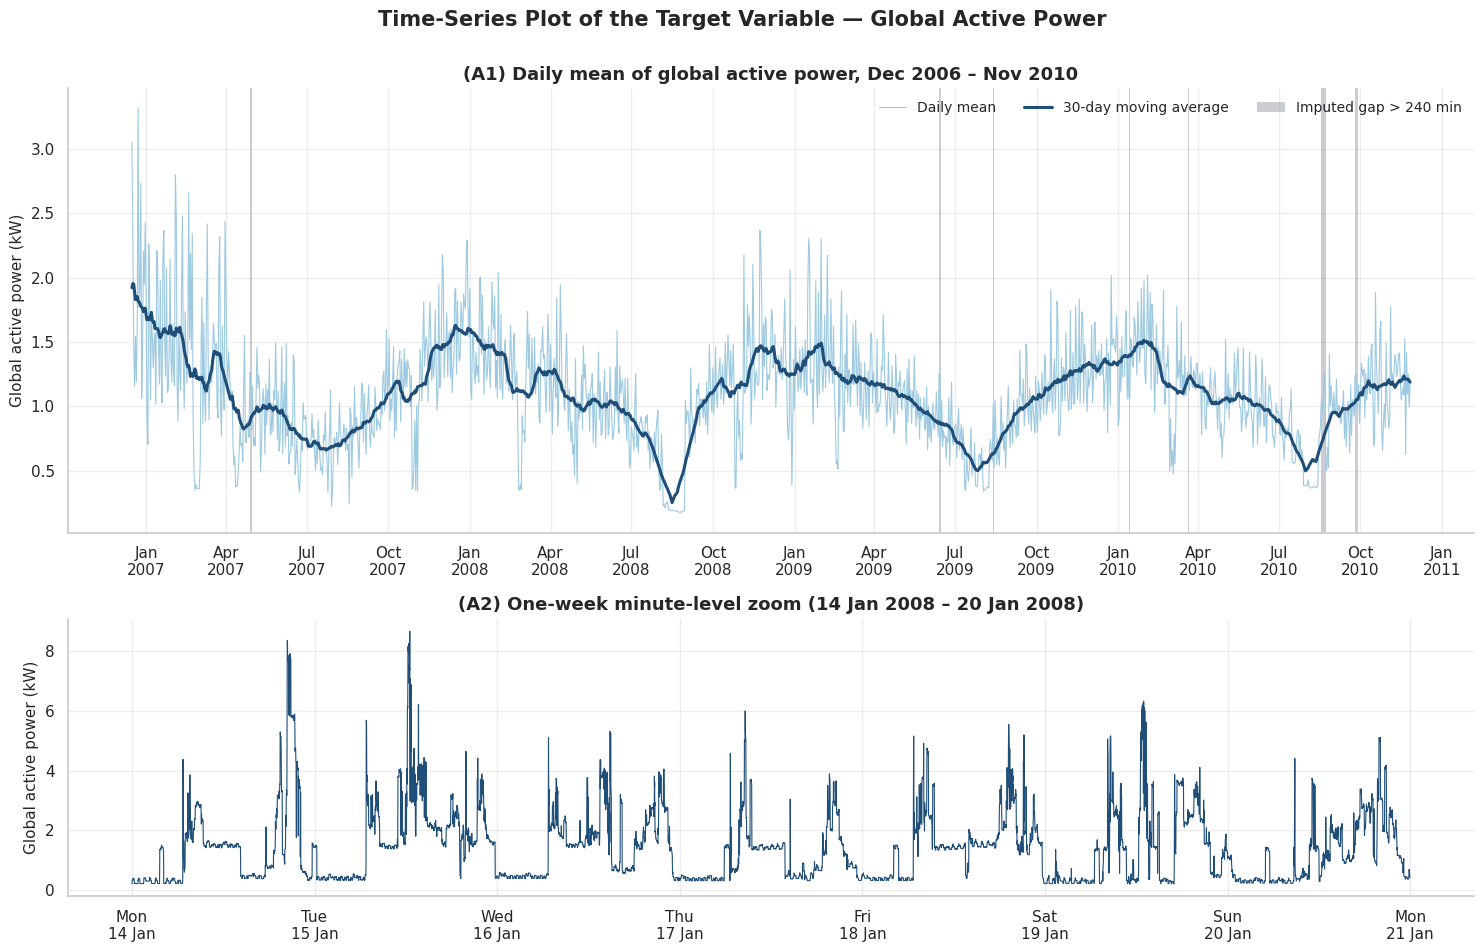

In [ ]:
# ----------------------------------------------------------------------------
# 7A. TIME-SERIES LINE PLOT
# ----------------------------------------------------------------------------
roll30 = daily[TARGET].rolling(30, center=True, min_periods=15).mean()
long_tbl = gaps[gaps["minutes"] > GAP_THRESHOLD_MIN]

# pick a fully observed week in 2008 for the minute-level zoom
weeks = pd.date_range("2008-01-07", "2008-12-29", freq="7D")
wk = min(weeks, key=lambda d: df_clean.loc[d:d + pd.Timedelta(days=7), "Imputed"].sum())
zoom = df_clean.loc[wk: wk + pd.Timedelta(days=7) - pd.Timedelta(minutes=1)]

fig, axes = plt.subplots(2, 1, figsize=(15, 9.5), gridspec_kw={"height_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(daily.index, daily[TARGET], color=C["light"], lw=.8, label="Daily mean")
ax.plot(roll30.index, roll30, color=C["primary"], lw=2.2, label="30-day moving average")
for i, g in long_tbl.iterrows():
    ax.axvspan(g["start"], g["end"], color=C["grey"], alpha=.35, lw=0,
               label=f"Imputed gap > {GAP_THRESHOLD_MIN} min" if i == long_tbl.index[0] else None)
ax.set_ylabel("Global active power (kW)")
ax.set_title("(A1) Daily mean of global active power, Dec 2006 – Nov 2010")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(loc="upper right", ncol=3)

ax = axes[1]
ax.plot(zoom.index, zoom[TARGET], color=C["primary"], lw=.8)
ax.set_ylabel("Global active power (kW)")
ax.set_title(f"(A2) One-week minute-level zoom ({wk:%d %b %Y} – {(wk + pd.Timedelta(days=6)):%d %b %Y})")
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
fig.suptitle("Time-Series Plot of the Target Variable — Global Active Power", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "07A_timeseries_line")

**Interactive version (Plotly).** Hover to read exact values, drag to zoom, and use the range slider to inspect any period. (Plotly output is interactive in Jupyter/VS Code; it will not render on static viewers such as GitHub's notebook preview — the matplotlib figure above is the static equivalent.)

In [ ]:
# ----------------------------------------------------------------------------
# 7A (interactive). PLOTLY — daily mean with range slider
# ----------------------------------------------------------------------------
fig_i = go.Figure()
fig_i.add_trace(go.Scatter(x=daily.index, y=daily[TARGET], mode="lines", name="Daily mean",
                           line=dict(color=C["light"], width=1)))
fig_i.add_trace(go.Scatter(x=roll30.index, y=roll30, mode="lines", name="30-day moving average",
                           line=dict(color=C["primary"], width=2.5)))
fig_i.update_layout(template="plotly_white", height=430, title="Daily Mean Global Active Power (interactive)",
                    yaxis_title="Global active power (kW)", xaxis_title="Date",
                    xaxis=dict(rangeslider=dict(visible=True)), legend=dict(orientation="h", y=1.12),
                    margin=dict(l=60, r=20, t=70, b=40))
fig_i.show()

In [ ]:
# facts for the interpretation
ann = daily[TARGET].groupby(daily.index.year).mean()
R["ann_means"] = ann.to_dict()
hi_day, lo_day = daily[TARGET].idxmax(), daily[TARGET].idxmin()
roll_in = roll30.loc["2007-01-15":"2010-11-10"]                 # ignore edge effects of the partial first/last weeks
R.update(hi_day=hi_day, hi_day_v=daily[TARGET].max(), lo_day=lo_day, lo_day_v=daily[TARGET].min(),
         roll_max_date=roll_in.idxmax(), roll_min_date=roll_in.idxmin(),
         ann_change=(ann[2009] / ann[2007] - 1) * 100)
report_box("Time-series plot (Figure 7A)", f"""
Figure 7A shows the daily mean active power over almost four years. The series fluctuates around its long-run mean of {R['gap_mean']:.2f} kW with a clear, recurring annual pattern: the 30-day moving average is highest in the colder months (maximum around {R['roll_max_date']:%B %Y}) and lowest in the summer holiday period (minimum around {R['roll_min_date']:%B %Y}). Day-to-day variability around the moving average is substantial, and the daily mean ranges from {R['lo_day_v']:.2f} kW ({R['lo_day']:%d %b %Y}) to {R['hi_day_v']:.2f} kW ({R['hi_day']:%d %b %Y}). The annual means for the three complete years are {R['ann_means'][2007]:.2f} kW (2007), {R['ann_means'][2008]:.2f} kW (2008) and {R['ann_means'][2009]:.2f} kW (2009), so there is no strong long-term trend: consumption is {abs(R['ann_change']):.1f}% {'lower' if R['ann_change'] < 0 else 'higher'} in 2009 than in 2007, with most of the change occurring between 2007 and 2008. The shaded areas mark the long measurement outages that were reconstructed with the seasonal profile. The exceptionally low values in August 2008 are genuine observations, not imputed data, and most likely correspond to an extended absence of the occupants. The one-week zoom reveals the intraday structure that daily averaging conceals: consumption is dominated by a low overnight base load interrupted by sharp, short-lived peaks, typically in the morning and evening.
""")

#### 📝 Report text — Time-series plot (Figure 7A)

> Figure 7A shows the daily mean active power over almost four years. The series fluctuates around its long-run mean of 1.09 kW with a clear, recurring annual pattern: the 30-day moving average is highest in the colder months (maximum around December 2007) and lowest in the summer holiday period (minimum around August 2008). Day-to-day variability around the moving average is substantial, and the daily mean ranges from 0.17 kW (25 Aug 2008) to 3.31 kW (23 Dec 2006). The annual means for the three complete years are 1.12 kW (2007), 1.07 kW (2008) and 1.08 kW (2009), so there is no strong long-term trend: consumption is 3.4% lower in 2009 than in 2007, with most of the change occurring between 2007 and 2008. The shaded areas mark the long measurement outages that were reconstructed with the seasonal profile. The exceptionally low values in August 2008 are genuine observations, not imputed data, and most likely correspond to an extended absence of the occupants. The one-week zoom reveals the intraday structure that daily averaging conceals: consumption is dominated by a low overnight base load interrupted by sharp, short-lived peaks, typically in the morning and evening.

### 7B. Histogram of the target variable

**What to look for:** shape (symmetry, skew, modality), the typical operating level, and the tail. The right panel repeats the plot on a **logarithmic y-axis**, which makes the sparse high-power tail visible.

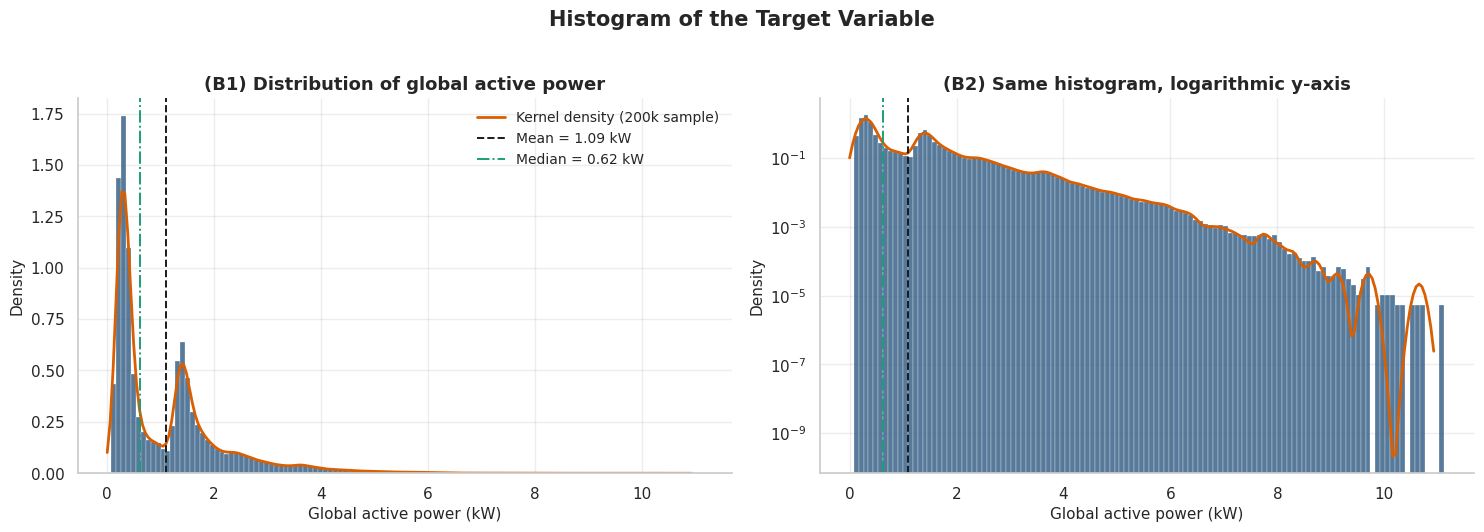

In [ ]:
# ----------------------------------------------------------------------------
# 7B. HISTOGRAM OF THE TARGET
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
kde_sample = y.sample(200_000, random_state=RANDOM_SEED)           # KDE on a sample for speed
for ax, logy in zip(axes, [False, True]):
    sns.histplot(y, bins=120, stat="density", color=C["primary"], edgecolor="white", linewidth=.2, ax=ax)
    sns.kdeplot(kde_sample, color=C["accent"], lw=2, ax=ax, label="Kernel density (200k sample)", clip=(0, None))
    ax.axvline(y.mean(),   color="k", ls="--", lw=1.4, label=f"Mean = {y.mean():.2f} kW")
    ax.axvline(y.median(), color=C["green"], ls="-.", lw=1.4, label=f"Median = {y.median():.2f} kW")
    ax.set_xlabel("Global active power (kW)"); ax.set_ylabel("Density")
    if logy:
        ax.set_yscale("log"); ax.set_title("(B2) Same histogram, logarithmic y-axis")
    else:
        ax.set_title("(B1) Distribution of global active power"); ax.legend(loc="upper right")
fig.suptitle("Histogram of the Target Variable", fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout(); save_fig(fig, "07B_histogram")

counts, edges = np.histogram(y, bins=120)
centers = (edges[:-1] + edges[1:]) / 2
R["hist_mode"]  = centers[counts.argmax()]                                  # global mode (standby load)
R["hist_mode2"] = centers[(centers > 1.0)][counts[centers > 1.0].argmax()]  # highest peak above 1 kW (secondary mode)

In [ ]:
report_box("Histogram (Figure 7B)", f"""
The histogram of global active power is strongly right-skewed, non-normal and **bimodal**. The dominant mode lies at about {R['hist_mode']:.2f} kW, which corresponds to the household's standby (base) load, and a second, distinct mode appears at about {R['hist_mode2']:.1f} kW. The latter is consistent with the water-heater/air-conditioner circuit being switched on (this circuit's sub-meter shows a second mode near 18 Wh per minute, i.e. about 1.1 kW, see Figure 7E), so the series behaves like a mixture of operating regimes rather than a single noisy level. The mean ({R['gap_mean']:.2f} kW) lies to the right of the median ({R['gap_median']:.2f} kW) because a small number of high-power minutes pull the average upwards. The logarithmic view shows a long, gradually decaying tail extending beyond 6 kW (only {(y > 6).mean()*100:.2f}% of minutes exceed it), reflecting the simultaneous operation of several heavy appliances. Because of this skewness, error metrics that are dominated by large values (e.g. RMSE) will be driven by the peaks, and a variance-stabilising transformation (e.g. log or square-root) may be worth testing during modelling.
""")

#### 📝 Report text — Histogram (Figure 7B)

> The histogram of global active power is strongly right-skewed, non-normal and **bimodal**. The dominant mode lies at about 0.31 kW, which corresponds to the household's standby (base) load, and a second, distinct mode appears at about 1.4 kW. The latter is consistent with the water-heater/air-conditioner circuit being switched on (this circuit's sub-meter shows a second mode near 18 Wh per minute, i.e. about 1.1 kW, see Figure 7E), so the series behaves like a mixture of operating regimes rather than a single noisy level. The mean (1.09 kW) lies to the right of the median (0.62 kW) because a small number of high-power minutes pull the average upwards. The logarithmic view shows a long, gradually decaying tail extending beyond 6 kW (only 0.26% of minutes exceed it), reflecting the simultaneous operation of several heavy appliances. Because of this skewness, error metrics that are dominated by large values (e.g. RMSE) will be driven by the peaks, and a variance-stabilising transformation (e.g. log or square-root) may be worth testing during modelling.

### 7C. Boxplot of the target variable

**What to look for:** median and spread (box = interquartile range, whiskers = 1.5 × IQR), the proportion of points flagged as outliers by Tukey's rule, and whether the distribution changes between years. *Note: 2006 and 2010 are partial years.*

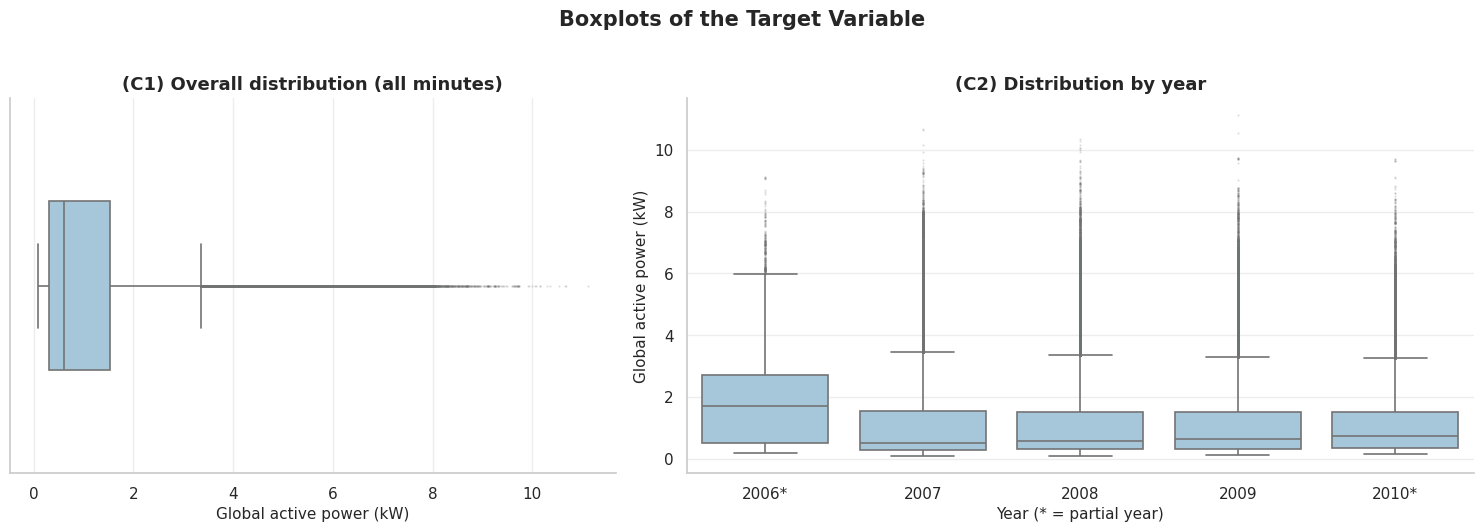

,q1,median,q3,std
Datetime,,,,
2006,0.496,1.708,2.694,1.419
2007,0.280,0.512,1.548,1.159
2008,0.300,0.566,1.518,1.065
2009,0.320,0.630,1.514,1.006
2010,0.340,0.736,1.512,0.921


In [ ]:
# ----------------------------------------------------------------------------
# 7C. BOXPLOT OF THE TARGET
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
flier = dict(marker=".", markersize=1.5, markerfacecolor=C["grey"], alpha=.15, linestyle="none")

sns.boxplot(x=y, ax=axes[0], color=C["light"], width=.45, flierprops=flier, linewidth=1.2)
axes[0].set_xlabel("Global active power (kW)"); axes[0].set_yticks([])
axes[0].set_title("(C1) Overall distribution (all minutes)")

yr = pd.Series(y.index.year, index=y.index).map(lambda v: f"{v}" + ("*" if v in (2006, 2010) else ""))
sns.boxplot(x=yr.values, y=y.values, ax=axes[1], color=C["light"], flierprops=flier, linewidth=1.2,
            order=sorted(yr.unique()))
axes[1].set_xlabel("Year (* = partial year)"); axes[1].set_ylabel("Global active power (kW)")
axes[1].set_title("(C2) Distribution by year")
fig.suptitle("Boxplots of the Target Variable", fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout(); save_fig(fig, "07C_boxplot")

q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
R.update(q1=q1, q3=q3, iqr=iqr, upper_fence=q3 + 1.5 * iqr, share_above_fence=(y > q3 + 1.5 * iqr).mean() * 100)
yq = y.groupby(y.index.year).quantile([.25, .5, .75]).unstack(); yq.columns = ["q1", "median", "q3"]
yq["std"] = y.groupby(y.index.year).std(); R["yq"] = yq; display(yq.style.format("{:.3f}").set_caption("Quartiles and std of the target by year (kW)"))

In [ ]:
report_box("Boxplot (Figure 7C)", f"""
The overall boxplot shows a compact interquartile range from {R['q1']:.2f} kW to {R['q3']:.2f} kW (IQR = {R['iqr']:.2f} kW) with a median of {R['gap_median']:.2f} kW, but an extensive set of points above the upper whisker at {R['upper_fence']:.2f} kW. Under Tukey's rule {R['share_above_fence']:.1f}% of all minutes are flagged as unusually high; there are no flagged points on the lower side because the distribution is bounded by zero. This asymmetry is consistent with the right-skewed histogram. Comparing years reveals a gradual change in the *shape* of the distribution that is not visible in the annual means: the median rises steadily from {R['yq'].loc[2007,'median']:.2f} kW in 2007 to {R['yq'].loc[2009,'median']:.2f} kW in 2009 and {R['yq'].loc[2010,'median']:.2f} kW in 2010, while the standard deviation falls from {R['yq'].loc[2007,'std']:.2f} kW to {R['yq'].loc[2010,'std']:.2f} kW. In other words, the household's base load has increased and its peaks have become less extreme, leaving the mean almost unchanged. (The 2006 box is shifted upwards because it covers only 16 December days, starting in the evening.) This mild non-stationarity of the distribution is relevant for forecasting, because the most recent period (including the test set) is not statistically identical to the early training years.
""")

#### 📝 Report text — Boxplot (Figure 7C)

> The overall boxplot shows a compact interquartile range from 0.31 kW to 1.53 kW (IQR = 1.22 kW) with a median of 0.62 kW, but an extensive set of points above the upper whisker at 3.35 kW. Under Tukey's rule 4.6% of all minutes are flagged as unusually high; there are no flagged points on the lower side because the distribution is bounded by zero. This asymmetry is consistent with the right-skewed histogram. Comparing years reveals a gradual change in the *shape* of the distribution that is not visible in the annual means: the median rises steadily from 0.51 kW in 2007 to 0.63 kW in 2009 and 0.74 kW in 2010, while the standard deviation falls from 1.16 kW to 0.92 kW. In other words, the household's base load has increased and its peaks have become less extreme, leaving the mean almost unchanged. (The 2006 box is shifted upwards because it covers only 16 December days, starting in the evening.) This mild non-stationarity of the distribution is relevant for forecasting, because the most recent period (including the test set) is not statistically identical to the early training years.

### 7D. Correlation heatmap of numerical features

**Pearson** correlation measures *linear* association; **Spearman** uses ranks and captures any *monotonic* association (more robust to the heavy tails here). Spearman is computed on a 300,000-row random sample for speed. The upper triangle is hidden because the matrix is symmetric.

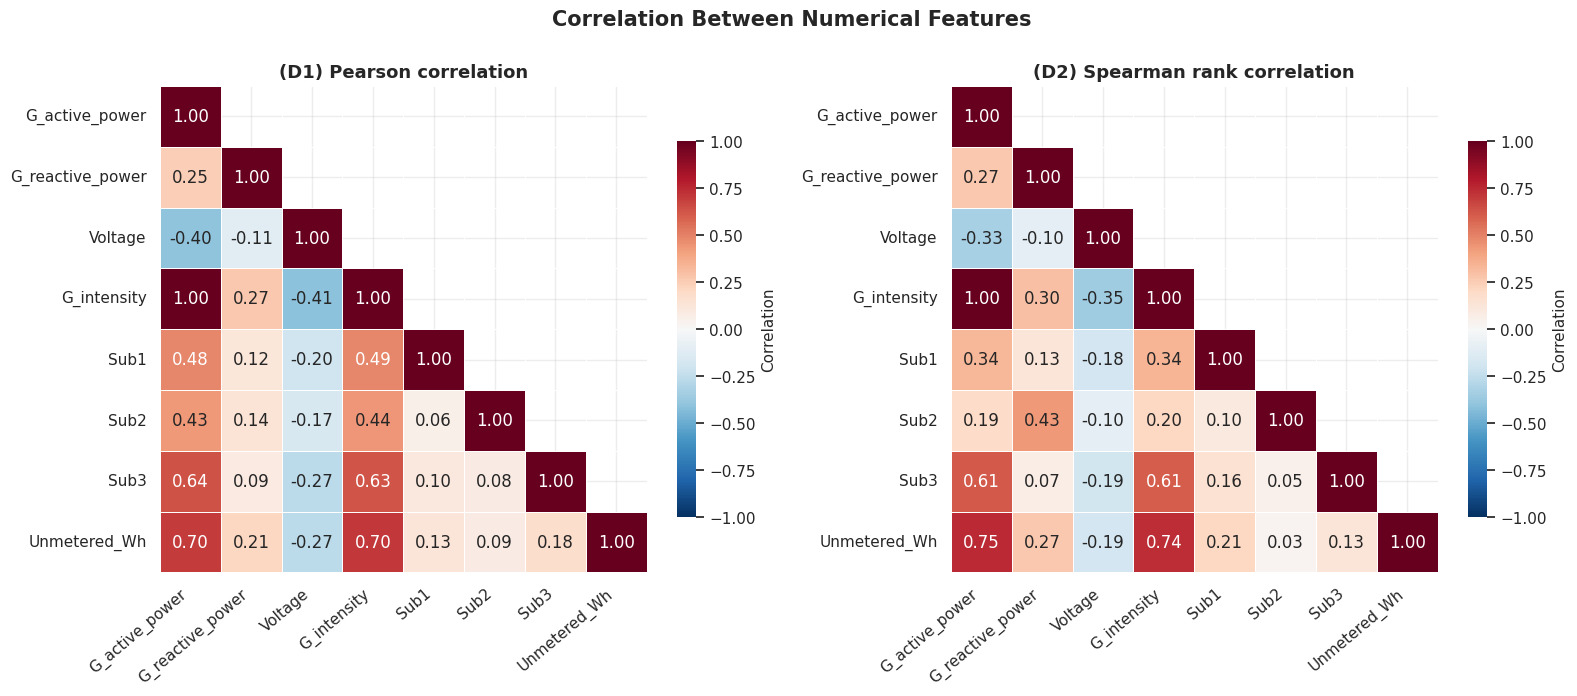

Pearson correlation with the target:


,r
Global_intensity,0.999
Unmetered_Wh,0.702
Sub_metering_3,0.639
Sub_metering_1,0.485
Sub_metering_2,0.435
Voltage,-0.401
Global_reactive_power,0.248


In [ ]:
# ----------------------------------------------------------------------------
# 7D. CORRELATION HEATMAP
# ----------------------------------------------------------------------------
pear = df_clean[NUMERIC].corr(method="pearson")
spear = df_clean[NUMERIC].sample(300_000, random_state=RANDOM_SEED).corr(method="spearman")
mask = np.triu(np.ones_like(pear, dtype=bool), k=1)
short = {c: c.replace("Global_", "G_").replace("Sub_metering_", "Sub") for c in NUMERIC}

fig, axes = plt.subplots(1, 2, figsize=(16, 6.6))
for ax, m, ttl in zip(axes, [pear, spear], ["(D1) Pearson correlation", "(D2) Spearman rank correlation"]):
    sns.heatmap(m.rename(index=short, columns=short), mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, linewidths=.6, linecolor="white", cbar_kws={"shrink": .75, "label": "Correlation"}, ax=ax)
    ax.set_title(ttl); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.suptitle("Correlation Between Numerical Features", fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout(); save_fig(fig, "07D_correlation_heatmap")

top = pear[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
R["sp_top"] = spear[TARGET].drop(TARGET).to_dict()
print("Pearson correlation with the target:"); display(top.to_frame("r").style.format("{:.3f}"))
R["corr_top"] = top.to_dict()

In [ ]:
ct, sp = R["corr_top"], R["sp_top"]
report_box("Correlation analysis (Figure 7D)", f"""
Global active power is almost perfectly linearly related to global intensity (r = {ct['Global_intensity']:.2f}). This is expected from the physics of the system (P ≈ V·I·cos φ at an almost constant voltage) and means that intensity carries virtually the same information as the target; it must therefore not be used as a predictor in a genuine forecasting setting, where its future value would not be known. Among the remaining variables, the strongest association is with the unmetered remainder (r = {ct['Unmetered_Wh']:.2f}; note that this variable is derived from the target and is therefore partly a mathematical consequence of it), followed by the water-heater/air-conditioner sub-meter (r = {ct['Sub_metering_3']:.2f}), the kitchen (r = {ct['Sub_metering_1']:.2f}) and the laundry (r = {ct['Sub_metering_2']:.2f}). Reactive power is only weakly related to active power (r = {ct['Global_reactive_power']:.2f}), whereas voltage is negatively correlated with load (r = {ct['Voltage']:.2f}), reflecting the voltage drop that occurs when the household draws more current. The Spearman coefficients lead to the same ranking, but are noticeably lower for the sparse, zero-inflated sub-meters (e.g. laundry: {sp['Sub_metering_2']:.2f} versus a Pearson value of {ct['Sub_metering_2']:.2f}), which shows that their link to the target is driven by a small number of very large values rather than a consistent monotonic relationship. The collinearity between power, intensity and the sub-metering variables should be borne in mind when multivariate models are built.
""")

#### 📝 Report text — Correlation analysis (Figure 7D)

> Global active power is almost perfectly linearly related to global intensity (r = 1.00). This is expected from the physics of the system (P ≈ V·I·cos φ at an almost constant voltage) and means that intensity carries virtually the same information as the target; it must therefore not be used as a predictor in a genuine forecasting setting, where its future value would not be known. Among the remaining variables, the strongest association is with the unmetered remainder (r = 0.70; note that this variable is derived from the target and is therefore partly a mathematical consequence of it), followed by the water-heater/air-conditioner sub-meter (r = 0.64), the kitchen (r = 0.48) and the laundry (r = 0.43). Reactive power is only weakly related to active power (r = 0.25), whereas voltage is negatively correlated with load (r = -0.40), reflecting the voltage drop that occurs when the household draws more current. The Spearman coefficients lead to the same ranking, but are noticeably lower for the sparse, zero-inflated sub-meters (e.g. laundry: 0.19 versus a Pearson value of 0.43), which shows that their link to the target is driven by a small number of very large values rather than a consistent monotonic relationship. The collinearity between power, intensity and the sub-metering variables should be borne in mind when multivariate models are built.

### 7E. Distribution plots for key variables

Each panel shows the distribution of one variable (histogram + kernel-density estimate from a 200,000-minute random sample). For the zero-inflated sub-metering variables (> 50 % exact zeros) the KDE is omitted and the y-axis is logarithmic so that the non-zero part remains visible. The skewness of each variable (computed on the full data) is shown in each title.

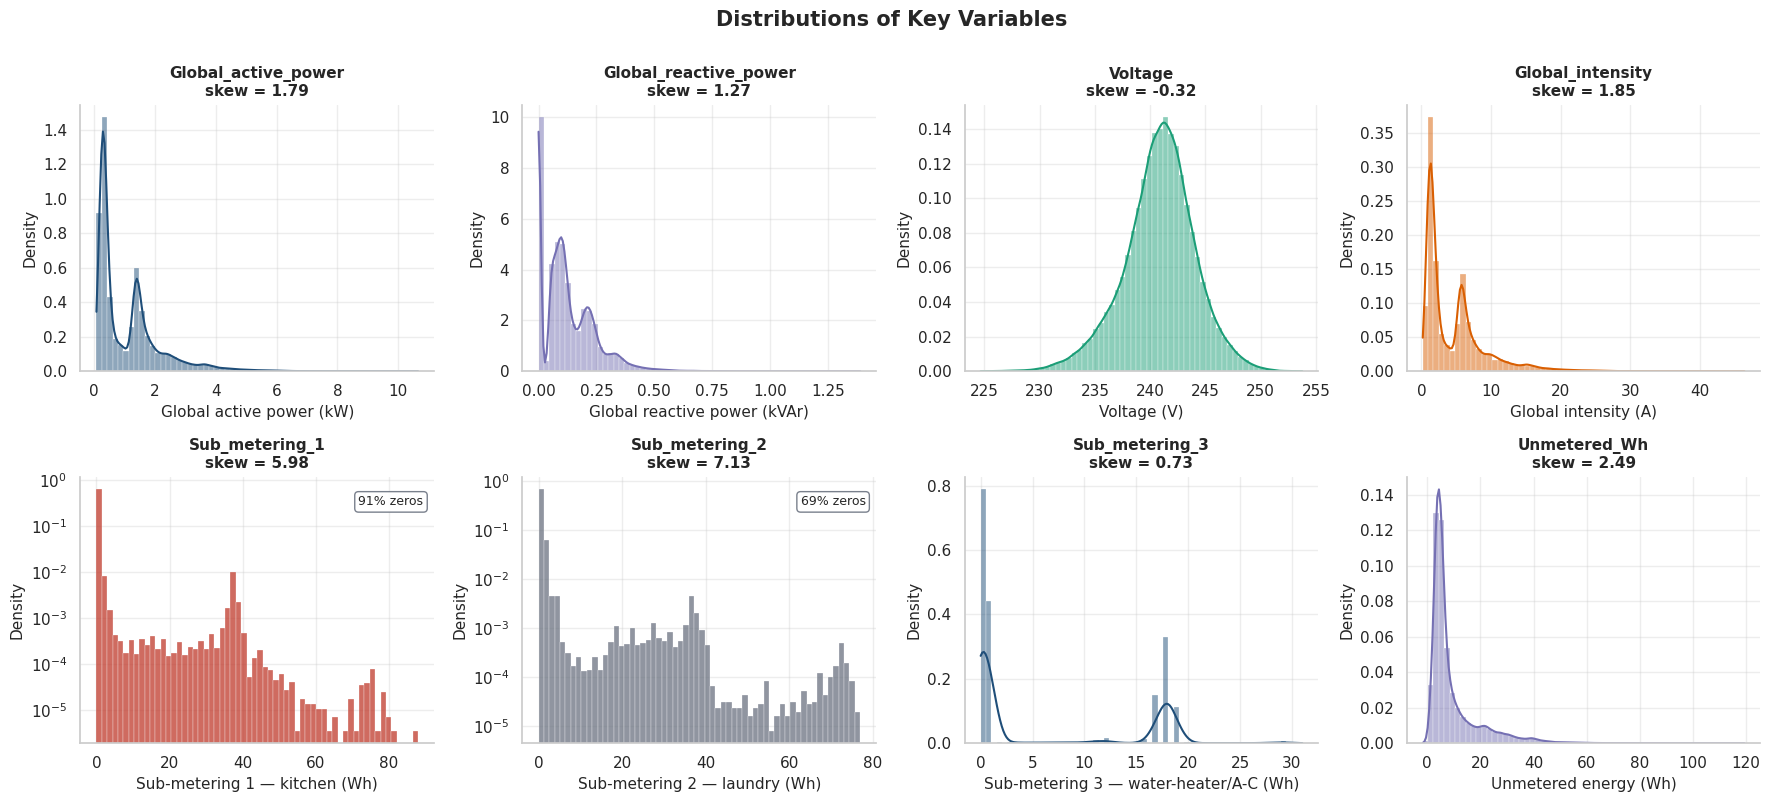

In [ ]:
# ----------------------------------------------------------------------------
# 7E. DISTRIBUTION PLOTS FOR KEY VARIABLES
# ----------------------------------------------------------------------------
samp = df_clean[NUMERIC].sample(200_000, random_state=RANDOM_SEED)
pretty = {"Global_active_power": "Global active power (kW)", "Global_reactive_power": "Global reactive power (kVAr)",
          "Voltage": "Voltage (V)", "Global_intensity": "Global intensity (A)",
          "Sub_metering_1": "Sub-metering 1 — kitchen (Wh)", "Sub_metering_2": "Sub-metering 2 — laundry (Wh)",
          "Sub_metering_3": "Sub-metering 3 — water-heater/A-C (Wh)", "Unmetered_Wh": "Unmetered energy (Wh)"}
palette = [C["primary"], C["purple"], C["green"], C["accent"], C["red"], C["grey"], C["primary"], C["purple"]]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col, colr in zip(axes.ravel(), NUMERIC, palette):
    zero_share = (df_clean[col] == 0).mean()
    zero_inflated = zero_share > 0.5
    sns.histplot(samp[col], bins=60, stat="density", kde=not zero_inflated, color=colr, edgecolor="white", linewidth=.2, ax=ax)
    if zero_inflated:
        ax.set_yscale("log")
        ax.text(.97, .93, f"{zero_share*100:.0f}% zeros", transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec=C["grey"], alpha=.9))
    ax.set_xlabel(pretty[col]); ax.set_ylabel("Density")
    ax.set_title(f"{col}\nskew = {df_clean[col].skew():.2f}", fontsize=11)
fig.suptitle("Distributions of Key Variables", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "07E_distributions")

In [ ]:
sk = df_clean[NUMERIC].skew(); zs = (df_clean[NUMERIC] == 0).mean() * 100
report_box("Distribution plots (Figure 7E)", f"""
The variables fall into three groups. (i) Global active power, global reactive power and global intensity are right-skewed (skewness {sk['Global_active_power']:.2f}, {sk['Global_reactive_power']:.2f} and {sk['Global_intensity']:.2f}), with the bulk of observations at low values and a long upper tail; active power and intensity are in addition clearly bimodal, with a secondary peak that reflects a recurring higher-load operating state. (ii) Voltage is the only approximately bell-shaped variable (skewness {sk['Voltage']:.2f}), concentrated around 240 V with a slight negative skew caused by load-induced voltage drops; it varies in a narrow band of about {R['v_min']:.0f}–{R['v_max']:.0f} V. (iii) The three sub-metering variables are zero-inflated and extremely skewed: Sub_metering_1 and Sub_metering_2 are exactly zero in {zs['Sub_metering_1']:.0f}% and {zs['Sub_metering_2']:.0f}% of the minutes respectively, whereas Sub_metering_3, which includes the water-heater, is bimodal (skewness {sk['Sub_metering_3']:.2f}) with {zs['Sub_metering_3']:.0f}% of minutes at zero and a second mode at roughly 17–18 Wh, consistent with an appliance that is either off or running at an almost constant rated power. These properties suggest that scale-sensitive models will benefit from standardisation or log transformation, and that the sub-metering variables are better treated as indicators of appliance activity than as Gaussian quantities.
""")

#### 📝 Report text — Distribution plots (Figure 7E)

> The variables fall into three groups. (i) Global active power, global reactive power and global intensity are right-skewed (skewness 1.79, 1.27 and 1.85), with the bulk of observations at low values and a long upper tail; active power and intensity are in addition clearly bimodal, with a secondary peak that reflects a recurring higher-load operating state. (ii) Voltage is the only approximately bell-shaped variable (skewness -0.32), concentrated around 240 V with a slight negative skew caused by load-induced voltage drops; it varies in a narrow band of about 223–254 V. (iii) The three sub-metering variables are zero-inflated and extremely skewed: Sub_metering_1 and Sub_metering_2 are exactly zero in 91% and 69% of the minutes respectively, whereas Sub_metering_3, which includes the water-heater, is bimodal (skewness 0.73) with 41% of minutes at zero and a second mode at roughly 17–18 Wh, consistent with an appliance that is either off or running at an almost constant rated power. These properties suggest that scale-sensitive models will benefit from standardisation or log transformation, and that the sub-metering variables are better treated as indicators of appliance activity than as Gaussian quantities.

### 7F. Monthly trend analysis

Monthly aggregation removes intraday noise and exposes the annual cycle and any long-term drift. Four views:
* **(F1)** monthly mean power with a 12-month centred moving average (the average over one full seasonal cycle removes seasonality and isolates the trend),
* **(F2)** year × month heatmap,
* **(F3)** seasonal sub-series: one line per year across calendar months (do years repeat the same pattern?),
* **(F4)** stacked monthly average power by consumption component.

*Dec 2006 and Nov 2010 are partial months.*

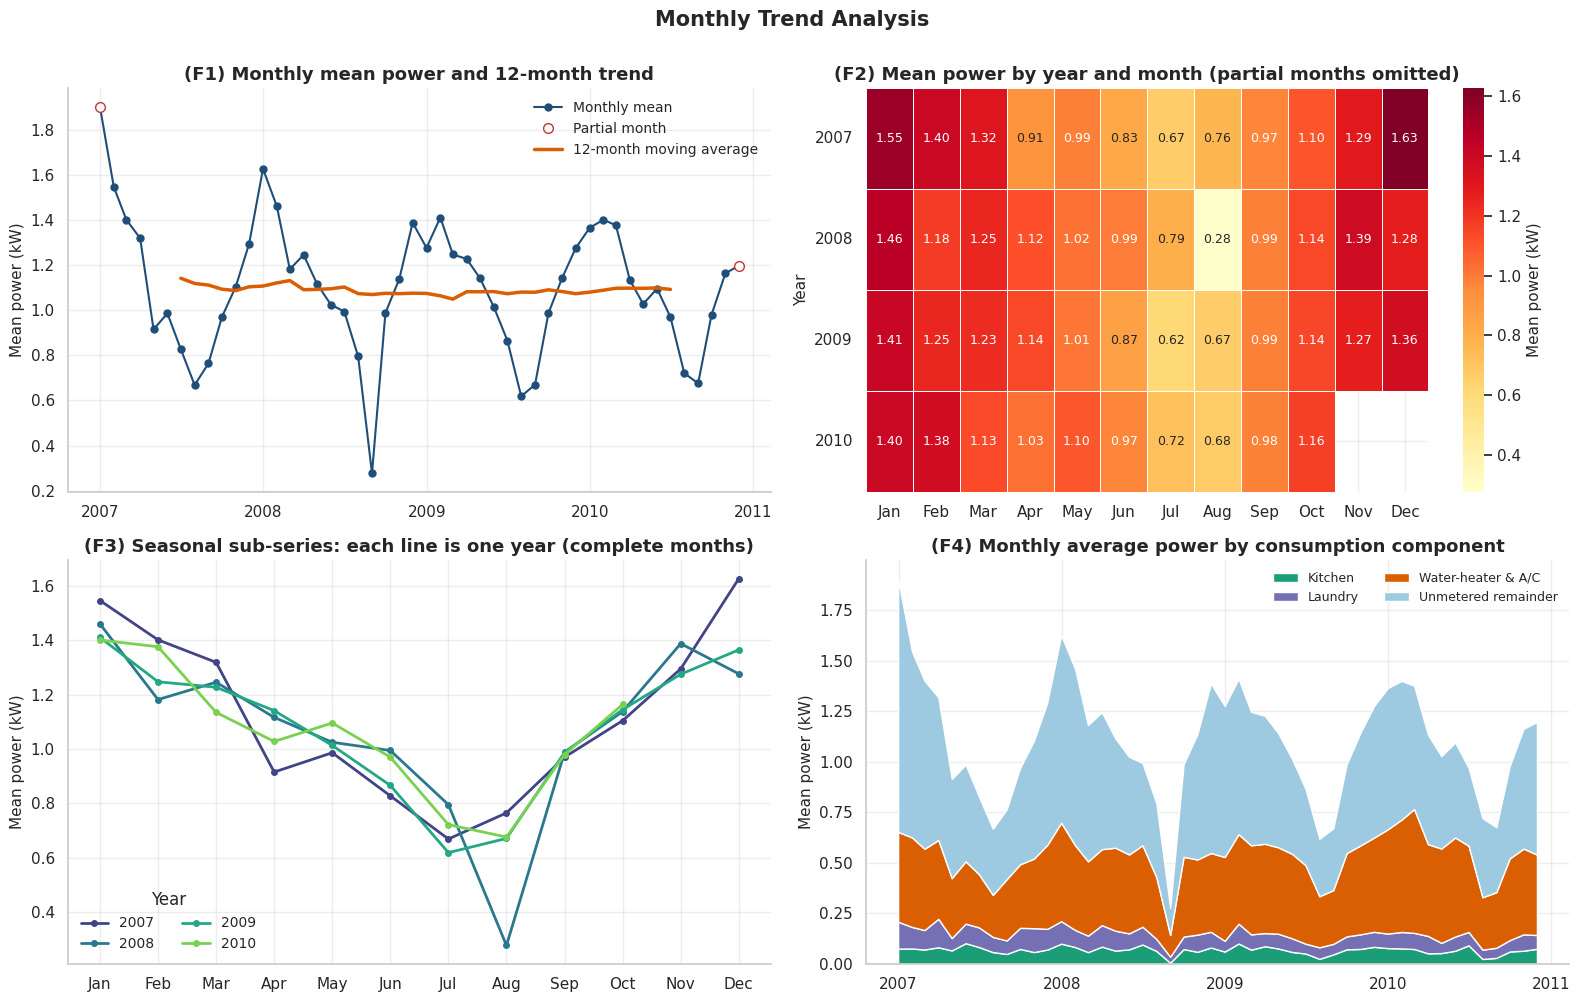

In [ ]:
# ----------------------------------------------------------------------------
# 7F. MONTHLY TREND ANALYSIS
# ----------------------------------------------------------------------------
m_gap = monthly[TARGET]
cov_m = df_clean[TARGET].resample("ME").count() / (df_clean[TARGET].resample("ME").count().index.days_in_month * 1440)
partial = cov_m < 0.97
trend12 = m_gap.rolling(12, center=True, min_periods=12).mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# (F1) monthly line + 12-month MA
ax = axes[0, 0]
ax.plot(m_gap.index, m_gap, marker="o", ms=5, color=C["primary"], lw=1.5, label="Monthly mean")
ax.plot(m_gap.index[partial], m_gap[partial], "o", ms=7, mfc="white", mec=C["red"], label="Partial month")
ax.plot(trend12.index, trend12, color=C["accent"], lw=2.5, label="12-month moving average")
ax.set_ylabel("Mean power (kW)"); ax.set_title("(F1) Monthly mean power and 12-month trend")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y")); ax.legend()

# (F2) year x month heatmap
ax = axes[0, 1]
m_full = m_gap[~partial]                                         # complete months only
hm = m_full.groupby([m_full.index.year, m_full.index.month]).mean().unstack().reindex(columns=range(1, 13)).dropna(how="all")
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=.5, linecolor="white",
            cbar_kws={"label": "Mean power (kW)"}, ax=ax, annot_kws={"size": 9})
ax.set_xticklabels(MONTHS, rotation=0); ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_ylabel("Year"); ax.set_xlabel("")
ax.set_title("(F2) Mean power by year and month (partial months omitted)")

# (F3) seasonal subseries
ax = axes[1, 0]
for yr_, col in zip(hm.index, sns.color_palette("viridis", len(hm))):
    ax.plot(range(1, 13), hm.loc[yr_], marker="o", ms=4, lw=2, color=col, label=str(yr_))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS)
ax.set_ylabel("Mean power (kW)"); ax.set_title("(F3) Seasonal sub-series: each line is one year (complete months)"); ax.legend(title="Year", ncol=2)

# (F4) stacked components (Wh per minute -> kW: x 60 / 1000)
ax = axes[1, 1]
comp = (monthly[SUB_COLS + ["Unmetered_Wh"]] * 60 / 1000).clip(lower=0)
ax.stackplot(comp.index, comp.T, colors=[C["green"], C["purple"], C["accent"], C["light"]],
             labels=["Kitchen", "Laundry", "Water-heater & A/C", "Unmetered remainder"])
ax.set_ylabel("Mean power (kW)"); ax.set_title("(F4) Monthly average power by consumption component")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper right", ncol=2, fontsize=9)

fig.suptitle("Monthly Trend Analysis", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "07F_monthly_trend")

clim = m_full.groupby(m_full.index.month).mean()                # climatology by calendar month (complete months only)
R.update(clim=clim, peak_month=MONTHS[clim.idxmax() - 1], low_month=MONTHS[clim.idxmin() - 1],
         peak_v=clim.max(), low_v=clim.min(),
         trend_start=trend12.dropna().iloc[0], trend_end=trend12.dropna().iloc[-1],
         trend_first_date=trend12.dropna().index[0], trend_last_date=trend12.dropna().index[-1],
         aug08=hm.loc[2008, 8], aug_other=hm[8].drop(2008).mean())

In [ ]:
report_box("Monthly trend analysis (Figure 7F)", f"""
Monthly aggregation reveals a pronounced and repeatable annual cycle: averaged over the complete months, consumption is highest in {R['peak_month']} ({R['peak_v']:.2f} kW) and lowest in {R['low_month']} ({R['low_v']:.2f} kW), so that the peak month uses about {R['peak_v']/R['low_v']:.1f} times as much power as the lowest month. The seasonal sub-series (F3) shows that the full years follow broadly the same shape, which confirms that the seasonality is stable and should be exploited by the forecasting models; the main exception is August 2008, whose mean of {R['aug08']:.2f} kW is far below that of the other Augusts ({R['aug_other']:.2f} kW on average) and most likely reflects a prolonged absence of the occupants. The 12-month moving average, which removes the seasonal component, is almost flat, moving from {R['trend_start']:.2f} kW ({R['trend_first_date']:%b %Y}) to {R['trend_end']:.2f} kW ({R['trend_last_date']:%b %Y}), i.e. a very slight downward drift in baseline consumption. The stacked component view (F4) shows that the seasonal swing is carried mainly by the unmetered remainder (which includes electric heating, lighting and electronics) and by the water-heater/air-conditioner circuit, whereas the kitchen and laundry circuits are comparatively stable throughout the year. The summer minimum, particularly in July and August, is consistent with holiday absences and the absence of heating needs. Because the first and last months of the record are incomplete, they are shown with hollow markers in F1 and excluded from the heatmap, sub-series and monthly averages.
""")

#### 📝 Report text — Monthly trend analysis (Figure 7F)

> Monthly aggregation reveals a pronounced and repeatable annual cycle: averaged over the complete months, consumption is highest in Jan (1.45 kW) and lowest in Aug (0.60 kW), so that the peak month uses about 2.4 times as much power as the lowest month. The seasonal sub-series (F3) shows that the full years follow broadly the same shape, which confirms that the seasonality is stable and should be exploited by the forecasting models; the main exception is August 2008, whose mean of 0.28 kW is far below that of the other Augusts (0.70 kW on average) and most likely reflects a prolonged absence of the occupants. The 12-month moving average, which removes the seasonal component, is almost flat, moving from 1.14 kW (Jun 2007) to 1.09 kW (Jun 2010), i.e. a very slight downward drift in baseline consumption. The stacked component view (F4) shows that the seasonal swing is carried mainly by the unmetered remainder (which includes electric heating, lighting and electronics) and by the water-heater/air-conditioner circuit, whereas the kitchen and laundry circuits are comparatively stable throughout the year. The summer minimum, particularly in July and August, is consistent with holiday absences and the absence of heating needs. Because the first and last months of the record are incomplete, they are shown with hollow markers in F1 and excluded from the heatmap, sub-series and monthly averages.

### 7G. Seasonal (cyclical) trend analysis

Seasonality in household load occurs at several nested time scales. We examine four:
* **(G1) Intraday** — mean hourly profile on weekdays vs weekends, with the interquartile band showing day-to-day variability,
* **(G2) Weekly** — mean power by day of week,
* **(G3) Annual** — mean power by meteorological season (Winter = Dec–Feb, Spring = Mar–May, Summer = Jun–Aug, Autumn = Sep–Nov),
* **(G4) Hour × weekday heatmap** — the interaction of the daily and weekly cycles,
* **(G5) Calendar-month boxplot** of daily mean power.

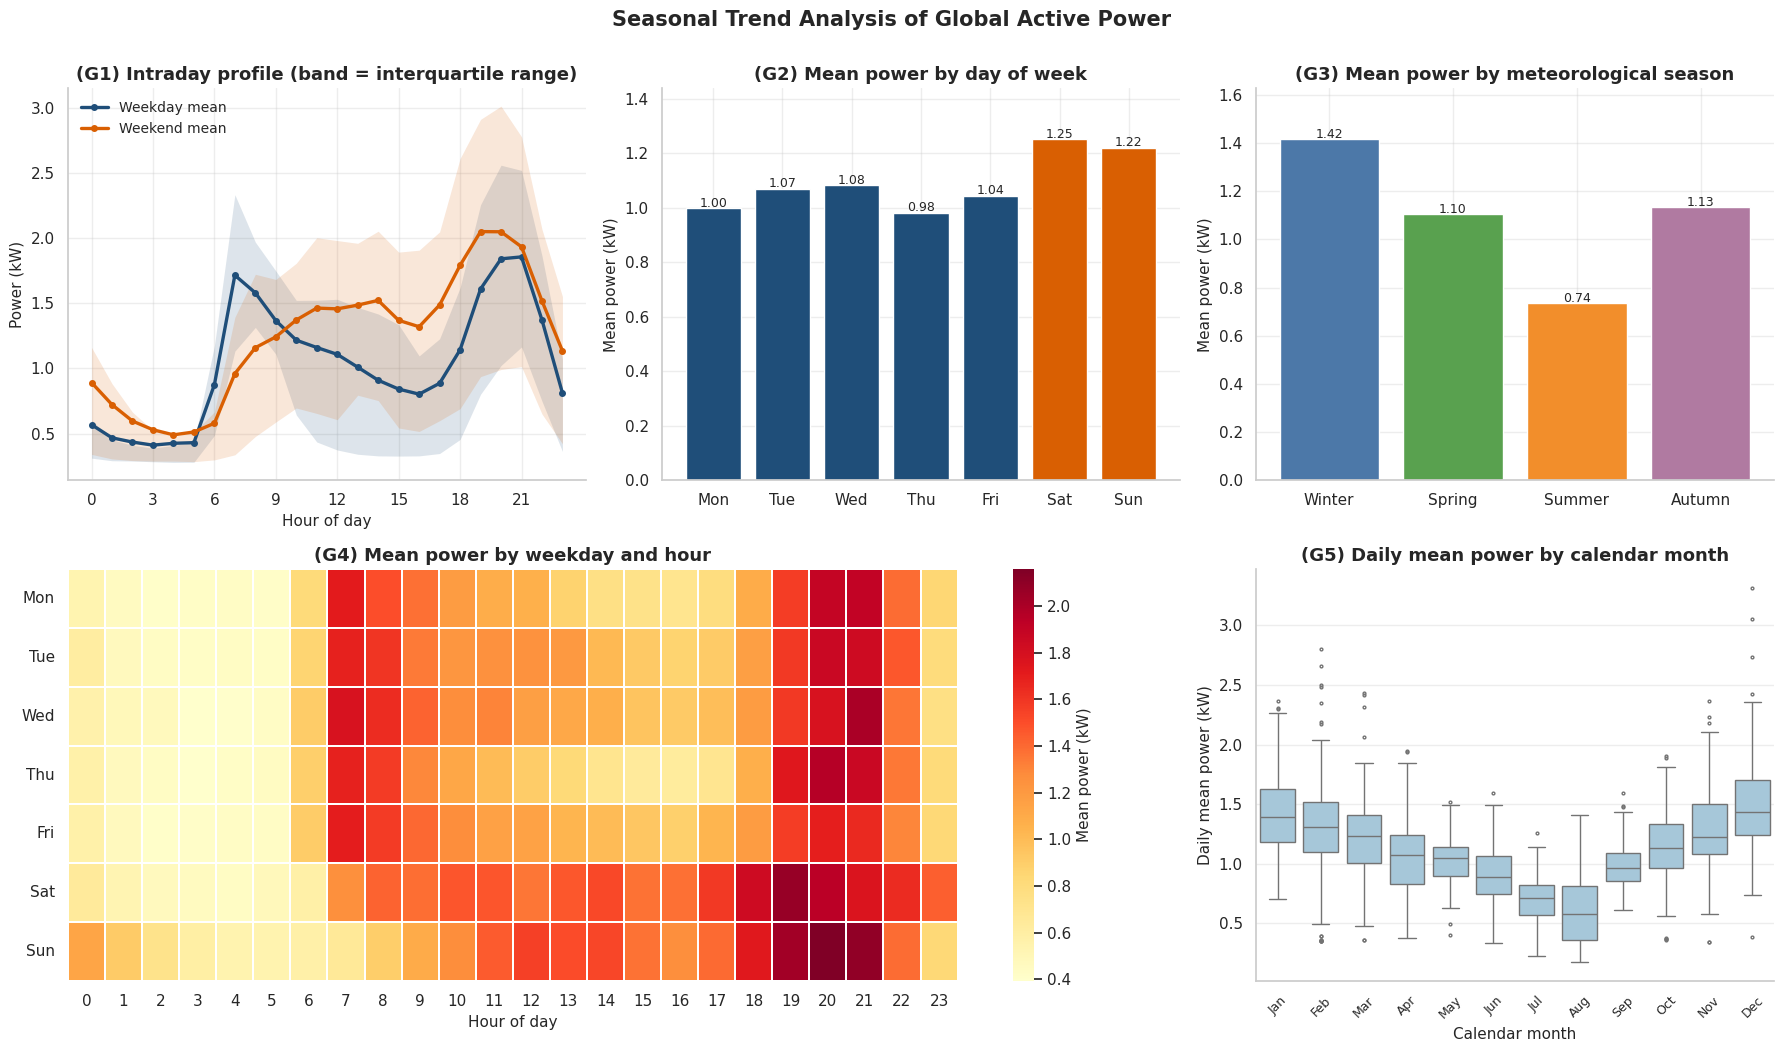

{'peak_hour': 20, 'trough_hour': 4, 'wd_mean': np.float64(1.035), 'we_mean': np.float64(1.235), 'wd_peak_hour': 21, 'we_peak_hour': 19, 'top_dow': 'Sat', 'low_dow': 'Thu'}


In [ ]:
# ----------------------------------------------------------------------------
# 7G. SEASONAL TREND ANALYSIS
# ----------------------------------------------------------------------------
H = hourly[[TARGET]].copy()
H["hour"], H["dow"], H["month"] = H.index.hour, H.index.dayofweek, H.index.month
H["daytype"] = np.where(H["dow"] >= 5, "Weekend", "Weekday")
H["season"]  = H["month"].map(SEASON_OF)

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.05])

# (G1) hourly profile weekday vs weekend with IQR band
ax = fig.add_subplot(gs[0, 0])
for dt_, col in [("Weekday", C["primary"]), ("Weekend", C["accent"])]:
    g = H[H["daytype"] == dt_].groupby("hour")[TARGET]
    med, lo, hi = g.mean(), g.quantile(.25), g.quantile(.75)
    ax.plot(med.index, med, color=col, lw=2.4, marker="o", ms=4, label=f"{dt_} mean")
    ax.fill_between(med.index, lo, hi, color=col, alpha=.15, lw=0)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Power (kW)")
ax.set_title("(G1) Intraday profile (band = interquartile range)"); ax.legend()

# (G2) day of week
ax = fig.add_subplot(gs[0, 1])
dow_m = H.groupby("dow")[TARGET].mean()
bars = ax.bar(DAYS, dow_m.values, color=[C["primary"]] * 5 + [C["accent"]] * 2)
for b, v in zip(bars, dow_m.values): ax.text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylim(0, dow_m.max() * 1.15); ax.set_ylabel("Mean power (kW)"); ax.set_title("(G2) Mean power by day of week")

# (G3) season
ax = fig.add_subplot(gs[0, 2])
sea_m = H.groupby("season")[TARGET].mean().reindex(SEASON_ORDER)
bars = ax.bar(SEASON_ORDER, sea_m.values, color=["#4c78a8", "#59a14f", "#f28e2b", "#b07aa1"])
for b, v in zip(bars, sea_m.values): ax.text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylim(0, sea_m.max() * 1.15); ax.set_ylabel("Mean power (kW)"); ax.set_title("(G3) Mean power by meteorological season")

# (G4) hour x weekday heatmap
ax = fig.add_subplot(gs[1, 0:2])
piv = H.pivot_table(index="dow", columns="hour", values=TARGET, aggfunc="mean")
sns.heatmap(piv, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Mean power (kW)"}, linewidths=.3, linecolor="white")
ax.set_yticklabels(DAYS, rotation=0); ax.set_xlabel("Hour of day"); ax.set_ylabel("")
ax.set_title("(G4) Mean power by weekday and hour")

# (G5) calendar month boxplot of daily means
ax = fig.add_subplot(gs[1, 2])
dd = daily[[TARGET]].assign(month=daily.index.month)
sns.boxplot(data=dd, x="month", y=TARGET, color=C["light"], ax=ax, fliersize=2, linewidth=1)
ax.set_xticklabels(MONTHS, rotation=45, fontsize=9); ax.set_xlabel("Calendar month"); ax.set_ylabel("Daily mean power (kW)")
ax.set_title("(G5) Daily mean power by calendar month")

fig.suptitle("Seasonal Trend Analysis of Global Active Power", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "07G_seasonality")

# ---- facts for the interpretation ----------------------------------------
prof_all = H.groupby("hour")[TARGET].mean()
wd = H[H["daytype"] == "Weekday"].groupby("hour")[TARGET].mean(); we = H[H["daytype"] == "Weekend"].groupby("hour")[TARGET].mean()
R.update(peak_hour=int(prof_all.idxmax()), peak_hour_v=prof_all.max(), trough_hour=int(prof_all.idxmin()), trough_hour_v=prof_all.min(),
         wd_mean=H.loc[H["daytype"] == "Weekday", TARGET].mean(), we_mean=H.loc[H["daytype"] == "Weekend", TARGET].mean(),
         wd_peak_hour=int(wd.idxmax()), we_peak_hour=int(we.idxmax()),
         wd_morn_h=int(wd.loc[5:12].idxmax()), wd_morn_v=wd.loc[5:12].max(), we_morn_v=we.loc[5:9].max(),
         we_mid=we.loc[10:16].mean(), wd_mid=wd.loc[10:16].mean(), wd_eve_v=wd.loc[17:23].max(), we_eve_v=we.loc[17:23].max(),
         dow_mean=dow_m.to_dict(), season_mean=sea_m.to_dict(), top_dow=DAYS[int(dow_m.idxmax())], low_dow=DAYS[int(dow_m.idxmin())])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in R.items()
       if k in ["peak_hour","trough_hour","wd_mean","we_mean","wd_peak_hour","we_peak_hour","top_dow","low_dow"]})

In [ ]:
sm = R["season_mean"]
order = sorted(sm, key=sm.get, reverse=True)
season_txt = ", ".join(f"{k.lower()} ({sm[k]:.2f} kW)" for k in order[1:])
report_box("Seasonal analysis (Figure 7G)", f"""
The data exhibit three superimposed seasonal cycles. **Intraday:** consumption is lowest at around {R['trough_hour']:02d}:00 ({R['trough_hour_v']:.2f} kW) and highest at around {R['peak_hour']:02d}:00 ({R['peak_hour_v']:.2f} kW), with a pronounced secondary peak in the morning on weekdays. On weekdays the load rises abruptly at around 06:00 and peaks at {R['wd_morn_h']:02d}:00 ({R['wd_morn_v']:.2f} kW), decays during the working day (mean {R['wd_mid']:.2f} kW between 10:00 and 16:00) and then rises to an evening maximum of {R['wd_eve_v']:.2f} kW. At weekends the sharp morning peak disappears ({R['we_morn_v']:.2f} kW at most before 10:00); consumption instead increases gradually into a broad daytime plateau (mean {R['we_mid']:.2f} kW between 10:00 and 16:00) followed by a higher evening maximum of {R['we_eve_v']:.2f} kW, which is consistent with people being at home during the day. **Weekly:** the highest daily average occurs on {R['top_dow']} ({R['dow_mean'][5]:.2f} kW) and the lowest on {R['low_dow']} ({R['dow_mean'][3]:.2f} kW); the weekend mean ({R['we_mean']:.2f} kW) exceeds the weekday mean ({R['wd_mean']:.2f} kW). **Annual:** {order[0].lower()} is the most energy-intensive season ({sm[order[0]]:.2f} kW), followed by {season_txt}, reflecting heating and lighting needs, and the calendar-month boxplot shows the deep July–August minimum. The weekday × hour heatmap shows that the daily and weekly cycles interact (the morning peak exists only on working days), so forecasting features should include both hour of day and day of week, ideally in a form that allows their interaction to be captured, rather than treating them separately. These strong, stable cycles are the main source of predictability in this series and justify the use of seasonal models.
""")

#### 📝 Report text — Seasonal analysis (Figure 7G)

> The data exhibit three superimposed seasonal cycles. **Intraday:** consumption is lowest at around 04:00 (0.44 kW) and highest at around 20:00 (1.90 kW), with a pronounced secondary peak in the morning on weekdays. On weekdays the load rises abruptly at around 06:00 and peaks at 07:00 (1.71 kW), decays during the working day (mean 1.01 kW between 10:00 and 16:00) and then rises to an evening maximum of 1.86 kW. At weekends the sharp morning peak disappears (1.24 kW at most before 10:00); consumption instead increases gradually into a broad daytime plateau (mean 1.43 kW between 10:00 and 16:00) followed by a higher evening maximum of 2.05 kW, which is consistent with people being at home during the day. **Weekly:** the highest daily average occurs on Sat (1.25 kW) and the lowest on Thu (0.98 kW); the weekend mean (1.23 kW) exceeds the weekday mean (1.04 kW). **Annual:** winter is the most energy-intensive season (1.42 kW), followed by autumn (1.13 kW), spring (1.10 kW), summer (0.74 kW), reflecting heating and lighting needs, and the calendar-month boxplot shows the deep July–August minimum. The weekday × hour heatmap shows that the daily and weekly cycles interact (the morning peak exists only on working days), so forecasting features should include both hour of day and day of week, ideally in a form that allows their interaction to be captured, rather than treating them separately. These strong, stable cycles are the main source of predictability in this series and justify the use of seasonal models.

---
# 8. Outlier Analysis

In power data, a high value is not automatically an *error*: a household oven, kettle and water-heater running simultaneously produce a genuine spike. The analysis therefore has two goals: **(1) detect** unusual values with several complementary methods, and **(2) judge whether they are errors or real events** before deciding to remove or keep them.

### 8.1 Detection methods
| Method | Idea | Weakness |
|---|---|---|
| **Tukey IQR rule** | flag values above Q3 + 1.5·IQR (and "extreme" above Q3 + 3·IQR) | assumes roughly symmetric data; flags many points in skewed data |
| **Z-score** | flag \|z\| > 3 | mean/std are themselves distorted by outliers |
| **Modified z-score (MAD)** | robust version using the median and median absolute deviation (flag > 3.5) | very sensitive when the distribution is skewed |
| **Contextual residual** | flag points that deviate by > 3σ from the *typical value for that weekday-hour-minute* | accounts for seasonality — a value can be normal at 8 pm yet unusual at 4 am |

The first three are *global* methods; the fourth is the most appropriate in a time-series sense, since it asks "is this unusual **for this time of the week**?".

In [ ]:
# ----------------------------------------------------------------------------
# 8.1  OUTLIER DETECTION — four methods
# ----------------------------------------------------------------------------
q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
hi_f   = q3 + 1.5 * iqr                         # Tukey upper fence
ext_f  = q3 + 3.0 * iqr                         # Tukey "extreme" fence
lo_f   = q1 - 1.5 * iqr                         # lower fence (negative -> unreachable)
mu, sd = y.mean(), y.std()
mad    = (y - y.median()).abs().median()
modz   = 0.6745 * (y - y.median()) / mad
resid  = y - seasonal_all[TARGET]               # deviation from the typical weekday-hour-minute value
res_sd = resid.std()

flags = {
    "Tukey IQR (> Q3 + 1.5·IQR)":          y > hi_f,
    "Tukey extreme (> Q3 + 3·IQR)":        y > ext_f,
    "Z-score (|z| > 3)":                   ((y - mu) / sd).abs() > 3,
    "Modified z-score (MAD > 3.5)":        modz.abs() > 3.5,
    "Contextual (|residual| > 3σ)":        resid.abs() > 3 * res_sd,
}
thresholds = {"Tukey IQR (> Q3 + 1.5·IQR)": f"> {hi_f:.2f} kW", "Tukey extreme (> Q3 + 3·IQR)": f"> {ext_f:.2f} kW",
              "Z-score (|z| > 3)": f"> {mu + 3*sd:.2f} kW", "Modified z-score (MAD > 3.5)": f"> {y.median() + 3.5*mad/0.6745:.2f} kW",
              "Contextual (|residual| > 3σ)": f"|y − profile| > {3*res_sd:.2f} kW"}
out_tbl = pd.DataFrame({"threshold": thresholds,
                        "outlier_minutes": {k: int(v.sum()) for k, v in flags.items()},
                        "share_%": {k: v.mean() * 100 for k, v in flags.items()}})
display(out_tbl.style.format({"outlier_minutes": "{:,.0f}", "share_%": "{:.2f}"}).set_caption(f"Outliers in {TARGET} by method"))
print(f"Lower Tukey fence = {lo_f:.2f} kW -> {int((y < lo_f).sum())} low outliers (power cannot be negative).")

# Outliers in the other measurement variables (Tukey IQR rule)
others = {}
for c in FEATURES:
    a, b = df_clean[c].quantile([.25, .75]); i_ = b - a
    others[c] = ((df_clean[c] > b + 1.5 * i_) | (df_clean[c] < a - 1.5 * i_)).mean() * 100
display(pd.Series(others, name="% flagged (Tukey, both tails)").to_frame().style.format("{:.2f}"))

R.update(out_tbl=out_tbl, ext_f=ext_f, hi_f=hi_f, n_iqr=int(flags["Tukey IQR (> Q3 + 1.5·IQR)"].sum()),
         n_ext=int(flags["Tukey extreme (> Q3 + 3·IQR)"].sum()), n_ctx=int(flags["Contextual (|residual| > 3σ)"].sum()),
         p_iqr=flags["Tukey IQR (> Q3 + 1.5·IQR)"].mean() * 100, p_ext=flags["Tukey extreme (> Q3 + 3·IQR)"].mean() * 100,
         p_z=flags["Z-score (|z| > 3)"].mean() * 100, p_mad=flags["Modified z-score (MAD > 3.5)"].mean() * 100,
         p_ctx=flags["Contextual (|residual| > 3σ)"].mean() * 100)

,threshold,outlier_minutes,share_%
Tukey IQR (> Q3 + 1.5·IQR),> 3.35 kW,"95,238",4.59
Tukey extreme (> Q3 + 3·IQR),> 5.18 kW,"14,464",0.70
Z-score (|z| > 3),> 4.25 kW,"36,671",1.77
Modified z-score (MAD > 3.5),> 2.73 kW,"159,241",7.67
Contextual (|residual| > 3σ),|y − profile| > 2.79 kW,"36,158",1.74


Lower Tukey fence = -1.52 kW -> 0 low outliers (power cannot be negative).


,"% flagged (Tukey, both tails)"
Global_active_power,4.59
Global_reactive_power,2.04
Voltage,2.54
Global_intensity,4.87
Sub_metering_1,9.22
Sub_metering_2,3.99
Sub_metering_3,0.00


### 8.2 Are the outliers errors or genuine events?

We test three hypotheses that would indicate *errors*:
1. **Physical coherence** — for a genuine load, the independently measured current and voltage must be consistent with the power. We compute the implied **power factor** `PF = P·1000 / (V·I)`; it should be ≤ 1 (allowing the 0.2 A current resolution) and typical of household loads.
2. **Isolated glitches** — a sensor spike would be a lone value; real loads persist for several minutes. We measure the typical *run length* of consecutive outlier minutes.
3. **Timing** — random errors would be spread uniformly through the day; real appliance use clusters at certain times.

In [ ]:
# ----------------------------------------------------------------------------
# 8.2  ERROR OR GENUINE EVENT?  (physical coherence, persistence, timing)
# ----------------------------------------------------------------------------
f_iqr, f_ext = flags["Tukey IQR (> Q3 + 1.5·IQR)"], flags["Tukey extreme (> Q3 + 3·IQR)"]
obs_ext = df_clean[f_ext & (df_clean["Imputed"] == 0)]

# (1) physical coherence of the most extreme minutes
pf = obs_ext[TARGET] * 1000 / (obs_ext["Voltage"] * obs_ext["Global_intensity"])
print(f"Extreme outliers (observed, not imputed): {len(obs_ext):,}")
print(f"  implied power factor: median = {pf.median():.2f}, 5th pct = {pf.quantile(.05):.2f}, 95th pct = {pf.quantile(.95):.2f}, max = {pf.max():.2f}")
print(f"  largest values: {y.nlargest(3).round(2).tolist()} kW  at  {[str(t) for t in y.nlargest(3).index]}")

# (2) persistence: length of consecutive runs of IQR-outlier minutes
rid = f_iqr.ne(f_iqr.shift()).cumsum()
runs = f_iqr.groupby(rid).sum(); runs = runs[runs > 0]
print(f"\nConsecutive outlier runs: {len(runs):,}  | median length = {runs.median():.0f} min, mean = {runs.mean():.1f} min, "
      f"runs of a single minute = {(runs == 1).mean()*100:.1f} %")

# (3) timing
by_hour = f_iqr.groupby(y.index.hour).mean() * 100
peak_hours = [6, 7, 8, 9, 18, 19, 20, 21, 22]
share_peak = f_iqr[y.index.hour.isin(peak_hours)].sum() / f_iqr.sum() * 100
print(f"\nShare of outlier minutes falling in the morning (06-09h) and evening (18-22h) peaks: {share_peak:.1f} % "
      f"(these hours are {len(peak_hours)/24*100:.0f} % of the day)")
print(f"Hours with the highest outlier rate: {by_hour.nlargest(3).round(1).to_dict()}")

by_year_rate = (f_iqr.groupby(y.index.year).mean() * 100).to_dict()
R.update(by_year_rate=by_year_rate, pf_med=pf.median(), pf_max=pf.max(), run_med=runs.median(), run_mean=runs.mean(), run_single=(runs == 1).mean() * 100,
         share_peak=share_peak, top_hours=list(by_hour.nlargest(3).index), n_runs=len(runs))

Extreme outliers (observed, not imputed): 14,461
  implied power factor: median = 1.00, 5th pct = 0.98, 95th pct = 1.01, max = 1.01
  largest values: [11.12, 10.67, 10.65] kW  at  ['2009-02-22 17:09:00', '2007-03-04 19:34:00', '2007-03-04 19:33:00']

Consecutive outlier runs: 15,155  | median length = 3 min, mean = 6.3 min, runs of a single minute = 28.8 %

Share of outlier minutes falling in the morning (06-09h) and evening (18-22h) peaks: 62.1 % (these hours are 38 % of the day)
Hours with the highest outlier rate: {20: 13.4, 21: 12.0, 19: 11.9}


### 8.3 Visualising the outliers
* **(a)** the histogram with the fences — outliers are simply the upper tail of a skewed distribution,
* **(b)** *when* the outliers occur (each dot = one flagged minute),
* **(c)** outlier rate by hour of day — real behaviour concentrates in peak hours,
* **(d)** outlier rate by year.

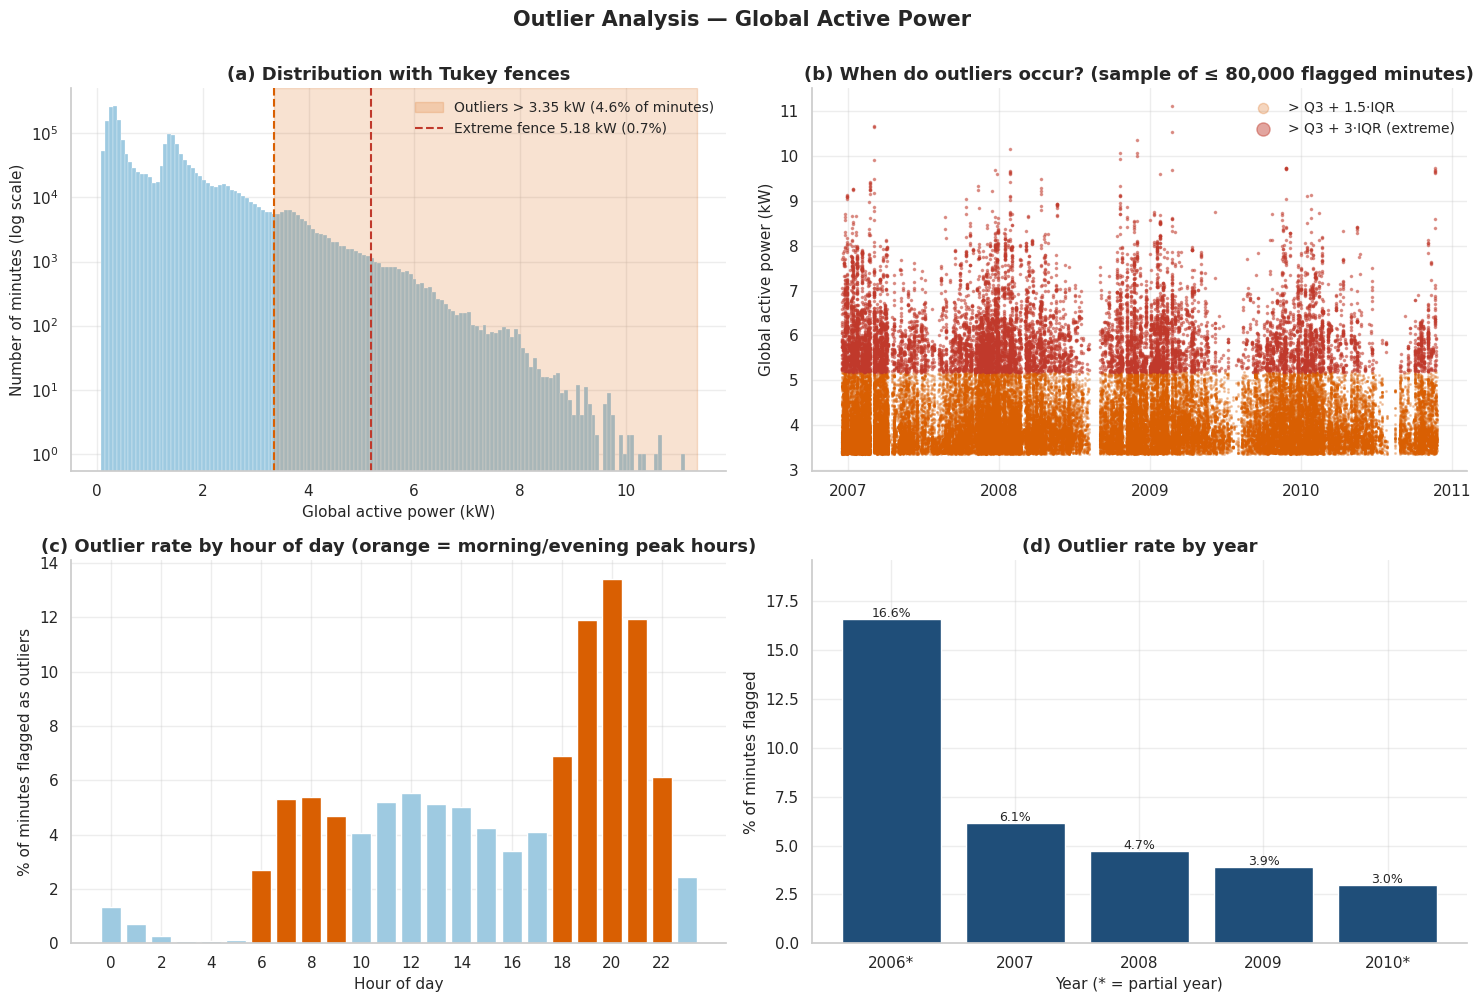

In [ ]:
# ----------------------------------------------------------------------------
# 8.3  OUTLIER VISUALISATION
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) histogram + fences
ax = axes[0, 0]
ax.hist(y, bins=150, color=C["light"], edgecolor="white", linewidth=.2)
ax.axvspan(hi_f, y.max() * 1.02, color=C["accent"], alpha=.18, label=f"Outliers > {hi_f:.2f} kW ({R['p_iqr']:.1f}% of minutes)")
ax.axvline(hi_f, color=C["accent"], ls="--", lw=1.5); ax.axvline(ext_f, color=C["red"], ls="--", lw=1.5, label=f"Extreme fence {ext_f:.2f} kW ({R['p_ext']:.1f}%)")
ax.set_yscale("log"); ax.set_xlabel("Global active power (kW)"); ax.set_ylabel("Number of minutes (log scale)")
ax.set_title("(a) Distribution with Tukey fences"); ax.legend(loc="upper right")

# (b) timeline of flagged minutes
ax = axes[0, 1]
fl = y[f_iqr]; fl = fl.sample(min(len(fl), 80_000), random_state=RANDOM_SEED).sort_index()
ext_mask = fl > ext_f
ax.scatter(fl.index[~ext_mask], fl[~ext_mask], s=1.5, alpha=.25, color=C["accent"], label="> Q3 + 1.5·IQR", rasterized=True)
ax.scatter(fl.index[ext_mask],  fl[ext_mask],  s=2.5, alpha=.45, color=C["red"],   label="> Q3 + 3·IQR (extreme)", rasterized=True)
ax.set_ylabel("Global active power (kW)"); ax.set_title("(b) When do outliers occur? (sample of ≤ 80,000 flagged minutes)")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(markerscale=6, loc="upper right")

# (c) by hour of day
ax = axes[1, 0]
ax.bar(by_hour.index, by_hour.values, color=[C["accent"] if h in peak_hours else C["light"] for h in by_hour.index])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day"); ax.set_ylabel("% of minutes flagged as outliers")
ax.set_title("(c) Outlier rate by hour of day (orange = morning/evening peak hours)")

# (d) by year
ax = axes[1, 1]
by_year = f_iqr.groupby(y.index.year).mean() * 100
bars = ax.bar([f"{yy}{'*' if yy in (2006, 2010) else ''}" for yy in by_year.index], by_year.values, color=C["primary"])
for b_, v in zip(bars, by_year.values): ax.text(b_.get_x() + b_.get_width() / 2, v + .1, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("% of minutes flagged"); ax.set_xlabel("Year (* = partial year)")
ax.set_title("(d) Outlier rate by year"); ax.set_ylim(0, by_year.max() * 1.18)

fig.suptitle("Outlier Analysis — Global Active Power", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "08_outliers")

### 8.4 Decision: remove or retain?

**Decision: RETAIN all outliers in the stored datasets.** Reasoning (details in the report text below):
1. They pass the physical-coherence test (they are real electrical loads, not sensor faults).
2. They are persistent (multi-minute) and concentrated at typical peak hours — they are behaviour, not noise.
3. Peaks are exactly what a forecasting model for *demand* must predict; removing them would produce forecasts that systematically under-estimate peak load, and would break the regular 1-minute time grid.
4. Removing 4–5 % of the minutes would also bias the mean, variance and autocorrelation structure.

**How to handle them downstream instead:** use robust metrics (MAE/MAPE alongside RMSE), consider a variance-stabilising transform (log1p or √), and — if a specific model is sensitive — apply capping (winsorisation) *inside the modelling pipeline with thresholds fitted on the training set only*.

In [ ]:
report_box("Outlier analysis (Figure 8)", f"""
Outliers in global active power were assessed with four methods. Tukey's IQR rule (upper fence {R['hi_f']:.2f} kW) flags {R['n_iqr']:,} minutes ({R['p_iqr']:.1f}%), of which {R['n_ext']:,} ({R['p_ext']:.1f}%) are extreme (above {R['ext_f']:.2f} kW). The classical z-score flags {R['p_z']:.1f}% of the data, the robust modified z-score {R['p_mad']:.1f}% and a contextual residual rule, which compares each observation with the typical value for that weekday, hour and minute, flags {R['p_ctx']:.1f}%. The very different counts show that the amount of flagged data depends heavily on the method, which is typical for a skewed distribution; all methods identify only the high tail, since power cannot be negative.

Several lines of evidence indicate that these observations are genuine events rather than measurement errors. First, the extreme values are physically coherent: the power factor implied by the independently measured voltage and current has a median of {R['pf_med']:.2f} and never exceeds {R['pf_max']:.2f} (within the 0.2 A resolution of the current measurement), i.e. the three quantities agree with one another. Second, the outliers are persistent rather than isolated: they occur in {R['n_runs']:,} consecutive runs with a median length of {R['run_med']:.0f} minutes, and {100 - R['run_single']:.0f}% of the runs last two minutes or longer, whereas sensor glitches would be expected to appear mainly as isolated spikes. Third, they are strongly concentrated in the morning and evening peak hours ({R['share_peak']:.0f}% of all outlier minutes fall into hours that make up 38% of the day), consistent with cooking, heating and hot-water use. The share of flagged minutes also declines steadily over the complete years ({R['by_year_rate'][2007]:.1f}% in 2007, {R['by_year_rate'][2008]:.1f}% in 2008 and {R['by_year_rate'][2009]:.1f}% in 2009), in line with the decreasing peak intensity noted in the boxplot analysis. The maximum recorded value of {R['gap_max']:.2f} kW is plausible for a household with electric heating and water-heating.

The outliers were therefore **retained**. Removing them would delete exactly the demand peaks that a forecasting model must predict, would bias the mean and variance of the series downwards, and would break the regular one-minute time grid. Instead, outlier sensitivity should be handled in the modelling stage, by reporting robust error metrics (MAE) alongside RMSE, by considering a log or square-root transformation, and, if required, by winsorising with thresholds estimated on the training set only.
""")

#### 📝 Report text — Outlier analysis (Figure 8)

> Outliers in global active power were assessed with four methods. Tukey's IQR rule (upper fence 3.35 kW) flags 95,238 minutes (4.6%), of which 14,464 (0.7%) are extreme (above 5.18 kW). The classical z-score flags 1.8% of the data, the robust modified z-score 7.7% and a contextual residual rule, which compares each observation with the typical value for that weekday, hour and minute, flags 1.7%. The very different counts show that the amount of flagged data depends heavily on the method, which is typical for a skewed distribution; all methods identify only the high tail, since power cannot be negative.
>
> Several lines of evidence indicate that these observations are genuine events rather than measurement errors. First, the extreme values are physically coherent: the power factor implied by the independently measured voltage and current has a median of 1.00 and never exceeds 1.01 (within the 0.2 A resolution of the current measurement), i.e. the three quantities agree with one another. Second, the outliers are persistent rather than isolated: they occur in 15,155 consecutive runs with a median length of 3 minutes, and 71% of the runs last two minutes or longer, whereas sensor glitches would be expected to appear mainly as isolated spikes. Third, they are strongly concentrated in the morning and evening peak hours (62% of all outlier minutes fall into hours that make up 38% of the day), consistent with cooking, heating and hot-water use. The share of flagged minutes also declines steadily over the complete years (6.1% in 2007, 4.7% in 2008 and 3.9% in 2009), in line with the decreasing peak intensity noted in the boxplot analysis. The maximum recorded value of 11.12 kW is plausible for a household with electric heating and water-heating.
>
> The outliers were therefore **retained**. Removing them would delete exactly the demand peaks that a forecasting model must predict, would bias the mean and variance of the series downwards, and would break the regular one-minute time grid. Instead, outlier sensitivity should be handled in the modelling stage, by reporting robust error metrics (MAE) alongside RMSE, by considering a log or square-root transformation, and, if required, by winsorising with thresholds estimated on the training set only.

---
# 9. Time-Series Analysis (supporting analysis for the forecasting stage)

Beyond descriptive plots, forecasting requires answers to three structural questions:
1. **Decomposition** — how much of the variation is trend, seasonality and noise? (STL = Seasonal-Trend decomposition using LOESS, robust to outliers.)
2. **Autocorrelation** — how long does the past stay informative? (ACF/PACF identify useful lags and seasonal periods.)
3. **Stationarity** — are the mean and variance stable over time? (ADF and KPSS tests with opposite null hypotheses, so they complement each other.)

We work with the **daily mean series** for decomposition/stationarity (noise-free enough for annual seasonality), and with the **hourly series** for the intraday autocorrelation structure. The first and last partial days are dropped.

Strength of trend       : 0.00
Strength of annual seasonality : 0.56
Day-of-week explains 5.8 % of the variance left after removing trend and annual cycle


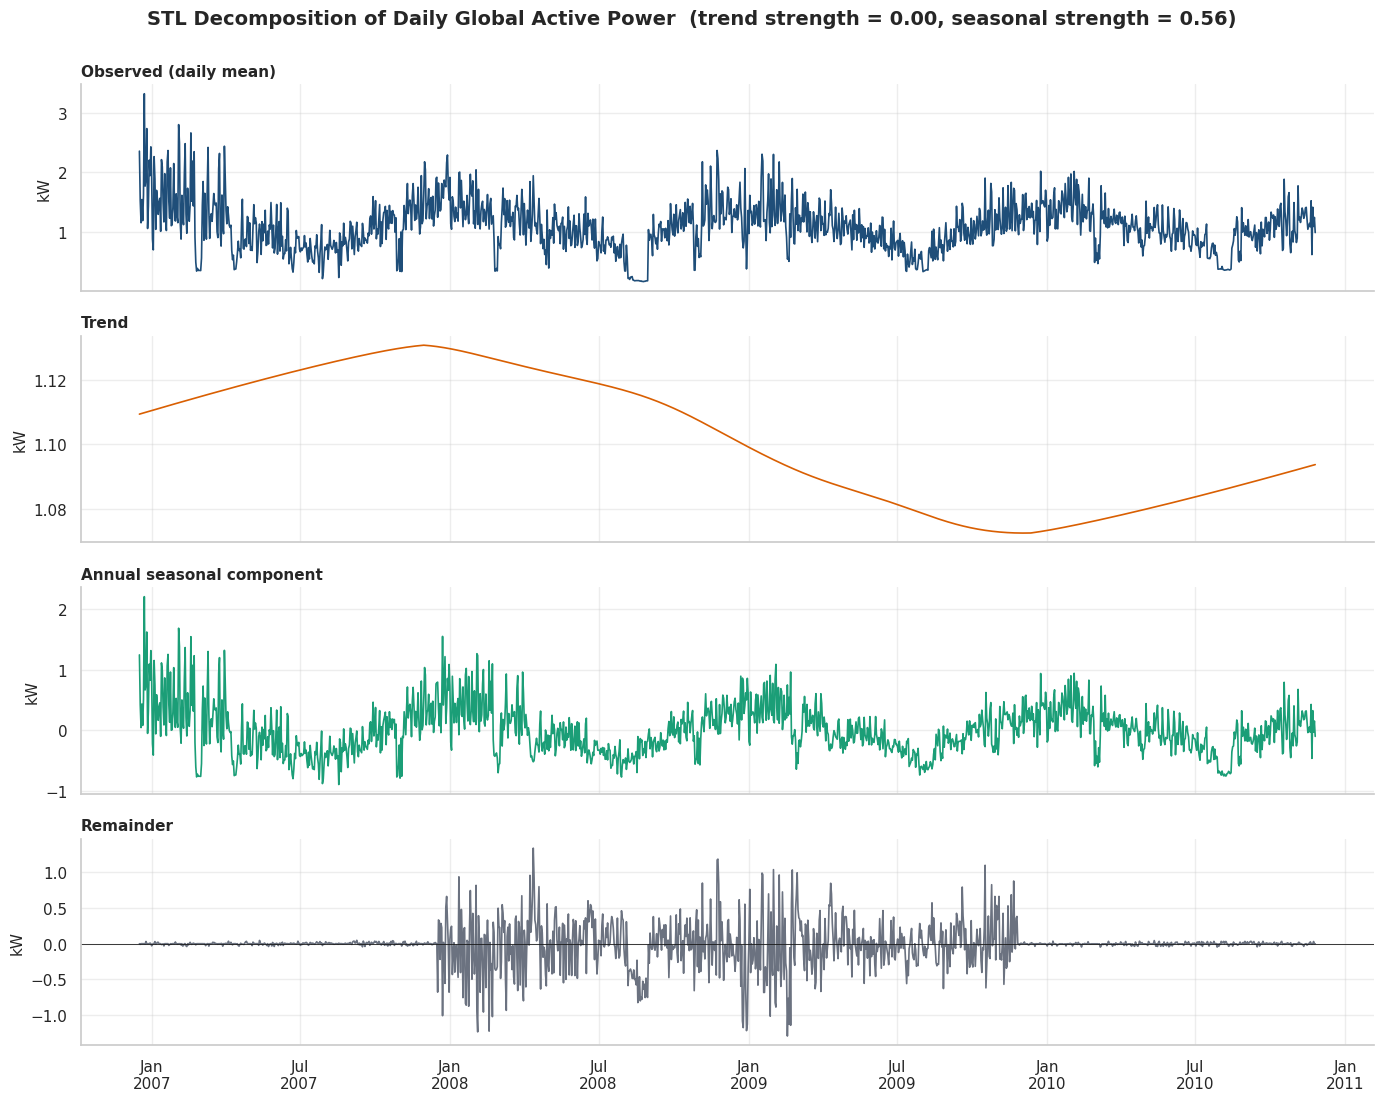

In [ ]:
# ----------------------------------------------------------------------------
# 9.1  STL DECOMPOSITION OF THE DAILY SERIES (annual seasonality)
# ----------------------------------------------------------------------------
d_full = daily[TARGET].iloc[1:-1].asfreq("D")                       # drop partial first/last day
stl = STL(d_full, period=365, robust=True).fit()
trend, seas, rem = stl.trend, stl.seasonal, stl.resid

# Strength of trend and seasonality (Hyndman & Athanasopoulos): 0 = none, 1 = perfect
F_trend = max(0, 1 - rem.var() / (trend + rem).var())
F_seas  = max(0, 1 - rem.var() / (seas + rem).var())
# Share of the remaining (non-annual) variance explained by the day of the week
dow_eff = rem.groupby(rem.index.dayofweek).transform("mean")
weekly_share = dow_eff.var() / rem.var() * 100
print(f"Strength of trend       : {F_trend:.2f}")
print(f"Strength of annual seasonality : {F_seas:.2f}")
print(f"Day-of-week explains {weekly_share:.1f} % of the variance left after removing trend and annual cycle")

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, ser, name, col in zip(axes, [d_full, trend, seas, rem],
                              ["Observed (daily mean)", "Trend", "Annual seasonal component", "Remainder"],
                              [C["primary"], C["accent"], C["green"], C["grey"]]):
    ax.plot(ser.index, ser, color=col, lw=1.2); ax.set_ylabel("kW"); ax.set_title(name, loc="left", fontsize=11)
axes[3].axhline(0, color="k", lw=.6)
axes[3].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle(f"STL Decomposition of Daily Global Active Power  (trend strength = {F_trend:.2f}, seasonal strength = {F_seas:.2f})",
             fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "09_stl_decomposition")
R.update(F_trend=F_trend, F_seas=F_seas, weekly_share=weekly_share, seas_amp=seas.max() - seas.min(),
         trend_range=(trend.min(), trend.max()))

### 9.2 Autocorrelation (ACF / PACF)
* The **ACF** shows the correlation between the series and its lagged copy; slowly decaying values signal persistence, and periodic peaks reveal seasonality.
* The **PACF** shows the *direct* correlation at each lag after removing the effect of shorter lags — it indicates how many autoregressive terms are useful.

Blue bands are 95 % confidence limits under the white-noise hypothesis.

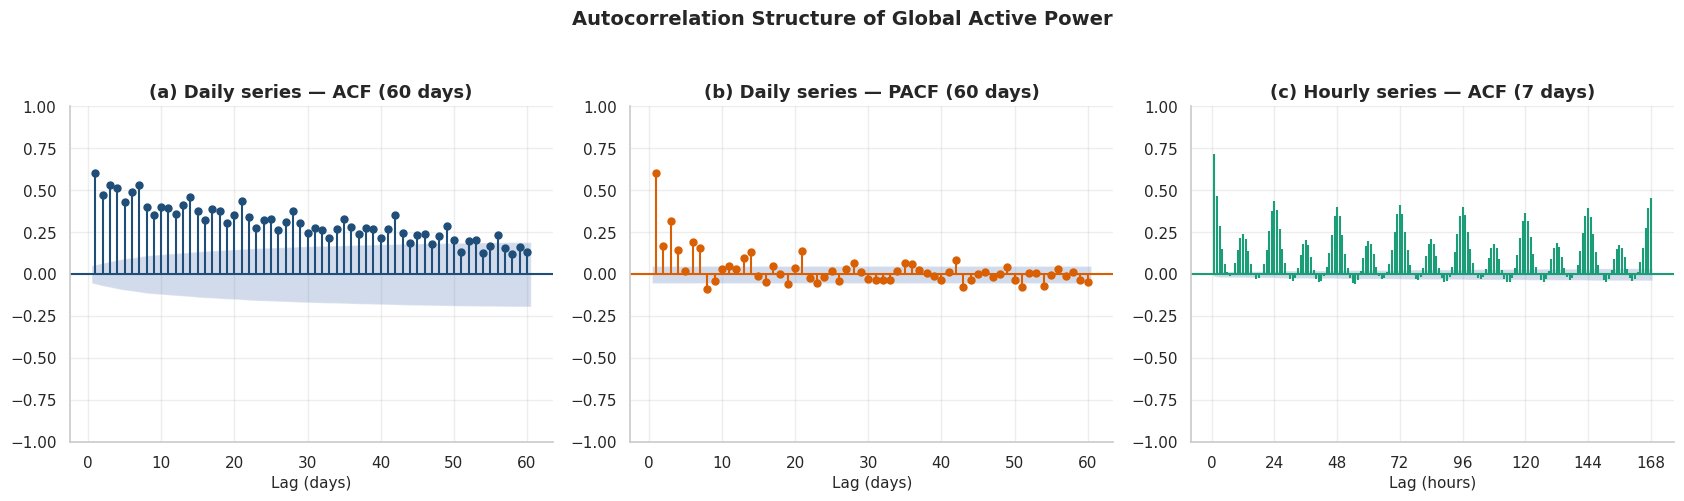

Daily  ACF: lag1 = 0.60, lag7 = 0.53, lag14 = 0.46
Hourly ACF: lag1 = 0.71, lag12 = 0.24, lag24 = 0.44, lag168 = 0.46


In [ ]:
# ----------------------------------------------------------------------------
# 9.2  ACF / PACF
# ----------------------------------------------------------------------------
from statsmodels.tsa.stattools import acf as _acf
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
plot_acf(d_full, lags=60, ax=axes[0], color=C["primary"], vlines_kwargs={"colors": C["primary"]}, zero=False)
axes[0].set_title("(a) Daily series — ACF (60 days)"); axes[0].set_xlabel("Lag (days)")
plot_pacf(d_full, lags=60, ax=axes[1], method="ywm", color=C["accent"], vlines_kwargs={"colors": C["accent"]}, zero=False)
axes[1].set_title("(b) Daily series — PACF (60 days)"); axes[1].set_xlabel("Lag (days)")
plot_acf(hourly[TARGET], lags=24 * 7, ax=axes[2], color=C["green"], vlines_kwargs={"colors": C["green"]}, zero=False, marker=None)
axes[2].set_title("(c) Hourly series — ACF (7 days)"); axes[2].set_xlabel("Lag (hours)")
axes[2].set_xticks(range(0, 24 * 7 + 1, 24))
fig.suptitle("Autocorrelation Structure of Global Active Power", fontsize=14, fontweight="bold", y=1.04)
fig.tight_layout(); save_fig(fig, "09_acf_pacf")

a_d = _acf(d_full, nlags=14); a_h = _acf(hourly[TARGET], nlags=24 * 7)
R.update(acf_d1=a_d[1], acf_d7=a_d[7], acf_d14=a_d[14], acf_h1=a_h[1], acf_h24=a_h[24], acf_h12=a_h[12], acf_h168=a_h[168])
print(f"Daily  ACF: lag1 = {a_d[1]:.2f}, lag7 = {a_d[7]:.2f}, lag14 = {a_d[14]:.2f}")
print(f"Hourly ACF: lag1 = {a_h[1]:.2f}, lag12 = {a_h[12]:.2f}, lag24 = {a_h[24]:.2f}, lag168 = {a_h[168]:.2f}")

### 9.3 Stationarity tests
A series is (weakly) stationary if its mean, variance and autocovariance do not change over time; many classical models (ARIMA) require this after differencing/de-seasonalising.

* **ADF** — null hypothesis: the series has a **unit root** (non-stationary). Small p-value ⇒ reject ⇒ evidence of stationarity.
* **KPSS** — null hypothesis: the series is **stationary** around a constant. Small p-value ⇒ reject ⇒ evidence of non-stationarity.

Reading them together: *ADF rejects & KPSS does not* ⇒ stationary; *ADF does not reject & KPSS rejects* ⇒ non-stationary; *both reject* ⇒ difference/trend-stationary ambiguity (typically seasonality or structural change).

In [ ]:
# ----------------------------------------------------------------------------
# 9.3  STATIONARITY TESTS (ADF, KPSS) on the daily series
# ----------------------------------------------------------------------------
adf_stat, adf_p, adf_lag, adf_n, adf_crit, _ = adfuller(d_full, autolag="AIC")
kpss_stat, kpss_p, kpss_lag, kpss_crit = kpss(d_full, regression="c", nlags="auto")

tests = pd.DataFrame({
    "statistic":     [adf_stat, kpss_stat],
    "p-value":       [adf_p, kpss_p],
    "lags used":     [adf_lag, kpss_lag],
    "H0":            ["unit root (non-stationary)", "stationary around a constant"],
    "reject H0 (5%)": [adf_p < .05, kpss_p < .05],
}, index=["ADF", "KPSS"])
display(tests.style.format({"statistic": "{:.3f}", "p-value": "{:.4f}"}))

if adf_p < .05 and kpss_p >= .05:    verdict = "stationary (no unit root; stable mean)"
elif adf_p >= .05 and kpss_p < .05:  verdict = "non-stationary (unit root / drifting mean)"
elif adf_p < .05 and kpss_p < .05:   verdict = "inconclusive: ADF rejects the unit root, but KPSS also rejects level-stationarity, which points to a strong seasonal / slowly varying mean component"
else:                                verdict = "inconclusive"
print("Verdict:", verdict)
R.update(adf_stat=adf_stat, adf_p=adf_p, kpss_stat=kpss_stat, kpss_p=kpss_p, stat_verdict=verdict)

,statistic,p-value,lags used,H0,reject H0 (5%)
ADF,-3.700,0.0041,22,unit root (non-stationary),True
KPSS,0.197,0.1000,23,stationary around a constant,False


Verdict: stationary (no unit root; stable mean)


In [ ]:
report_box("Time-series structure (Figures 9a–9b)", f"""
A robust STL decomposition of the daily mean series separates it into a trend, an annual seasonal component and a remainder. The annual seasonal component is strong (seasonal strength = {R['F_seas']:.2f}) and spans about {R['seas_amp']:.2f} kW from its minimum to its maximum, whereas the trend component is comparatively weak (trend strength = {R['F_trend']:.2f}; it varies only between {R['trend_range'][0]:.2f} and {R['trend_range'][1]:.2f} kW). After removing trend and annual cycle, the day of the week still explains {R['weekly_share']:.1f}% of the remaining variance, confirming a weekly pattern on top of the annual one. The remainder shows occasional large negative excursions (most visibly in August 2008), which most likely correspond to periods of reduced occupancy.

The autocorrelation analysis confirms persistent, multi-scale dependence. The daily series has an autocorrelation of {R['acf_d1']:.2f} at lag 1, {R['acf_d7']:.2f} at lag 7 and {R['acf_d14']:.2f} at lag 14; the hourly series has {R['acf_h1']:.2f} at lag 1, {R['acf_h12']:.2f} at lag 12, {R['acf_h24']:.2f} at lag 24 (same hour on the previous day) and {R['acf_h168']:.2f} at lag 168 (same hour in the previous week). The hourly ACF oscillates with a period of 24 hours, which is the signature of daily seasonality, and the weekly lag remains clearly positive. Lags of 1 day, 1 week and, for longer horizons, 1 year are therefore natural candidates for lag features and seasonal periods.

Stationarity tests on the daily series give an ADF statistic of {R['adf_stat']:.2f} (p = {R['adf_p']:.4f}) and a KPSS statistic of {R['kpss_stat']:.2f} (p = {R['kpss_p']:.4f}). Interpreted jointly, the daily series is {R['stat_verdict']}. These tests indicate the absence of a stochastic trend (unit root) and a stable long-run mean; they do not rule out the deterministic annual and weekly cycles documented above, which the tests are not designed to detect. In practical terms, the variation is dominated by recurring seasonal cycles rather than by a drifting level, so seasonal terms or seasonal features (rather than differencing alone) are advisable in the modelling stage.
""")

#### 📝 Report text — Time-series structure (Figures 9a–9b)

> A robust STL decomposition of the daily mean series separates it into a trend, an annual seasonal component and a remainder. The annual seasonal component is strong (seasonal strength = 0.56) and spans about 3.10 kW from its minimum to its maximum, whereas the trend component is comparatively weak (trend strength = 0.00; it varies only between 1.07 and 1.13 kW). After removing trend and annual cycle, the day of the week still explains 5.8% of the remaining variance, confirming a weekly pattern on top of the annual one. The remainder shows occasional large negative excursions (most visibly in August 2008), which most likely correspond to periods of reduced occupancy.
>
> The autocorrelation analysis confirms persistent, multi-scale dependence. The daily series has an autocorrelation of 0.60 at lag 1, 0.53 at lag 7 and 0.46 at lag 14; the hourly series has 0.71 at lag 1, 0.24 at lag 12, 0.44 at lag 24 (same hour on the previous day) and 0.46 at lag 168 (same hour in the previous week). The hourly ACF oscillates with a period of 24 hours, which is the signature of daily seasonality, and the weekly lag remains clearly positive. Lags of 1 day, 1 week and, for longer horizons, 1 year are therefore natural candidates for lag features and seasonal periods.
>
> Stationarity tests on the daily series give an ADF statistic of -3.70 (p = 0.0041) and a KPSS statistic of 0.20 (p = 0.1000). Interpreted jointly, the daily series is stationary (no unit root; stable mean). These tests indicate the absence of a stochastic trend (unit root) and a stable long-run mean; they do not rule out the deterministic annual and weekly cycles documented above, which the tests are not designed to detect. In practical terms, the variation is dominated by recurring seasonal cycles rather than by a drifting level, so seasonal terms or seasonal features (rather than differencing alone) are advisable in the modelling stage.

---
# 10. Time-Series Train / Validation / Test Split (Task 1A · Part 11)

### 10.1 Why a time series must be split chronologically, not randomly

A random, shuffled `train_test_split` is the correct tool for independent observations — but **time-series observations are not independent**. Shuffling is harmful for three reasons:

1. **Look-ahead (temporal) leakage.** In a shuffled split, a test minute at 20:05 has its neighbours at 20:04 and 20:06 in the training set. Because consecutive minutes are almost identical (the lag-1 autocorrelation is ≈ 0.97), the model can "predict" the test point by simply interpolating between its neighbours. The model sees the *future* of the points it is later evaluated on, and the resulting score is wildly optimistic.
2. **Unrealistic evaluation.** In production a forecaster only ever knows the past. A chronological split reproduces exactly this situation: train on the past, tune on the immediate future (validation), and report performance on the most recent, completely unseen period (test).
3. **Destroyed temporal structure.** Lag features, rolling statistics, seasonality and autocorrelation all rely on an unbroken time order; shuffling invalidates them.

**Design of the split.**
* **70 % train / 15 % validation / 15 % test**, in strict time order — train = oldest data, test = newest.
* The validation set is used for model selection and hyper-parameter tuning; the test set is touched **once**, at the very end.
* The split is performed on the cleaned **minute-level** dataset. Because the minute grid is complete (no absent timestamps), 70 %/15 %/15 % of the *rows* is also 70 %/15 %/15 % of the *time*.
* Any scaler, encoder or imputation profile must be fitted on **training data only**. This was already respected for the seasonal imputation profile (§5.2); the split below uses exactly the same cut-off.

In [ ]:
# ----------------------------------------------------------------------------
# 10.2  CHRONOLOGICAL SPLIT  70 / 15 / 15
# ----------------------------------------------------------------------------
EXPORT_COLS = NUMERIC + ["Imputed"]                          # 7 measurements + Unmetered_Wh + imputation flag
data = df_clean[EXPORT_COLS].reset_index()                    # 'Datetime' becomes a column
TS = "Datetime"                                               # timestamp column name

# sort by timestamp (explicit, even though the index is already chronological)
data = data.sort_values(TS).reset_index(drop=True)

train_size = int(len(data) * TRAIN_FRAC)
val_size   = int(len(data) * VAL_FRAC)

train_df = data.iloc[:train_size]                             # oldest 70 %
val_df   = data.iloc[train_size:train_size + val_size]        # next 15 %
test_df  = data.iloc[train_size + val_size:]                  # newest 15 % (remainder)

splits = {"Training": train_df, "Validation": val_df, "Testing": test_df}
for name, part in splits.items():
    print(f"{name}:")
    print(f"    Start:   {part[TS].iloc[0]}")
    print(f"    End:     {part[TS].iloc[-1]}")
    print(f"    Records: {len(part):,}   ({len(part)/len(data)*100:.2f} % of the data, "
          f"{(part[TS].iloc[-1] - part[TS].iloc[0]).days + 1} days)")
    print()

# ---- integrity checks ------------------------------------------------------
assert len(train_df) + len(val_df) + len(test_df) == len(data)
assert train_df[TS].max() < val_df[TS].min() and val_df[TS].max() < test_df[TS].min(), "Splits overlap in time!"
assert train_df[TS].is_monotonic_increasing and val_df[TS].is_monotonic_increasing and test_df[TS].is_monotonic_increasing
assert train_df[TS].iloc[-1] == train_cutoff, "Split cut-off differs from the cut-off used for the seasonal profile!"
print("✔ Integrity checks passed: no overlap, strictly chronological, sizes add up, cut-off consistent with §5.2.")

# ---- summary table ----------------------------------------------------------
summary = pd.DataFrame({
    "start": [p[TS].iloc[0] for p in splits.values()], "end": [p[TS].iloc[-1] for p in splits.values()],
    "records": [len(p) for p in splits.values()], "share_%": [len(p) / len(data) * 100 for p in splits.values()],
    "days": [(p[TS].iloc[-1] - p[TS].iloc[0]).days + 1 for p in splits.values()],
    "imputed_%": [p["Imputed"].mean() * 100 for p in splits.values()],
    "mean_kW": [p[TARGET].mean() for p in splits.values()], "median_kW": [p[TARGET].median() for p in splits.values()],
    "std_kW": [p[TARGET].std() for p in splits.values()],
}, index=list(splits))
display(summary.style.format({"records": "{:,.0f}", "share_%": "{:.2f}", "imputed_%": "{:.2f}", "mean_kW": "{:.3f}",
                              "median_kW": "{:.3f}", "std_kW": "{:.3f}"}).set_caption("Train / validation / test split"))
R["split"] = summary

Training:
    Start:   2006-12-16 17:24:00
    End:     2009-09-20 12:44:00
    Records: 1,452,681   (70.00 % of the data, 1009 days)

Validation:
    Start:   2009-09-20 12:45:00
    End:     2010-04-24 16:52:00
    Records: 311,288   (15.00 % of the data, 217 days)

Testing:
    Start:   2010-04-24 16:53:00
    End:     2010-11-26 21:02:00
    Records: 311,290   (15.00 % of the data, 217 days)

✔ Integrity checks passed: no overlap, strictly chronological, sizes add up, cut-off consistent with §5.2.


,start,end,records,share_%,days,imputed_%,mean_kW,median_kW,std_kW
Training,2006-12-16 17:24:00,2009-09-20 12:44:00,"1,452,681",70.00,1009,0.57,1.087,0.554,1.088
Validation,2009-09-20 12:45:00,2010-04-24 16:52:00,"311,288",15.00,217,1.66,1.245,1.178,1.042
Testing,2010-04-24 16:53:00,2010-11-26 21:02:00,"311,290",15.00,217,4.01,0.964,0.587,0.854


### 10.3 Visualising the split
* **(top)** the daily mean of the target on the full timeline, coloured by split, with the boundary dates annotated,
* **(bottom left)** share of records per split,
* **(bottom centre)** which **calendar months** each split covers — important because the series is strongly seasonal,
* **(bottom right)** distribution of the target in each split — a check for distribution shift between the periods.

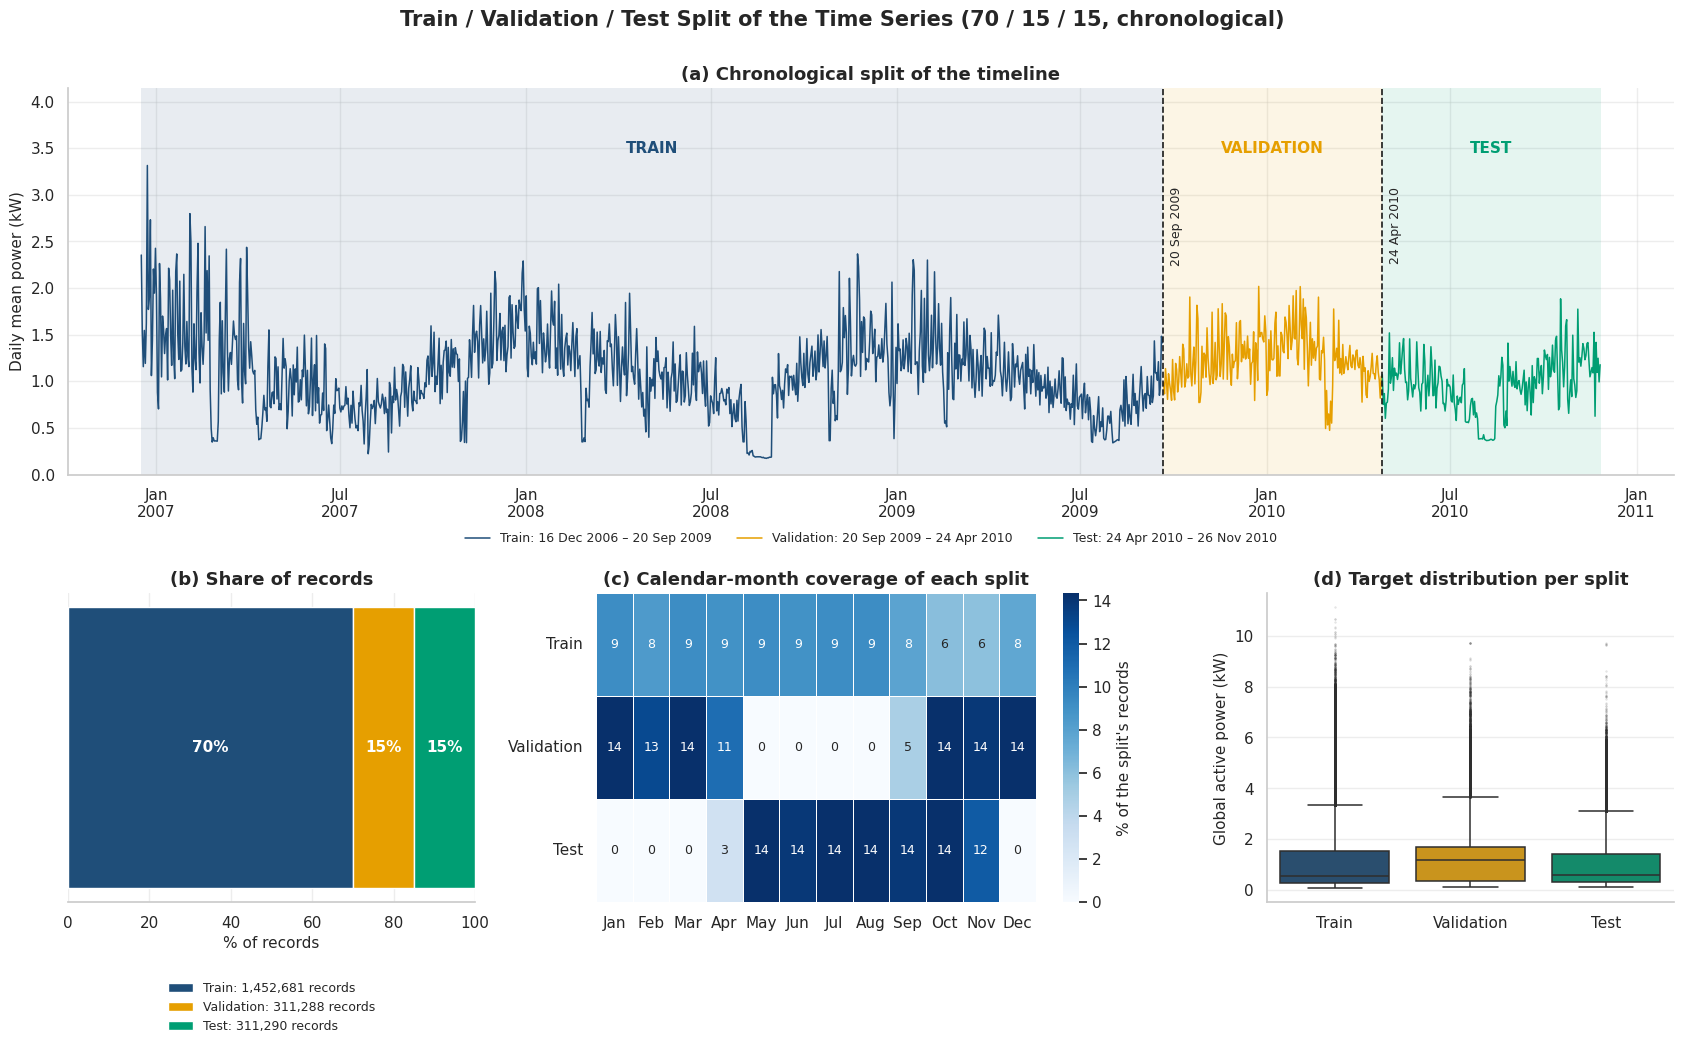

Calendar months present in validation: ['Jan', 'Feb', 'Mar', 'Apr', 'Sep', 'Oct', 'Nov', 'Dec']
Calendar months present in test      : ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov']


In [ ]:
# ----------------------------------------------------------------------------
# 10.3  VISUALISATION OF THE SPLIT
# ----------------------------------------------------------------------------
daily_split = daily[TARGET].copy()
fig = plt.figure(figsize=(17, 10.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1], width_ratios=[1, 1.35, 1])

# (top) timeline
ax = fig.add_subplot(gs[0, :])
for (name, part), col, lab in zip(splits.items(), SPLIT_COLORS.values(), ["Train", "Validation", "Test"]):
    t0, t1 = part[TS].iloc[0], part[TS].iloc[-1]
    seg = daily_split.loc[t0:t1]
    ax.axvspan(t0, t1, color=col, alpha=.10, lw=0)
    ax.plot(seg.index, seg.values, color=col, lw=1.1, label=f"{lab}: {t0:%d %b %Y} – {t1:%d %b %Y}")
    ax.text(t0 + (t1 - t0) / 2, daily_split.max() * 1.03, lab.upper(), ha="center", va="bottom", fontsize=11, fontweight="bold", color=col)
for t in [val_df[TS].iloc[0], test_df[TS].iloc[0]]:
    ax.axvline(t, color="k", ls="--", lw=1.2)
    ax.annotate(f"{t:%d %b %Y}", xy=(t, daily_split.max() * .93), xytext=(5, 0), textcoords="offset points", fontsize=9, rotation=90, va="top")
ax.set_ylim(0, daily_split.max() * 1.25); ax.set_ylabel("Daily mean power (kW)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("(a) Chronological split of the timeline"); ax.legend(loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.12))

# (bottom left) proportions
ax = fig.add_subplot(gs[1, 0])
sizes = [len(p) for p in splits.values()]
left = 0
for sz, (lab, col) in zip(sizes, SPLIT_COLORS.items()):
    ax.barh([0], [sz / len(data) * 100], left=left, color=col, edgecolor="white", label=lab)
    ax.text(left + sz / len(data) * 50, 0, f"{sz/len(data)*100:.0f}%", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += sz / len(data) * 100
ax.set_xlim(0, 100); ax.set_yticks([]); ax.set_xlabel("% of records"); ax.set_title("(b) Share of records")
ax.legend([f"{l}: {sz:,} records" for l, sz in zip(SPLIT_COLORS, sizes)], loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9, ncol=1)
ax.spines["left"].set_visible(False)

# (bottom centre) calendar-month coverage
ax = fig.add_subplot(gs[1, 1])
cover = pd.DataFrame({lab: part[TS].dt.month.value_counts(normalize=True).reindex(range(1, 13), fill_value=0) * 100
                      for lab, part in zip(["Train", "Validation", "Test"], splits.values())}).T
sns.heatmap(cover, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of the split's records"}, linewidths=.5, linecolor="white", ax=ax,
            annot_kws={"size": 9})
ax.set_xticklabels(MONTHS, rotation=0); ax.set_yticklabels(ax.get_yticklabels(), rotation=0); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("(c) Calendar-month coverage of each split")

# (bottom right) distribution per split
ax = fig.add_subplot(gs[1, 2])
long = pd.concat([part[[TARGET]].assign(Split=lab) for lab, part in zip(["Train", "Validation", "Test"], splits.values())])
sns.boxplot(data=long, x="Split", y=TARGET, palette=list(SPLIT_COLORS.values()), ax=ax, fliersize=1, linewidth=1.1,
            flierprops=dict(marker=".", markersize=1.2, alpha=.15))
ax.set_ylabel("Global active power (kW)"); ax.set_xlabel(""); ax.set_title("(d) Target distribution per split")

fig.suptitle("Train / Validation / Test Split of the Time Series (70 / 15 / 15, chronological)", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, "10_train_val_test_split")

# facts used later
months_test = sorted(test_df[TS].dt.month.unique()); months_val = sorted(val_df[TS].dt.month.unique())
R.update(months_test=[MONTHS[m - 1] for m in months_test], months_val=[MONTHS[m - 1] for m in months_val],
         test_has_winter=any(m in (12, 1, 2) for m in months_test),
         val_has_summer=any(m in (6, 7, 8) for m in months_val))
print("Calendar months present in validation:", R["months_val"]); print("Calendar months present in test      :", R["months_test"])

In [ ]:
sp = R["split"]
report_box("Train / validation / test split methodology", f"""
Because the observations of a time series are serially dependent, the data were divided chronologically rather than randomly. After sorting the {len(data):,} one-minute records by timestamp, the oldest 70% were assigned to the training set, the following 15% to the validation set and the most recent 15% to the test set, using integer-based boundaries so that the three subsets are contiguous, non-overlapping and exhaustive. The training set contains {sp.loc['Training','records']:,.0f} records from {sp.loc['Training','start']:%d %B %Y} to {sp.loc['Training','end']:%d %B %Y} ({sp.loc['Training','days']:.0f} days); the validation set contains {sp.loc['Validation','records']:,.0f} records from {sp.loc['Validation','start']:%d %B %Y} to {sp.loc['Validation','end']:%d %B %Y} ({sp.loc['Validation','days']:.0f} days); and the test set contains {sp.loc['Testing','records']:,.0f} records from {sp.loc['Testing','start']:%d %B %Y} to {sp.loc['Testing','end']:%d %B %Y} ({sp.loc['Testing','days']:.0f} days). The training data are used to fit models, the validation data to tune hyper-parameters and select between models, and the test data are reserved for a single, final assessment of generalisation performance. This design mimics real forecasting, in which a model trained on the past must predict an unseen future, and it avoids the temporal leakage that occurs under random shuffling, where neighbouring minutes with an autocorrelation of about {R['acf1']:.2f} would appear in both the training and the evaluation sets and inflate the apparent accuracy. All data-dependent preprocessing, including the seasonal profile used for imputation, was estimated from the training period only, and the split boundaries were verified programmatically to be strictly ordered in time.

Two properties of the split deserve attention. First, because the record covers less than four years, the validation set covers {', '.join(R['months_val'])} and the test set covers {', '.join(R['months_test'])}; the test set therefore {'includes' if R['test_has_winter'] else 'does not include'} winter months and the validation set {'includes' if R['val_has_summer'] else 'does not include'} summer months, so neither set is representative of a complete annual cycle. Second, the distribution of the target differs markedly across the periods (mean power of {sp.loc['Training','mean_kW']:.2f}, {sp.loc['Validation','mean_kW']:.2f} and {sp.loc['Testing','mean_kW']:.2f} kW and median power of {sp.loc['Training','median_kW']:.2f}, {sp.loc['Validation','median_kW']:.2f} and {sp.loc['Testing','median_kW']:.2f} kW in the training, validation and test sets respectively). This is mainly a consequence of the different seasonal composition of the subsets (the validation period is dominated by autumn and winter and the test period by spring and summer) rather than evidence of an error, but it means that validation and test errors are not directly comparable and that model selection based on a single validation block may be biased towards winter behaviour; rolling-origin (expanding-window) cross-validation on the training data is a useful complement. In addition, {sp.loc['Testing','imputed_%']:.1f}% of the test records are imputed (compared with {sp.loc['Training','imputed_%']:.1f}% in the training set) because several measurement outages fall late in the series. The `Imputed` flag has been retained in the exported files so that evaluation can optionally exclude reconstructed minutes.
""")

#### 📝 Report text — Train / validation / test split methodology

> Because the observations of a time series are serially dependent, the data were divided chronologically rather than randomly. After sorting the 2,075,259 one-minute records by timestamp, the oldest 70% were assigned to the training set, the following 15% to the validation set and the most recent 15% to the test set, using integer-based boundaries so that the three subsets are contiguous, non-overlapping and exhaustive. The training set contains 1,452,681 records from 16 December 2006 to 20 September 2009 (1009 days); the validation set contains 311,288 records from 20 September 2009 to 24 April 2010 (217 days); and the test set contains 311,290 records from 24 April 2010 to 26 November 2010 (217 days). The training data are used to fit models, the validation data to tune hyper-parameters and select between models, and the test data are reserved for a single, final assessment of generalisation performance. This design mimics real forecasting, in which a model trained on the past must predict an unseen future, and it avoids the temporal leakage that occurs under random shuffling, where neighbouring minutes with an autocorrelation of about 0.97 would appear in both the training and the evaluation sets and inflate the apparent accuracy. All data-dependent preprocessing, including the seasonal profile used for imputation, was estimated from the training period only, and the split boundaries were verified programmatically to be strictly ordered in time.
>
> Two properties of the split deserve attention. First, because the record covers less than four years, the validation set covers Jan, Feb, Mar, Apr, Sep, Oct, Nov, Dec and the test set covers Apr, May, Jun, Jul, Aug, Sep, Oct, Nov; the test set therefore does not include winter months and the validation set does not include summer months, so neither set is representative of a complete annual cycle. Second, the distribution of the target differs markedly across the periods (mean power of 1.09, 1.24 and 0.96 kW and median power of 0.55, 1.18 and 0.59 kW in the training, validation and test sets respectively). This is mainly a consequence of the different seasonal composition of the subsets (the validation period is dominated by autumn and winter and the test period by spring and summer) rather than evidence of an error, but it means that validation and test errors are not directly comparable and that model selection based on a single validation block may be biased towards winter behaviour; rolling-origin (expanding-window) cross-validation on the training data is a useful complement. In addition, 4.0% of the test records are imputed (compared with 0.6% in the training set) because several measurement outages fall late in the series. The `Imputed` flag has been retained in the exported files so that evaluation can optionally exclude reconstructed minutes.

---
# 11. Save Processed Data

We export the three splits as CSV files, keeping the timestamp as the first column (`Datetime`). Each file contains the seven original measurements, the derived `Unmetered_Wh`, and the `Imputed` flag (1 = value reconstructed in §5). Values are written with 4 decimals (the raw data has 3). After writing, every file is **read back and verified** (row counts, date ranges, no missing values).

We also write **one cleaned CSV per year** (`processed_data/by_year/`), so each file stays below Excel's 1,048,576-row limit and can be opened without losing data.

As a convenience for the modelling stage, we also export **hourly-aggregated** versions (`*_hourly.csv`). Each split is resampled **separately**, so no information crosses the split boundaries. Power-like variables (`kW`, `kVAr`, `V`, `A`) are averaged; the sub-metering and unmetered energies (Wh) are summed; `Imputed` becomes the number of imputed minutes in that hour.

In [ ]:
# ----------------------------------------------------------------------------
# 11. EXPORT train.csv / validation.csv / test.csv  (+ optional hourly versions)
# ----------------------------------------------------------------------------
files = {"train": train_df, "validation": val_df, "test": test_df}
for name, part in files.items():
    part.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False, float_format="%.4f")

# --- optional hourly aggregates (each split resampled on its own) ------------
agg = {c: "mean" for c in ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]}
agg.update({c: "sum" for c in SUB_COLS + ["Unmetered_Wh", "Imputed"]})
for name, part in files.items():
    part.set_index(TS).resample("h").agg(agg).reset_index().to_csv(
        os.path.join(OUT_DIR, f"{name}_hourly.csv"), index=False, float_format="%.4f")

# --- one cleaned file per year (each fits in Excel's 1,048,576-row limit) ----------
os.makedirs(os.path.join(OUT_DIR, "by_year"), exist_ok=True)
for yr_, g in data.groupby(data[TS].dt.year):
    g.to_csv(os.path.join(OUT_DIR, "by_year", f"cleaned_{yr_}.csv"), index=False, float_format="%.4f")
by_year_rows = {yr_: len(g) for yr_, g in data.groupby(data[TS].dt.year)}
assert sum(by_year_rows.values()) == len(data)
print("Per-year files (open these in Excel if needed):", {k: f"{v:,}" for k, v in by_year_rows.items()})

# --- read back and verify ----------------------------------------------------
rows = []
for name, part in files.items():
    chk = pd.read_csv(os.path.join(OUT_DIR, f"{name}.csv"), parse_dates=[TS])
    assert len(chk) == len(part) and chk[TS].is_monotonic_increasing and chk.isna().sum().sum() == 0
    rows.append({"file": f"{name}.csv", "records": len(chk), "start": chk[TS].min(), "end": chk[TS].max(),
                 "columns": chk.shape[1], "size_MB": os.path.getsize(os.path.join(OUT_DIR, f"{name}.csv")) / 1024**2})
display(pd.DataFrame(rows).set_index("file").style.format({"records": "{:,.0f}", "size_MB": "{:.1f}"}).set_caption("Saved files (verified by reading back)"))
print("Columns:", list(chk.columns))
print("\nFiles in", OUT_DIR + "/:", sorted(os.listdir(OUT_DIR)))
display(pd.read_csv(os.path.join(OUT_DIR, "train.csv"), nrows=3))

Per-year files (open these in Excel if needed): {2006: '21,996', 2007: '525,600', 2008: '527,040', 2009: '525,600', 2010: '475,023'}


,records,start,end,columns,size_MB
file,,,,,
train.csv,"1,452,681",2006-12-16 17:24:00,2009-09-20 12:44:00,10,111.9
validation.csv,"311,288",2009-09-20 12:45:00,2010-04-24 16:52:00,10,24.0
test.csv,"311,290",2010-04-24 16:53:00,2010-11-26 21:02:00,10,23.9


Columns: ['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Unmetered_Wh', 'Imputed']

Files in processed_data/: ['by_year', 'test.csv', 'test_hourly.csv', 'train.csv', 'train_hourly.csv', 'validation.csv', 'validation_hourly.csv']


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Unmetered_Wh,Imputed
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,52.2667,0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,72.3333,0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,70.5667,0


---
# 12. Key Insights

The summary below is generated from the computed results of this notebook (so it stays correct if the data are updated).

In [ ]:
sp = R["split"]; sh = R["share"]
display(Markdown(f"""
| Topic | Finding |
|---|---|
| **Dataset size** | {R['n_rows']:,} one-minute records × {R['n_cols']} measurements (plus derived `Unmetered_Wh`); one household. |
| **Time range** | {R['start']:%d %b %Y %H:%M} → {R['end']:%d %b %Y %H:%M} ({R['span_days']:,} days ≈ {R['span_years']:.2f} years; only 2007–2009 are complete calendar years). |
| **Frequency** | Regular **{R['granularity']}-level** sampling; **no timestamps are absent** from the grid. |
| **Missing values** | {R['miss_count']:,} rows ({R['miss_pct']:.2f}%), always all variables at once, in {R['n_gaps']} gaps (median {R['gap_median']:.0f} min, longest {R['gap_max']:,} min ≈ {R['gap_max']/1440:.1f} days). Handled with hybrid imputation (interpolation ≤ {GAP_THRESHOLD_MIN} min, seasonal profile beyond). No duplicate timestamps. |
| **Target distribution** | Mean {R['gap_mean']:.2f} kW, median {R['gap_median']:.2f} kW, strongly right-skewed (skew {R['gap_skew']:.2f}) and **bimodal** (modes ≈ {R['hist_mode']:.1f} and ≈ {R['hist_mode2']:.1f} kW). Sub-meters are zero-inflated. |
| **Outliers** | {R['p_iqr']:.1f}% of minutes exceed the Tukey fence ({R['hi_f']:.2f} kW); they are genuine peaks (physically coherent, persistent, evening/morning) → **retained**. |
| **Seasonality** | Strong at three scales: intraday (peak ≈ {R['peak_hour']:02d}:00, trough ≈ {R['trough_hour']:02d}:00), weekly (weekend {R['we_mean']:.2f} vs weekday {R['wd_mean']:.2f} kW) and annual (peak month {R['peak_month']} {R['peak_v']:.2f} kW vs lowest {R['low_month']} {R['low_v']:.2f} kW). |
| **Trend** | Essentially flat (annual means {R['ann_means'][2007]:.2f} / {R['ann_means'][2008]:.2f} / {R['ann_means'][2009]:.2f} kW for 2007–09), but the median rises while peaks shrink — a gradual change of distribution shape. |
| **Dependence** | Very persistent: lag-1 min r = {R['acf1']:.2f}; same hour yesterday r = {R['acf_h24']:.2f}; same hour last week r = {R['acf_h168']:.2f}. |
| **Split** | Train {sp.loc['Training','start']:%b %Y}–{sp.loc['Training','end']:%b %Y} ({sp.loc['Training','share_%']:.0f}%), validation {sp.loc['Validation','start']:%b %Y}–{sp.loc['Validation','end']:%b %Y} ({sp.loc['Validation','share_%']:.0f}%), test {sp.loc['Testing','start']:%b %Y}–{sp.loc['Testing','end']:%b %Y} ({sp.loc['Testing','share_%']:.0f}%). |

**Potential challenges for the forecasting stage**

1. **Volume and noise.** Two million minute-level points with abrupt, partly unpredictable spikes; consider forecasting at hourly/daily resolution or using minute data only for short horizons.
2. **Multiple seasonalities.** Daily, weekly and annual cycles coexist, and only ≈ 3 full annual cycles are available in training — limited for models that must learn yearly patterns.
3. **Seasonally unbalanced evaluation sets.** The validation set contains {', '.join(R['months_val'])} (no summer) and the test set {', '.join(R['months_test'])} (no winter); metrics are not comparable between them. Expanding-window cross-validation is advisable.
4. **Distribution shift.** Median power rises and extreme peaks decline over the years, so the most recent period differs from early training years.
5. **Imputed data concentrated late in the series.** {sp.loc['Testing','imputed_%']:.1f}% of test records are imputed versus {sp.loc['Training','imputed_%']:.1f}% of training records; consider evaluating with and without the `Imputed` flag.
6. **Leakage-prone predictors.** `Global_intensity` is almost identical to the target (r ≈ {R['corr_top']['Global_intensity']:.2f}) and `Unmetered_Wh` is derived from it; neither may be used as a same-time predictor for genuine forecasting.
7. **Heavy tails and zero inflation.** RMSE is dominated by peaks; use MAE/MAPE-type metrics as well and test log/√ transforms.
8. **Single household.** Findings and models may not generalise to other households.
"""))


| Topic | Finding |
|---|---|
| **Dataset size** | 2,075,259 one-minute records × 7 measurements (plus derived `Unmetered_Wh`); one household. |
| **Time range** | 16 Dec 2006 17:24 → 26 Nov 2010 21:02 (1,441 days ≈ 3.95 years; only 2007–2009 are complete calendar years). |
| **Frequency** | Regular **minute-level** sampling; **no timestamps are absent** from the grid. |
| **Missing values** | 25,979 rows (1.25%), always all variables at once, in 71 gaps (median 1 min, longest 11.122 min ≈ 0.0 days). Handled with hybrid imputation (interpolation ≤ 240 min, seasonal profile beyond). No duplicate timestamps. |
| **Target distribution** | Mean 1.09 kW, median 0.62 kW, strongly right-skewed (skew 1.79) and **bimodal** (modes ≈ 0.3 and ≈ 1.4 kW). Sub-meters are zero-inflated. |
| **Outliers** | 4.6% of minutes exceed the Tukey fence (3.35 kW); they are genuine peaks (physically coherent, persistent, evening/morning) → **retained**. |
| **Seasonality** | Strong at three scales: intraday (peak ≈ 20:00, trough ≈ 04:00), weekly (weekend 1.23 vs weekday 1.04 kW) and annual (peak month Jan 1.45 kW vs lowest Aug 0.60 kW). |
| **Trend** | Essentially flat (annual means 1.12 / 1.07 / 1.08 kW for 2007–09), but the median rises while peaks shrink — a gradual change of distribution shape. |
| **Dependence** | Very persistent: lag-1 min r = 0.97; same hour yesterday r = 0.44; same hour last week r = 0.46. |
| **Split** | Train Dec 2006–Sep 2009 (70%), validation Sep 2009–Apr 2010 (15%), test Apr 2010–Nov 2010 (15%). |

**Potential challenges for the forecasting stage**

1. **Volume and noise.** Two million minute-level points with abrupt, partly unpredictable spikes; consider forecasting at hourly/daily resolution or using minute data only for short horizons.
2. **Multiple seasonalities.** Daily, weekly and annual cycles coexist, and only ≈ 3 full annual cycles are available in training — limited for models that must learn yearly patterns.
3. **Seasonally unbalanced evaluation sets.** The validation set contains Jan, Feb, Mar, Apr, Sep, Oct, Nov, Dec (no summer) and the test set Apr, May, Jun, Jul, Aug, Sep, Oct, Nov (no winter); metrics are not comparable between them. Expanding-window cross-validation is advisable.
4. **Distribution shift.** Median power rises and extreme peaks decline over the years, so the most recent period differs from early training years.
5. **Imputed data concentrated late in the series.** 4.0% of test records are imputed versus 0.6% of training records; consider evaluating with and without the `Imputed` flag.
6. **Leakage-prone predictors.** `Global_intensity` is almost identical to the target (r ≈ 1.00) and `Unmetered_Wh` is derived from it; neither may be used as a same-time predictor for genuine forecasting.
7. **Heavy tails and zero inflation.** RMSE is dominated by peaks; use MAE/MAPE-type metrics as well and test log/√ transforms.
8. **Single household.** Findings and models may not generalise to other households.


---
# 13. Final "Task 1A Report" (Task 1A · Parts 9–10)

The text below is a complete, academically styled write-up of Task 1A. It is generated from the notebook's results, so every number matches the analysis. **Copy the rendered text into the report** and insert the figures saved in the `figures/` folder (file names are given in the figure captions list at the end).

In [ ]:
sp = R["split"]; sh = R["share"]; ct = R["corr_top"]; yq = R["yq"]
display(Markdown(f"""
## Task 1A Report — Understanding and Preparing the Household Power Consumption Time Series

### 1. Introduction and dataset description
This section describes the dataset used for the forecasting study and the preparatory analysis performed before modelling. The dataset records the electricity consumption of a single household at one-minute resolution. It contains {R['n_rows']:,} observations of seven measured variables: global active power (kW), global reactive power (kVAr), mains voltage (V), global current intensity (A) and three sub-metering channels (Wh) for the kitchen, the laundry room and the electric water-heater/air-conditioner. Global active power was selected as the target variable because it directly represents the household's electrical load. A further variable, the unmetered active energy (the part of the consumption not captured by the sub-meters), was derived from the data.

### 2. Time-series characteristics
Date and time were stored in separate text columns and were combined into a single datetime index (day-first format), which was sorted chronologically. The series starts on {R['start']:%d %B %Y} and ends on {R['end']:%d %B %Y}, spanning {R['span_days']:,} days (about {R['span_years']:.2f} years). Consecutive observations are exactly one minute apart and no timestamp is absent from the regular grid, so the data are a complete, regularly sampled {R['granularity']}-level time series. Only 2007, 2008 and 2009 are complete calendar years.

### 3. Data quality and missing-value treatment
No duplicate timestamps and no negative or physically implausible values were found; voltage remained between {R['v_min']:.0f} and {R['v_max']:.0f} V and the current and power measurements were mutually consistent within the resolution of the instruments. However, {R['miss_count']:,} records ({R['miss_pct']:.2f}%) were missing, always for all variables simultaneously, which indicates outages of the acquisition system. The missing minutes form {R['n_gaps']} gaps; most are only a minute long, but {R['n_long_gaps']} gaps exceed {GAP_THRESHOLD_MIN} minutes and the longest lasts {R['gap_max']/1440:.1f} days. As the gaps are not randomly distributed and the time grid must remain intact, rows were not deleted. A hybrid imputation was applied: time-weighted linear interpolation for gaps of up to {GAP_THRESHOLD_MIN} minutes and, for longer outages, the mean value for the same weekday, hour and minute estimated from the training period only. A masking experiment confirmed that interpolation is the more accurate method for short gaps and the seasonal profile for long gaps. The procedure changed no variable mean by more than {R['max_mean_shift_pct']:.2f}%, although the seasonal fill is smoother than real observations. An indicator column marks all imputed records.

### 4. Descriptive statistics and distributions
Global active power averages {R['gap_mean']:.2f} kW (median {R['gap_median']:.2f} kW, standard deviation {R['gap_std']:.2f} kW) and ranges up to {R['gap_max']:.2f} kW. The distribution is strongly right-skewed (skewness {R['gap_skew']:.2f}) and bimodal, with a standby mode near {R['hist_mode']:.1f} kW and a secondary mode near {R['hist_mode2']:.1f} kW that is consistent with the water-heater/air-conditioner circuit being active. Total consumption was approximately {R['total_kwh']:,.0f} kWh ({R['daily_kwh']:.1f} kWh per day). {sh['Unmetered remainder']:.0f}% of the energy is unmetered, {sh['Water-heater & A/C (Sub_metering_3)']:.0f}% is used by the water-heater and air-conditioner, {sh['Laundry (Sub_metering_2)']:.0f}% in the laundry and {sh['Kitchen (Sub_metering_1)']:.0f}% in the kitchen. Voltage is approximately normally distributed, whereas the sub-metering variables are zero-inflated. Global active power is almost perfectly correlated with global intensity (r = {ct['Global_intensity']:.2f}), moderately to strongly with the water-heater/air-conditioner sub-meter (r = {ct['Sub_metering_3']:.2f}) and negatively with voltage (r = {ct['Voltage']:.2f}).

### 5. Trends and seasonality
The series shows no strong long-term trend: annual means are {R['ann_means'][2007]:.2f}, {R['ann_means'][2008]:.2f} and {R['ann_means'][2009]:.2f} kW for 2007–2009. Beneath the stable mean, however, the distribution changes gradually: the median rises from {yq.loc[2007,'median']:.2f} to {yq.loc[2010,'median']:.2f} kW between 2007 and 2010 while the standard deviation falls from {yq.loc[2007,'std']:.2f} to {yq.loc[2010,'std']:.2f} kW. Three superimposed seasonal cycles are present. Intraday, demand is lowest at about {R['trough_hour']:02d}:00 and highest at about {R['peak_hour']:02d}:00, with an additional sharp morning peak on weekdays that is absent at weekends. Weekly, consumption is higher at weekends ({R['we_mean']:.2f} kW) than on weekdays ({R['wd_mean']:.2f} kW). Annually, consumption is highest in {R['peak_month']} ({R['peak_v']:.2f} kW) and lowest in {R['low_month']} ({R['low_v']:.2f} kW), a ratio of {R['peak_v']/R['low_v']:.1f}; August 2008 was exceptionally low ({R['aug08']:.2f} kW), probably due to prolonged absence. STL decomposition confirms strong annual seasonality (strength {R['F_seas']:.2f}) and a weak trend (strength {R['F_trend']:.2f}). Autocorrelation is high at lags of one hour, one day (r = {R['acf_h24']:.2f} for hourly data) and one week (r = {R['acf_h168']:.2f}), and the augmented Dickey–Fuller and KPSS tests (p = {R['adf_p']:.3f} and p ≥ {R['kpss_p']:.2f}) indicate no unit root in the daily series.

### 6. Outlier analysis
{R['p_iqr']:.1f}% of the minutes exceed Tukey's upper fence of {R['hi_f']:.2f} kW and {R['p_ext']:.1f}% exceed the extreme fence of {R['ext_f']:.2f} kW. These values are physically coherent (implied power factor of about {R['pf_med']:.2f}), persistent (median run of {R['run_med']:.0f} minutes) and concentrated in the morning and evening peak hours; they therefore represent genuine appliance usage rather than errors. They were retained, because removing them would eliminate the peaks that a demand-forecasting model must predict, and sensitivity to them should be controlled in the modelling stage through robust metrics, transformations or training-set-based winsorisation.

### 7. Train / validation / test split
Time-series observations are serially dependent (lag-one autocorrelation of {R['acf1']:.2f}), so random shuffling would place near-identical neighbouring minutes in both the training and the evaluation data and produce over-optimistic performance estimates. The data were therefore sorted by time and divided chronologically into 70% training ({sp.loc['Training','start']:%d %b %Y} – {sp.loc['Training','end']:%d %b %Y}; {sp.loc['Training','records']:,.0f} records), 15% validation ({sp.loc['Validation','start']:%d %b %Y} – {sp.loc['Validation','end']:%d %b %Y}; {sp.loc['Validation','records']:,.0f} records) and 15% test ({sp.loc['Testing','start']:%d %b %Y} – {sp.loc['Testing','end']:%d %b %Y}; {sp.loc['Testing','records']:,.0f} records). The subsets are contiguous and non-overlapping, which was verified programmatically, and all data-dependent preprocessing was fitted on the training data only. The validation set covers {', '.join(R['months_val'])} and the test set {', '.join(R['months_test'])}, so neither covers a full annual cycle and their error levels are not directly comparable. Mean power is {sp.loc['Training','mean_kW']:.2f}, {sp.loc['Validation','mean_kW']:.2f} and {sp.loc['Testing','mean_kW']:.2f} kW in the three subsets, largely reflecting their seasonal composition. {sp.loc['Testing','imputed_%']:.1f}% of the test records are imputed (training: {sp.loc['Training','imputed_%']:.1f}%).

### 8. Implications for forecasting
(i) Seasonal structure at daily, weekly and annual scales should be represented explicitly (seasonal terms, calendar features or lag features at 24 h and 168 h). (ii) Because of the high noise and the skewed, zero-inflated distribution, an hourly or daily aggregation level and robust error metrics (MAE alongside RMSE) are advisable. (iii) Global intensity and the derived unmetered energy must not be used as concurrent predictors. (iv) Evaluation should consider the seasonal imbalance between validation and test sets, for example through expanding-window cross-validation, and may report results with and without imputed periods. (v) The gradual change in the shape of the distribution suggests monitoring for drift when models are applied to future data.

### Figure and file index
| Figure | File |
|---|---|
| Missing-value assessment | `figures/04_missing_values.png` |
| Imputation experiment / check | `figures/05_imputation_experiment.png`, `figures/05_imputation_check.png` |
| 7A Time-series line plot | `figures/07A_timeseries_line.png` |
| 7B Histogram | `figures/07B_histogram.png` |
| 7C Boxplot | `figures/07C_boxplot.png` |
| 7D Correlation heatmap | `figures/07D_correlation_heatmap.png` |
| 7E Distribution plots | `figures/07E_distributions.png` |
| 7F Monthly trend | `figures/07F_monthly_trend.png` |
| 7G Seasonality | `figures/07G_seasonality.png` |
| 8 Outlier analysis | `figures/08_outliers.png` |
| 9 STL decomposition / ACF-PACF | `figures/09_stl_decomposition.png`, `figures/09_acf_pacf.png` |
| 10 Train/validation/test split | `figures/10_train_val_test_split.png` |
"""))


## Task 1A Report — Understanding and Preparing the Household Power Consumption Time Series

### 1. Introduction and dataset description
This section describes the dataset used for the forecasting study and the preparatory analysis performed before modelling. The dataset records the electricity consumption of a single household at one-minute resolution. It contains 2,075,259 observations of seven measured variables: global active power (kW), global reactive power (kVAr), mains voltage (V), global current intensity (A) and three sub-metering channels (Wh) for the kitchen, the laundry room and the electric water-heater/air-conditioner. Global active power was selected as the target variable because it directly represents the household's electrical load. A further variable, the unmetered active energy (the part of the consumption not captured by the sub-meters), was derived from the data.

### 2. Time-series characteristics
Date and time were stored in separate text columns and were combined into a single datetime index (day-first format), which was sorted chronologically. The series starts on 16 December 2006 and ends on 26 November 2010, spanning 1,441 days (about 3.95 years). Consecutive observations are exactly one minute apart and no timestamp is absent from the regular grid, so the data are a complete, regularly sampled minute-level time series. Only 2007, 2008 and 2009 are complete calendar years.

### 3. Data quality and missing-value treatment
No duplicate timestamps and no negative or physically implausible values were found; voltage remained between 223 and 254 V and the current and power measurements were mutually consistent within the resolution of the instruments. However, 25,979 records (1.25%) were missing, always for all variables simultaneously, which indicates outages of the acquisition system. The missing minutes form 71 gaps; most are only a minute long, but 7 gaps exceed 240 minutes and the longest lasts 0.0 days. As the gaps are not randomly distributed and the time grid must remain intact, rows were not deleted. A hybrid imputation was applied: time-weighted linear interpolation for gaps of up to 240 minutes and, for longer outages, the mean value for the same weekday, hour and minute estimated from the training period only. A masking experiment confirmed that interpolation is the more accurate method for short gaps and the seasonal profile for long gaps. The procedure changed no variable mean by more than 0.20%, although the seasonal fill is smoother than real observations. An indicator column marks all imputed records.

### 4. Descriptive statistics and distributions
Global active power averages 1.09 kW (median 0.62 kW, standard deviation 1.05 kW) and ranges up to 11.12 kW. The distribution is strongly right-skewed (skewness 1.79) and bimodal, with a standby mode near 0.3 kW and a secondary mode near 1.4 kW that is consistent with the water-heater/air-conditioner circuit being active. Total consumption was approximately 37,773 kWh (26.2 kWh per day). 51% of the energy is unmetered, 35% is used by the water-heater and air-conditioner, 7% in the laundry and 6% in the kitchen. Voltage is approximately normally distributed, whereas the sub-metering variables are zero-inflated. Global active power is almost perfectly correlated with global intensity (r = 1.00), moderately to strongly with the water-heater/air-conditioner sub-meter (r = 0.64) and negatively with voltage (r = -0.40).

### 5. Trends and seasonality
The series shows no strong long-term trend: annual means are 1.12, 1.07 and 1.08 kW for 2007–2009. Beneath the stable mean, however, the distribution changes gradually: the median rises from 0.51 to 0.74 kW between 2007 and 2010 while the standard deviation falls from 1.16 to 0.92 kW. Three superimposed seasonal cycles are present. Intraday, demand is lowest at about 04:00 and highest at about 20:00, with an additional sharp morning peak on weekdays that is absent at weekends. Weekly, consumption is higher at weekends (1.23 kW) than on weekdays (1.04 kW). Annually, consumption is highest in Jan (1.45 kW) and lowest in Aug (0.60 kW), a ratio of 2.4; August 2008 was exceptionally low (0.28 kW), probably due to prolonged absence. STL decomposition confirms strong annual seasonality (strength 0.56) and a weak trend (strength 0.00). Autocorrelation is high at lags of one hour, one day (r = 0.44 for hourly data) and one week (r = 0.46), and the augmented Dickey–Fuller and KPSS tests (p = 0.004 and p ≥ 0.10) indicate no unit root in the daily series.

### 6. Outlier analysis
4.6% of the minutes exceed Tukey's upper fence of 3.35 kW and 0.7% exceed the extreme fence of 5.18 kW. These values are physically coherent (implied power factor of about 1.00), persistent (median run of 3 minutes) and concentrated in the morning and evening peak hours; they therefore represent genuine appliance usage rather than errors. They were retained, because removing them would eliminate the peaks that a demand-forecasting model must predict, and sensitivity to them should be controlled in the modelling stage through robust metrics, transformations or training-set-based winsorisation.

### 7. Train / validation / test split
Time-series observations are serially dependent (lag-one autocorrelation of 0.97), so random shuffling would place near-identical neighbouring minutes in both the training and the evaluation data and produce over-optimistic performance estimates. The data were therefore sorted by time and divided chronologically into 70% training (16 Dec 2006 – 20 Sep 2009; 1,452,681 records), 15% validation (20 Sep 2009 – 24 Apr 2010; 311,288 records) and 15% test (24 Apr 2010 – 26 Nov 2010; 311,290 records). The subsets are contiguous and non-overlapping, which was verified programmatically, and all data-dependent preprocessing was fitted on the training data only. The validation set covers Jan, Feb, Mar, Apr, Sep, Oct, Nov, Dec and the test set Apr, May, Jun, Jul, Aug, Sep, Oct, Nov, so neither covers a full annual cycle and their error levels are not directly comparable. Mean power is 1.09, 1.24 and 0.96 kW in the three subsets, largely reflecting their seasonal composition. 4.0% of the test records are imputed (training: 0.6%).

### 8. Implications for forecasting
(i) Seasonal structure at daily, weekly and annual scales should be represented explicitly (seasonal terms, calendar features or lag features at 24 h and 168 h). (ii) Because of the high noise and the skewed, zero-inflated distribution, an hourly or daily aggregation level and robust error metrics (MAE alongside RMSE) are advisable. (iii) Global intensity and the derived unmetered energy must not be used as concurrent predictors. (iv) Evaluation should consider the seasonal imbalance between validation and test sets, for example through expanding-window cross-validation, and may report results with and without imputed periods. (v) The gradual change in the shape of the distribution suggests monitoring for drift when models are applied to future data.

### Figure and file index
| Figure | File |
|---|---|
| Missing-value assessment | `figures/04_missing_values.png` |
| Imputation experiment / check | `figures/05_imputation_experiment.png`, `figures/05_imputation_check.png` |
| 7A Time-series line plot | `figures/07A_timeseries_line.png` |
| 7B Histogram | `figures/07B_histogram.png` |
| 7C Boxplot | `figures/07C_boxplot.png` |
| 7D Correlation heatmap | `figures/07D_correlation_heatmap.png` |
| 7E Distribution plots | `figures/07E_distributions.png` |
| 7F Monthly trend | `figures/07F_monthly_trend.png` |
| 7G Seasonality | `figures/07G_seasonality.png` |
| 8 Outlier analysis | `figures/08_outliers.png` |
| 9 STL decomposition / ACF-PACF | `figures/09_stl_decomposition.png`, `figures/09_acf_pacf.png` |
| 10 Train/validation/test split | `figures/10_train_val_test_split.png` |


---
# 14. Reproducibility (Task 1A · Part 13)

**Notebook structure** (each section is self-contained and builds on the previous one):  
Data Loading (§1) → Data Understanding (§2–3) → Data Cleaning / Quality (§4) → Missing Value Handling (§5) → Statistical Analysis (§6) → EDA (§7) → Outlier Analysis (§8) → Time-Series Analysis (§9) → Train/Validation/Test Split (§10) → Save (§11) → Key Insights (§12) → Final Report (§13).

**What guarantees reproducibility**
* Fixed random seed (`RANDOM_SEED = 42`) for all sampling and the masking experiment.
* All parameters (`DATA_PATH`, split fractions, gap threshold) live in the configuration cell of §1.
* The timestamp is detected automatically and parsed with an explicit format.
* Data-dependent steps (the seasonal imputation profile) use only the training period, and the split cut-off is asserted to be identical in §5 and §10.
* Running *Kernel → Restart & Run All* regenerates every table, figure, report text and CSV file.

Hand-over to the next team member: load the files with `pd.read_csv("processed_data/train.csv", parse_dates=["Datetime"], index_col="Datetime")`.

In [ ]:
# ----------------------------------------------------------------------------
# 14. ENVIRONMENT + OUTPUT INVENTORY
# ----------------------------------------------------------------------------
import statsmodels, scipy, plotly
print("Environment")
for m in (pd, np, mpl, sns, scipy, statsmodels, plotly):
    print(f"  {m.__name__:<12} {m.__version__}")
print(f"  python       {sys.version.split()[0]}")

print("\nFigures written to", FIG_DIR + "/:")
for f in sorted(os.listdir(FIG_DIR)): print("  ", f)
print("\nData written to", OUT_DIR + "/:")
for f in sorted(os.listdir(OUT_DIR)): print(f"   {f:<28}{os.path.getsize(os.path.join(OUT_DIR, f))/1024**2:8.1f} MB")

Environment
  pandas       2.2.3
  numpy        2.1.3
  matplotlib   3.10.0
  seaborn      0.13.2
  scipy        1.16.3
  statsmodels  0.15.0
  plotly       5.24.1
  python       3.13.16

Figures written to figures/:
   04_missing_values.png
   05_imputation_check.png
   05_imputation_experiment.png
   07A_timeseries_line.png
   07B_histogram.png
   07C_boxplot.png
   07D_correlation_heatmap.png
   07E_distributions.png
   07F_monthly_trend.png
   07G_seasonality.png
   08_outliers.png
   09_acf_pacf.png
   09_stl_decomposition.png
   10_train_val_test_split.png

Data written to processed_data/:
   by_year                          0.0 MB
   test.csv                        23.9 MB
   test_hourly.csv                  0.4 MB
   train.csv                      111.9 MB
   train_hourly.csv                 2.0 MB
   validation.csv                  24.0 MB
   validation_hourly.csv            0.4 MB
